# Chapter 10 — Sparsity and Feature Selection

*Every penalty of the previous chapters shrank the weights but kept all of them: ridge regression, the support vector machine and the kernel methods use every feature, and only the support vectors, which are examples and not features, drop out. This chapter asks for something different: a model that uses only a few of the features, and that finds out by itself which ones. We start from the most direct formulation, choosing the best subset of features, and see why it is hard and why its training error is deceptive. We then follow two routes to a tractable method, greedy pursuit and the convex relaxation of the count of non-zero weights, which is the lasso; we derive its closed form in the simplest case, its optimality conditions and the algorithms that compute it (coordinate descent and proximal gradient, the relatives of the methods of Chapters 7 and 8). We measure what sparsity buys on real data, why correlated features make selection unstable (the elastic net), how the ideas carry over to classification, and, to close the loop opened in Chapters 2 and 5, why feature selection must be done inside the cross-validation loop.*

## 10.1 Learning objectives

Chapter 4 showed that irrelevant features hurt a method based on distances, and Section 6.2.4 that nearly collinear features make the individual coefficients of least squares meaningless. Ridge regression handles both by shrinking, but it never says which features matter. Here we ask the model to say it.

After working through the chapter you will be able to:

1. explain why a model that uses few features can be preferable (interpretation and cost, and also estimation error), and write the sparse learning problem with the count $\lVert\mathbf{w}\rVert_0$ of non-zero weights;
2. carry out **best-subset selection** exhaustively on a small problem, explain why the training error cannot choose the size of the subset, choose it with $C_p$, BIC and cross-validation, and prove the **covariance form of the optimism** that shows why the effective degrees of freedom of a *searched* subset exceed its size;
3. derive **forward stepwise selection** and **orthogonal matching pursuit**, and prove that the latter recovers the true support under the exact-recovery condition, and under a bound on the coherence of the features;
4. define the **lasso**, derive **soft-thresholding** for an orthonormal design, prove the **optimality conditions** and the value of $\lambda$ above which the solution is zero, and read the penalty geometrically (the corners of the $\ell_1$ ball) and as a Laplace prior;
5. derive and implement **coordinate descent** and **proximal gradient** (ISTA and FISTA) for the lasso, prove the $O(1/k)$ rate of the latter, and show on data why the plain subgradient method is a poor choice;
6. choose $\lambda$ by cross-validation with the one-standard-error rule, interpret the number of non-zero coefficients as the degrees of freedom of the lasso, and prove the **slow-rate bound** that shows why the number of useless features enters the error only through its logarithm;
7. explain why the lasso selects arbitrarily among correlated features, define the **elastic net**, and prove the **grouping effect**;
8. fit an $\ell_1$-penalized logistic regression, see that the representer theorem of Chapter 9 fails for the $\ell_1$ penalty, and perform feature selection **inside the cross-validation loop**, measuring the leak of selecting outside it and the invalid $p$-values that follow a selection.

**Prerequisites.** Chapters 1 to 9. In particular the leakage and the pipelines of Section 2.7, the $\ell_1$ and $\ell_2$ Rademacher complexities of Section 3.8 and Exercise 3.9, the irrelevant features of Section 4.7.2, the one-standard-error rule (Section 5.4.1) and nested cross-validation (Section 5.4.3), collinearity and VIF (Section 6.2.4), the optimism of ridge (Proposition 6.5) and the three views of the penalty (Section 6.3.5), regularized logistic regression (Section 6.5), the descent lemma and Nesterov's acceleration (Proposition 7.2 and Theorem 7.9), and the subgradient and dual coordinate methods of Section 8.5.

:::{admonition} A word about the data in this chapter
:class: note
The experiments use real data sets shipped with scikit-learn: **Diabetes** (the 331/111 split of Chapters 6, 7 and 9, features standardized with the training statistics), **Breast Cancer** (the stratified 426/143 split of Chapters 6, 8 and 9, malignant $=1$) and **Digits** (only the digits 3 and 8 in Sections 10.9 and 10.11). Four kinds of experiment are *not* plain data, and are flagged where they occur: (i) **real features with appended noise columns**, as in Section 4.7.2; (ii) a **Gaussian design** for the support-recovery experiment of Section 10.4, where the true support must be known; (iii) a **simulated world on the real Diabetes design**, with the least-squares fit as the truth, as in Section 6.3.3, to verify a formula for the degrees of freedom; (iv) **shuffled labels** on real features, a world in which by construction no feature carries any information about the label. The test patients of Diabetes are used once, in Section 10.7.3.
:::

### Setting up this notebook

As in the previous chapters, the next two cells print the versions of the libraries and define the plotting style and the random seed.

In [1]:
import platform
from importlib.metadata import version

print("Python", platform.python_version())
for pkg in ["numpy", "scipy", "pandas", "matplotlib", "scikit-learn"]:
    print(f"{pkg:<14}{version(pkg)}")

Python 3.15.2
numpy         2.5.5
scipy         1.18.1
pandas        3.1.1
matplotlib    3.11.2
scikit-learn  1.9.1


In [2]:
import itertools
import time
import warnings
from math import comb

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import load_breast_cancer, load_diabetes, load_digits
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import RFE, SelectFromModel, SelectKBest, f_classif
from sklearn.linear_model import (ElasticNet, ElasticNetCV, Lasso, LassoCV, LassoLarsIC, LinearRegression,
                                  LogisticRegression, OrthogonalMatchingPursuit, Ridge, RidgeCV, lars_path, lasso_path)
from sklearn.metrics import accuracy_score, log_loss
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42  # fixed seed: random operations give the same result every time

# Plotting style used throughout the book (Okabe-Ito colors, safe for color-vision deficiencies).
BLUE, ORANGE, GREEN = "#0072B2", "#E69F00", "#009E73"
VERMILION, SKY, PURPLE = "#D55E00", "#56B4E9", "#CC79A7"
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (6.4, 4.0),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

## 10.2 Why a model with few features?

### 10.2.1 Three reasons

**Interpretation and cost.** A model with five features can be read, audited and explained to the person whose data it uses; a model with five hundred cannot. Every feature also has a price in deployment: a laboratory test to order, a sensor to maintain, a column to keep clean. If a handful of features give the same accuracy, the rest are a liability.

**Estimation error.** The second reason is statistical and does not depend on taste. By Theorem 6.1, least squares on $p$ features has an excess prediction error of $\sigma^2p/n$ on the training inputs *whatever the truth is*: every feature that we estimate costs $\sigma^2/n$, including the ones whose true weight is zero. If the response depends on only $s\ll p$ of the features, and *someone told us which*, the same estimator would cost $\sigma^2s/n$. The gap $\sigma^2(p-s)/n$ is the price of the useless features; Section 4.7.2 measured it for the nearest neighbors, and we shall measure it for linear models in Section 10.7.4.

**The price of not being told.** We are not told which features matter, and looking for them costs something too. The theory of the problem (Donoho and Johnstone, 1994, in the further reading) says that the unavoidable price of not knowing the support is a factor of order $\ln p$ on top of the $\sigma^2s/n$ of the oracle: the error of the best possible procedure is of order $\sigma^2\,s\ln(p/s)/n$. Selection is therefore worth doing when $s\ln p\ll p$, that is, when the true model is much smaller than the number of candidates, and the whole chapter can be read as the study of procedures that pay no more than this price.

### 10.2.2 Counting the non-zero weights

The number of features that a linear model uses is the number of non-zero entries of the weight vector.

:::{admonition} Definition 10.1 (sparsity)
:class: tip
For $\mathbf{w}\in\mathbb{R}^p$ let $\lVert\mathbf{w}\rVert_0 = \#\{j: w_j\neq 0\}$ be the number of non-zero coordinates, and $\operatorname{supp}(\mathbf{w}) = \{j: w_j\ne 0\}$ the **support**. The vector is **$s$-sparse** if $\lVert\mathbf{w}\rVert_0\le s$. The **best-subset problem** with budget $s$ is
$$
\min_{\mathbf{w}\in\mathbb{R}^p}\ \tfrac{1}{2}\lVert\mathbf{y} - \mathbf{X}\mathbf{w}\rVert^2\quad\text{subject to}\quad\lVert\mathbf{w}\rVert_0\le s,
\tag{10.1}$$
and its penalized form minimizes $\tfrac12\lVert\mathbf{y}-\mathbf{X}\mathbf{w}\rVert^2 + \lambda_0\lVert\mathbf{w}\rVert_0$.
:::

The "$\ell_0$ norm" is not a norm: $\lVert c\mathbf{w}\rVert_0 = \lVert\mathbf{w}\rVert_0$ for every $c\neq 0$, so it is not homogeneous, and the set $\{\lVert\mathbf{w}\rVert_0\le s\}$ is a union of $\binom{p}{s}$ coordinate subspaces, not a convex set. For a *fixed* support $S$ the problem is ordinary least squares on the columns in $S$, so (10.1) is solved by trying all the supports. The next cell counts them, and shows how quickly this stops being possible.

In [3]:
def human_time(seconds):
    for unit, size in [("years", 3600 * 24 * 365), ("days", 3600 * 24), ("hours", 3600), ("minutes", 60)]:
        if seconds >= size:
            return f"{seconds / size:.3g} {unit}"
    return f"{seconds:.2g} s"


rows = []
for p_, s_ in [(10, 3), (10, 10), (30, 5), (30, 10), (100, 5), (100, 10), (1000, 5)]:
    count = comb(p_, s_)
    rows.append({"p": p_, "s": s_, "supports of size s": f"{count:.3g}", "time at 10^6 fits/s": human_time(count / 1e6)})
print(pd.DataFrame(rows).to_string(index=False))

   p  s supports of size s time at 10^6 fits/s
  10  3                120           0.00012 s
  10 10                  1             1e-06 s
  30  5           1.43e+05              0.14 s
  30 10              3e+07                30 s
 100  5           7.53e+07        1.25 minutes
 100 10           1.73e+13            200 days
1000  5           8.25e+12           95.5 days


For $p = 10$ the search is instantaneous; for $p = 30$ and $s = 10$ it is already $3\times10^7$ fits; for $p = 100$ and $s = 10$ it is far beyond reach. The general problem is NP-hard (Natarajan, 1995), and although specialized branch-and-bound algorithms solve problems with a few hundred features, no polynomial algorithm is known or expected. The rest of the chapter is about what to do instead; but first we use the small problem that we can solve exactly, to see what the exact answer looks like and what its weak points are.

## 10.3 Best-subset selection

### 10.3.1 The exhaustive search on Diabetes

The Diabetes data of Chapters 6, 7 and 9 have $p = 10$ features, so there are $2^{10}-1 = 1023$ non-empty subsets. We use the same split of Chapter 6 (331 training and 111 test patients) and standardize the features with the training statistics, as in Chapter 7. With centered columns and a centered target the intercept is the mean of the target, and the fit of a subset $S$ is the least-squares fit on the columns in $S$. For each subset we compute the residual sum of squares $\mathrm{RSS}(S)$.

In [4]:
diab = load_diabetes()
feat = list(diab.feature_names)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(diab.data, diab.target, test_size=0.25, random_state=SEED)
scaler_d = StandardScaler().fit(Xd_tr)
Zd, Zd_te = scaler_d.transform(Xd_tr), scaler_d.transform(Xd_te)
n_d, p_d = Zd.shape
yc = yd_tr - yd_tr.mean()                     # centered target: the intercept is the training mean
print(f"training patients {n_d}, test patients {len(yd_te)}, features {p_d}: {feat}")


def rss_of(S, Z, y):
    """Residual sum of squares of least squares on the columns S of Z (empty S: the null model)."""
    if len(S) == 0:
        return float(y @ y)
    A = Z[:, list(S)]
    b = np.linalg.lstsq(A, y, rcond=None)[0]
    r = y - A @ b
    return float(r @ r)


subsets = [S for k in range(1, p_d + 1) for S in itertools.combinations(range(p_d), k)]
size_all = np.array([len(S) for S in subsets])
t0 = time.time()
rss_all = np.array([rss_of(S, Zd, yc) for S in subsets])
print(f"{len(subsets)} subsets searched in {time.time() - t0:.2f} s (this machine; the point is that it is instantaneous)")

# Best subset of each size, and the criteria of the next subsection.
rss_null = float(yc @ yc)
rss_full = rss_all[-1]
sigma2_hat = rss_full / (n_d - p_d - 1)        # unbiased estimate of sigma^2 from the full model (Theorem 6.1)
best_S = {0: ()}
best_rss = {0: rss_null}
for k in range(1, p_d + 1):
    idx = np.where(size_all == k)[0]
    j = idx[np.argmin(rss_all[idx])]
    best_S[k], best_rss[k] = subsets[j], rss_all[j]
cp = {k: best_rss[k] / n_d + 2 * sigma2_hat * (k + 1) / n_d for k in best_S}
bic = {k: n_d * np.log(best_rss[k] / n_d) + np.log(n_d) * (k + 1) for k in best_S}
table = pd.DataFrame({
    "size": list(best_S),
    "best subset": [", ".join(feat[j] for j in best_S[k]) or "(none)" for k in best_S],
    "training MSE": [best_rss[k] / n_d for k in best_S],
    "C_p": [cp[k] for k in best_S],
    "BIC": [bic[k] for k in best_S],
})
print(table.round(1).to_string(index=False))
print(f"sigma^2 hat = {sigma2_hat:.0f} (sigma hat = {np.sqrt(sigma2_hat):.1f}, Chapter 6: 54.15 on all 442 patients)")

training patients 331, test patients 111, features 10: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
1023 subsets searched in 0.02 s (this machine; the point is that it is instantaneous)
 size                               best subset  training MSE    C_p    BIC
    0                                    (none)        6044.6 6062.8 2887.8
    1                                       bmi        3931.0 3967.3 2751.2
    2                                   bmi, s5        3387.1 3441.6 2707.7
    3                               bmi, bp, s5        3210.6 3283.3 2695.8
    4                           bmi, bp, s3, s5        3089.8 3180.7 2688.9
    5                      sex, bmi, bp, s3, s5        2989.5 3098.5 2683.8
    6                  sex, bmi, bp, s1, s2, s5        2934.3 3061.5 2683.4
    7              sex, bmi, bp, s1, s2, s4, s5        2915.5 3060.8 2687.1
    8         age, sex, bmi, bp, s1, s2, s4, s5        2910.6 3074.1 2692.3
    9     age, sex, bmi, bp, s1, s2

Three things can be read in the table. First, the training MSE falls steeply at the start, from $6{,}044.6$ for the null model to $3{,}931.0$ with the body mass index alone and $3{,}387.1$ with the index and `s5`, and then very slowly, to $2{,}907.3$ with all ten features: going from six to ten features reduces it by less than $1\%$. Second, the best subsets are **not nested**. The best subset of size 5 contains `s3`, but the best subset of size 6 drops it and adds `s1` and `s2` instead: these two features are strongly correlated (the correlation of the standardized training columns is $0.89$, Section 6.2.4), and each is useful mostly in the presence of the other. A procedure that adds one feature at a time cannot reach such a subset, as we shall see in Section 10.3.3. Third, the two criteria agree that the interesting range is 5 to 7 features and differ by one in the minimum: $C_p$ is smallest at size 7 ($3{,}060.8$, against $3{,}061.5$ at size 6) and the BIC at size 6 ($2{,}683.4$, against $2{,}683.8$ at size 5), so sizes 5, 6 and 7 are practically tied and the location of the minimum is not a sharp statement.

**Proposition 10.1 (the training error cannot choose the size).** Let $\mathrm{RSS}^*_k$ be the smallest residual sum of squares over the subsets of size $k$. Then $\mathrm{RSS}^*_{k+1}\le \mathrm{RSS}^*_k$ for every $k$.

*Proof.* Let $S$ be a subset of size $k$ that attains $\mathrm{RSS}^*_k$, and $j\notin S$ any other feature. The least-squares fit on $S\cup\{j\}$ minimizes over a larger set of weight vectors than the fit on $S$ (it contains all those with $w_j = 0$), so $\mathrm{RSS}(S\cup\{j\})\le\mathrm{RSS}(S)$. The best subset of size $k+1$ can only do better. $\square$

The training error is therefore minimized by the largest subset, exactly as the training error of $k$-NN is minimized by $k=1$ (Section 4.3.2): it measures the fit to the data used in the choice, and the choice always favors more flexibility. Figure 10.1(a) shows all the 1023 subsets, and the best of each size.

### 10.3.2 Choosing the size: $C_p$, BIC and cross-validation

To choose the size we need an estimate of the *test* error of the model of each size, which is the training error plus the optimism (Section 3.4). For ridge regression Proposition 6.5 expressed the optimism through the trace of the smoother. The following identity is the general form, and does not need the estimator to be linear. Let the training inputs be fixed, $y_i = \mu_i + \varepsilon_i$ with independent errors of mean zero and variance $\sigma^2$, let $\hat y_i$ be any estimator computed from the vector $\mathbf{y}$, and let $y_i^\ast = \mu_i + \varepsilon_i^\ast$ be *new* responses at the same inputs, with errors independent of the first.

**Proposition 10.2 (covariance penalty).** The expected test error at the training inputs is the expected training error plus a covariance term,
$$
\mathbb{E}\Big[\frac{1}{n}\sum_{i=1}^n (y_i^\ast - \hat y_i)^2\Big] = \mathbb{E}\Big[\frac{1}{n}\sum_{i=1}^n (y_i - \hat y_i)^2\Big] + \frac{2}{n}\sum_{i=1}^n\operatorname{Cov}(\hat y_i, y_i).
\tag{10.2}$$
We call $\mathrm{df} = \sum_i\operatorname{Cov}(\hat y_i, y_i)/\sigma^2$ the **degrees of freedom** of the procedure, so that the optimism is $2\sigma^2\mathrm{df}/n$.

:::{admonition} Proof
:class: dropdown
Write $(y_i^\ast-\hat y_i)^2 = (\varepsilon_i^\ast)^2 + 2\varepsilon^\ast_i(\mu_i-\hat y_i) + (\mu_i-\hat y_i)^2$. Since $\varepsilon_i^\ast$ is independent of $\hat y_i$ and has mean zero, the expectation is $\sigma^2 + \mathbb{E}(\mu_i-\hat y_i)^2$. In the same way $(y_i-\hat y_i)^2 = \varepsilon_i^2 + 2\varepsilon_i(\mu_i-\hat y_i) + (\mu_i-\hat y_i)^2$, but now $\varepsilon_i$ is *not* independent of $\hat y_i$: $\mathbb{E}[\varepsilon_i(\mu_i-\hat y_i)] = -\mathbb{E}[\varepsilon_i\hat y_i] = -\operatorname{Cov}(\varepsilon_i,\hat y_i) = -\operatorname{Cov}(y_i,\hat y_i)$, because $\mu_i$ is a constant and $\mathbb{E}\varepsilon_i = 0$. So the expected training error at $i$ is $\sigma^2 + \mathbb{E}(\mu_i-\hat y_i)^2 - 2\operatorname{Cov}(y_i,\hat y_i)$, and the difference of the two expectations is $2\operatorname{Cov}(\hat y_i, y_i)$. $\square$
:::

For a linear smoother $\hat{\mathbf{y}} = \mathbf{S}\mathbf{y}$ the covariance is $\sigma^2\operatorname{tr}\mathbf{S}$, which is Proposition 6.5; for least squares on a *fixed* set of $k$ features plus the intercept, $\mathrm{df} = k+1$. Estimating $\sigma^2$ by $\hat\sigma^2$ from the full model and $\mathrm{df}$ by $k+1$ gives **Mallows' $C_p$**,
$$
C_p(S) = \frac{\mathrm{RSS}(S)}{n} + \frac{2\hat\sigma^2(\lvert S\rvert+1)}{n},
$$
an estimate of the expected test error at the training inputs. With Gaussian errors the **AIC** is equivalent up to constants, and the **BIC** of Schwarz replaces the factor 2 in the penalty by $\ln n$ (we use $n\ln(\mathrm{RSS}/n) + (\ln n)(\lvert S\rvert+1)$): it penalizes more heavily when $n > e^2\approx 7.4$, and it is *consistent* for the true support under conditions (it selects the right subset with probability tending to one), while $C_p$ and AIC tend to select too many features. Both are computed in the table above.

There is a catch, and it is the central point of this subsection. The covariance formula holds for *any* estimator, and the estimator "the best subset of size $k$" is not least squares on a fixed set: it looks at $\mathbf{y}$ to choose the set. Its degrees of freedom are not $k+1$, because $\hat y_i$ depends on $y_i$ also through the choice of the features. We can measure it in a world where the answer is known. Take the real design and **shuffle the labels**: the features then carry no information about the response ($\mu_i$ is constant), and for the centered response the covariance reduces to $\mathbb{E}[\mathbf{y}^\top\hat{\mathbf{y}}]$, which is the expected reduction of the residual sum of squares. For a *fixed* subset of size $k$ the expected reduction is $k\sigma^2$, that is, $k$ degrees of freedom. For the best of the $\binom{10}{k}$ subsets it is larger.

In [5]:
def df_best_subset(Z, yc_, sizes, n_perm=500, seed=SEED):
    """Monte Carlo degrees of freedom of 'best subset of size k' in the null world (shuffled responses).
    df = E[reduction of the RSS] / sigma^2 with sigma^2 = ||y||^2/(n-1); a fixed subset of size k has df = k."""
    rng = np.random.default_rng(seed)
    n = len(yc_)
    s2 = float(yc_ @ yc_) / (n - 1)
    G = Z.T @ Z
    out = {}
    for k in sizes:
        idx = np.array([S for S in itertools.combinations(range(Z.shape[1]), k)])          # (m, k)
        Ginv = np.linalg.inv(G[idx[:, :, None], idx[:, None, :]])                          # (m, k, k)
        reductions = np.empty(n_perm)
        for r in range(n_perm):
            c = Z.T @ rng.permutation(yc_)                                                 # (p,)
            cs = c[idx]                                                                    # (m, k)
            reductions[r] = np.einsum("mi,mij,mj->m", cs, Ginv, cs).max()
        out[k] = (reductions.mean() / s2, reductions.std(ddof=1) / np.sqrt(n_perm) / s2)
    return out


df_null = df_best_subset(Zd, yc, [1, 2, 3, 5, 10])
df_table = pd.DataFrame({"size k": list(df_null),
                         "subsets searched": [comb(p_d, k) for k in df_null],
                         "df of a fixed subset": list(df_null),
                         "df of the best subset": [v[0] for v in df_null.values()],
                         "Monte Carlo SE": [v[1] for v in df_null.values()]})
print(df_table.round(2).to_string(index=False))

 size k  subsets searched  df of a fixed subset  df of the best subset  Monte Carlo SE
      1                10                     1                   3.37            0.10
      2                45                     2                   5.46            0.12
      3               120                     3                   7.07            0.17
      5               252                     5                   8.71            0.17
     10                 1                    10                  10.17            0.20


The single best feature among ten has not one but about $3.4$ degrees of freedom (Monte Carlo standard error $0.1$), the best pair among 45 has $5.5$, the best triple among 120 has $7.1$ and the best five among 252 have $8.7$; only for $k = 10$, where there is nothing to choose, does the count return to the size of the model (the table gives $10.2$, within about one standard error of 10). Searching is paid for in degrees of freedom: the procedure "take the best of the ten features" fits the noise like a model with $3.4$ free parameters, so that a criterion that charges it for one will underestimate its optimism by a factor of three. (This is the null world, where the choice is purely random; with a strong signal the choice is more stable and the inflation smaller, as Ye (1998) showed.) The effect is the winner's curse of Sections 3.4.1 and 5.2.3 in another form, and it grows with the number of candidates: it is the reason why $C_p$ and the BIC, computed with $\mathrm{df} = k+1$, favor models chosen from many candidates.

The remedy is not to correct the formula but to estimate the error of the *whole procedure*, **including the search**, by cross-validation: in each fold the search is repeated on the training part, and the chosen model is evaluated on the validation part. The standardization is also repeated in each fold (Section 2.7). This is the only estimate of Section 10.3 that accounts for the fact that the subset was chosen by looking at the data.

In [6]:
def cv_best_subset(X, y, n_folds=10, seed=SEED):
    """Cross-validated MSE of 'best subset of size k' for k = 0..p, repeating the standardization and the whole search in each fold."""
    kf = KFold(n_folds, shuffle=True, random_state=seed)
    errs = np.zeros((n_folds, X.shape[1] + 1))
    for f, (tr, va) in enumerate(kf.split(X)):
        sc = StandardScaler().fit(X[tr])
        A, B = sc.transform(X[tr]), sc.transform(X[va])
        ym = y[tr].mean()
        yt = y[tr] - ym
        rss_f = np.array([rss_of(S, A, yt) for S in subsets])
        errs[f, 0] = np.mean((y[va] - ym) ** 2)
        for k in range(1, X.shape[1] + 1):
            idx = np.where(size_all == k)[0]
            S = list(subsets[idx[np.argmin(rss_f[idx])]])
            b = np.linalg.lstsq(A[:, S], yt, rcond=None)[0]
            errs[f, k] = np.mean((y[va] - ym - B[:, S] @ b) ** 2)
    return errs


cv_errs = cv_best_subset(Xd_tr, yd_tr)
cv_mean = cv_errs.mean(axis=0)
cv_se = cv_errs.std(axis=0, ddof=1) / np.sqrt(cv_errs.shape[0])
k_cv_min = int(np.argmin(cv_mean))
k_cv_1se = int(np.where(cv_mean <= cv_mean[k_cv_min] + cv_se[k_cv_min])[0].min())   # one-SE rule (Section 5.4.1)
k_cp = int(np.argmin([cp[k] for k in range(p_d + 1)]))
k_bic = int(np.argmin([bic[k] for k in range(p_d + 1)]))
chosen_sizes = {"C_p": k_cp, "BIC": k_bic, "CV minimum": k_cv_min, "CV one-SE": k_cv_1se}
print(pd.DataFrame({"size k": range(p_d + 1), "CV MSE": cv_mean, "SE": cv_se, "C_p": [cp[k] for k in range(p_d + 1)]})
      .round(1).to_string(index=False))
for name, k in chosen_sizes.items():
    print(f"{name:<11} chooses k = {k:>2}: {', '.join(feat[j] for j in best_S[k])}")

 size k  CV MSE    SE    C_p
      0  6109.5 188.4 6062.8
      1  3996.9 220.4 3967.3
      2  3466.5 224.7 3441.6
      3  3476.3 252.5 3283.3
      4  3343.8 227.6 3180.7
      5  3218.1 186.3 3098.5
      6  3149.2 201.9 3061.5
      7  3117.8 200.7 3060.8
      8  3142.8 195.8 3074.1
      9  3148.4 198.2 3090.0
     10  3143.4 199.2 3107.1
C_p         chooses k =  7: sex, bmi, bp, s1, s2, s4, s5
BIC         chooses k =  6: sex, bmi, bp, s1, s2, s5
CV minimum  chooses k =  7: sex, bmi, bp, s1, s2, s4, s5
CV one-SE   chooses k =  5: sex, bmi, bp, s3, s5


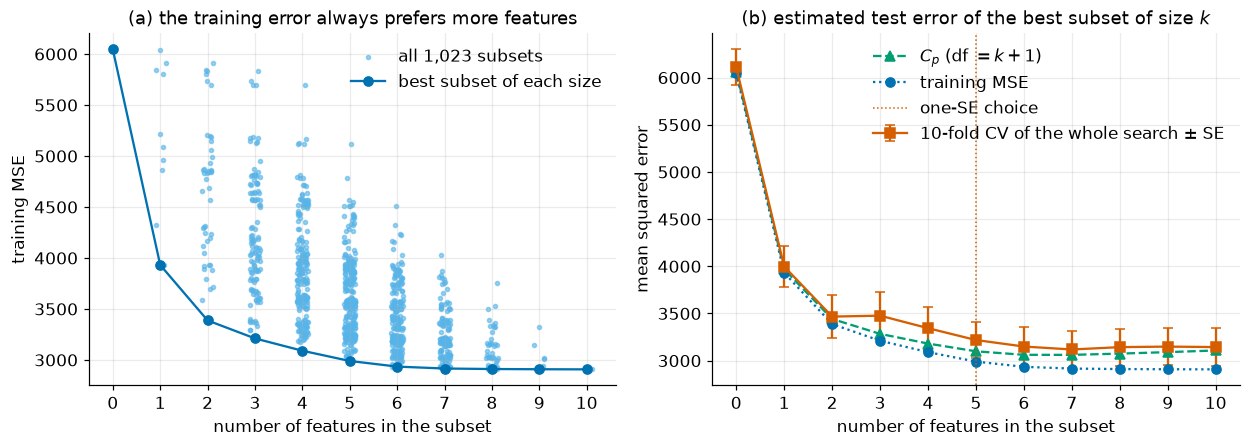

In [7]:
def figure_10_1():
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
    rng = np.random.default_rng(SEED)
    ax = axes[0]
    ax.scatter(size_all + rng.uniform(-0.12, 0.12, len(size_all)), rss_all / n_d, s=7, color=SKY, alpha=0.6, label="all 1,023 subsets")
    ks = np.arange(0, p_d + 1)
    ax.plot(ks, [best_rss[k] / n_d for k in ks], "o-", color=BLUE, label="best subset of each size")
    ax.set(xlabel="number of features in the subset", ylabel="training MSE", title="(a) the training error always prefers more features")
    ax.set_xticks(ks)
    ax.legend(frameon=False)
    ax = axes[1]
    ax.errorbar(ks, cv_mean, yerr=cv_se, fmt="s-", color=VERMILION, capsize=3, label="10-fold CV of the whole search ± SE")
    ax.plot(ks, [cp[k] for k in ks], "^--", color=GREEN, label=r"$C_p$ (df $= k+1$)")
    ax.plot(ks, [best_rss[k] / n_d for k in ks], "o:", color=BLUE, label="training MSE")
    ax.axvline(k_cv_1se, color=VERMILION, ls=":", lw=1, label="one-SE choice")
    ax.set(xlabel="number of features in the subset", ylabel="mean squared error", title="(b) estimated test error of the best subset of size $k$")
    ax.set_xticks(ks)
    ax.legend(frameon=False, loc="upper right")
    fig.tight_layout()
    plt.show()


figure_10_1()

Panel (a) of Figure 10.1 shows how much the choice of the subset matters: with five features the training MSE ranges from $2{,}990$ (the best subset) to about $5{,}100$ (the worst) according to *which* five. Panel (b) compares the three estimates of the error. The cross-validation curve, which repeats the whole search in every fold, drops sharply up to two features and is flat from five to ten: its values ($3{,}218$ at 5, $3{,}118$ at 7, $3{,}143$ at 10) differ by far less than the standard error of each (about $200$). The minimum is at 7 features, the one-standard-error rule (Section 5.4.1) chooses the smallest model within one standard error of it, 5 features (`sex`, `bmi`, `bp`, `s3`, `s5`), and $C_p$ and the BIC choose 7 and 6. All four choices lie between 5 and 7 features, which is the honest summary: on these 331 patients the data say "between five and seven features", not a specific number. The vertical gap between the training MSE and the cross-validated error at ten features is $236$, close to the optimism $2\hat\sigma^2(p+1)/n = 200$ that Proposition 10.2 predicts for a fixed model with 11 parameters (the cross-validation estimate is slightly pessimistic because each fold trains on 90% of the data).

### 10.3.3 Greedy search: forward and backward stepwise selection

When $p$ is too large for the exhaustive search we can build the subset one feature at a time. **Forward stepwise selection** starts from the empty model and, at each step, adds the feature whose inclusion reduces the residual sum of squares the most; **backward elimination** starts from the full model and removes, at each step, the feature whose removal increases it the least. Forward selection needs $p + (p-1) + \dots$ fits, a number quadratic in $p$ instead of $2^p$. The next lemma shows that each step is cheap: no refit is needed to *rank* the candidates.

**Lemma 10.3 (the gain of adding a feature).** Let $\mathbf{r}_S = \mathbf{y} - \mathbf{P}_S\mathbf{y}$ be the residual of the least-squares fit on the columns $S$, and let $j\notin S$ with $\tilde{\mathbf{x}}_j = (\mathbf{I}-\mathbf{P}_S)\mathbf{x}_j\neq\mathbf{0}$ the part of $\mathbf{x}_j$ orthogonal to the columns in $S$. Then
$$
\mathrm{RSS}(S) - \mathrm{RSS}(S\cup\{j\}) = \frac{(\mathbf{x}_j^\top\mathbf{r}_S)^2}{\lVert\tilde{\mathbf{x}}_j\rVert^2}.
$$

:::{admonition} Proof
:class: dropdown
The span of $S\cup\{j\}$ is the orthogonal sum of the span of $S$ and the line through $\tilde{\mathbf{x}}_j$, so $\mathbf{P}_{S\cup\{j\}}\mathbf{y} = \mathbf{P}_S\mathbf{y} + \tilde{\mathbf{x}}_j\tilde{\mathbf{x}}_j^\top\mathbf{y}/\lVert\tilde{\mathbf{x}}_j\rVert^2$, and the residual sum of squares falls by the squared length of the second term, $(\tilde{\mathbf{x}}_j^\top\mathbf{y})^2/\lVert\tilde{\mathbf{x}}_j\rVert^2$. Finally $\tilde{\mathbf{x}}_j^\top\mathbf{y} = \mathbf{x}_j^\top(\mathbf{I}-\mathbf{P}_S)\mathbf{y} = \mathbf{x}_j^\top\mathbf{r}_S$, since $\mathbf{I}-\mathbf{P}_S$ is a symmetric projection. $\square$
:::

The numerator is the correlation of the candidate with the *current residual*, and the denominator discounts a candidate that is almost in the span of the features already chosen. Forward selection is greedy: it never reconsiders a choice, and it can miss the best subset, because the usefulness of a feature depends on the others (Exercise 3.6 had a first example). We compare it with the exhaustive answer.

In [8]:
def forward_selection(Z, y, k_max=None):
    """Forward stepwise selection: returns the features in the order in which they enter (Lemma 10.3)."""
    n, p = Z.shape
    k_max = k_max or p
    S, r = [], y.copy()
    for _ in range(k_max):
        best_j, best_gain = None, -1.0
        for j in range(p):
            if j in S:
                continue
            if S:
                P = Z[:, S] @ np.linalg.pinv(Z[:, S])
                xt = Z[:, j] - P @ Z[:, j]
            else:
                xt = Z[:, j]
            nrm = float(xt @ xt)
            if nrm < 1e-12:
                continue
            gain = float(Z[:, j] @ r) ** 2 / nrm
            if gain > best_gain:
                best_j, best_gain = j, gain
        S.append(best_j)
        b = np.linalg.lstsq(Z[:, S], y, rcond=None)[0]
        r = y - Z[:, S] @ b
    return S


order_fwd = forward_selection(Zd, yc)
rows = []
for k in range(1, p_d + 1):
    Sf = tuple(sorted(order_fwd[:k]))
    rows.append({"size": k, "forward adds": feat[order_fwd[k - 1]],
                 "forward RSS/n": rss_of(Sf, Zd, yc) / n_d, "best RSS/n": best_rss[k] / n_d,
                 "same subset as the best": Sf == tuple(sorted(best_S[k]))})
print(pd.DataFrame(rows).round(1).to_string(index=False))

 size forward adds  forward RSS/n  best RSS/n  same subset as the best
    1          bmi         3931.0      3931.0                     True
    2           s5         3387.1      3387.1                     True
    3           bp         3210.6      3210.6                     True
    4           s3         3089.8      3089.8                     True
    5          sex         2989.5      2989.5                     True
    6           s1         2945.3      2934.3                    False
    7           s4         2931.2      2915.5                    False
    8           s2         2912.9      2910.6                    False
    9          age         2908.3      2908.3                     True
   10           s6         2907.3      2907.3                     True


Forward selection finds the best subset for sizes 1 to 5 and for sizes 9 and 10, and misses it for sizes 6, 7 and 8: the best subsets there require removing `s3`, which entered at step 4, and adding the correlated pair `s1` and `s2`. The loss is small. At size 6 the forward subset has a training MSE of $2{,}945.3$ against $2{,}934.3$ for the best ($0.4\%$ more), and at size 7 $2{,}931.2$ against $2{,}915.5$ ($0.5\%$). Greedy search is a good approximation when the features are not too correlated and the main practical choice when $p$ is large; with correlated features it can commit early to a feature that a pair will later make redundant. (Backward elimination starts from the full model and therefore needs $p<n$.) The criterion of Lemma 10.3 has a cheaper relative, which is the subject of the next section: rank the candidates by their correlation with the residual only.

## 10.4 Orthogonal matching pursuit

### 10.4.1 The algorithm

Forward selection ranks the candidates by the *gain* of Lemma 10.3. **Orthogonal matching pursuit** (OMP), a method from signal processing (Pati, Rezaiifar and Krishnaprasad, 1993; Tropp, 2004), ranks them by the simpler quantity $\lvert\mathbf{x}_j^\top\mathbf{r}\rvert$, the correlation of the feature with the current residual, without dividing by $\lVert\tilde{\mathbf{x}}_j\rVert$. After each choice the coefficients of *all* the selected features are refitted by least squares (this is the "orthogonal" part: the residual is always orthogonal to the selected columns).

:::{admonition} Algorithm (orthogonal matching pursuit)
:class: tip
Start with $S = \varnothing$ and $\mathbf{r} = \mathbf{y}$. Repeat $s$ times:
1. choose $j^\ast = \arg\max_{j\notin S}\lvert\mathbf{x}_j^\top\mathbf{r}\rvert$ and set $S\leftarrow S\cup\{j^\ast\}$;
2. fit least squares on the columns in $S$ and set $\mathbf{r} = \mathbf{y} - \mathbf{P}_S\mathbf{y}$.
Return $S$ and the least-squares coefficients on $S$.
:::

For columns with the same norm and nearly orthogonal to each other the two rules coincide, since then $\lVert\tilde{\mathbf{x}}_j\rVert\approx\lVert\mathbf{x}_j\rVert$; they differ when a candidate is almost explained by the selected features, which forward selection discounts and OMP does not. The cost of a step is one product $\mathbf{X}^\top\mathbf{r}$ and a small least-squares problem, so OMP is the cheapest of the selection methods, and it is the method for which the cleanest guarantees exist.

In [9]:
def omp(Z, y, s):
    """Orthogonal matching pursuit: indices in order of entry and the least-squares coefficients on them."""
    S, r = [], y.copy()
    for _ in range(s):
        c = np.abs(Z.T @ r)
        c[S] = -1.0
        S.append(int(np.argmax(c)))
        b = np.linalg.lstsq(Z[:, S], y, rcond=None)[0]
        r = y - Z[:, S] @ b
    return S, b


order_omp, _ = omp(Zd, yc, p_d)
sk = OrthogonalMatchingPursuit(n_nonzero_coefs=4, fit_intercept=False).fit(Zd, yc)
print("OMP order      :", [feat[j] for j in order_omp])
print("forward order  :", [feat[j] for j in order_fwd])
print("first four, ours vs scikit-learn:", sorted(order_omp[:4]) == sorted(np.flatnonzero(sk.coef_)))

OMP order      : ['bmi', 's5', 'bp', 's3', 'sex', 's2', 'age', 's6', 's4', 's1']
forward order  : ['bmi', 's5', 'bp', 's3', 'sex', 's1', 's4', 's2', 'age', 's6']
first four, ours vs scikit-learn: True


The three methods enter the same five features in the same order (`bmi`, `s5`, `bp`, `s3`, `sex`), and the first four are the best subset of size 4 found by the exhaustive search; they differ at the sixth step, where forward selection adds `s1` (the feature whose *gain* is the largest once the others are in) and OMP adds `s2` (the one most correlated with the residual). OMP leaves `s1` for the very last step, because it is almost a combination of `s2` and the other features (the correlation of the two is $0.89$), and our implementation agrees with the one in scikit-learn.

### 10.4.2 When does it find the true features?

Suppose that the truth is $\mathbf{y} = \mathbf{X}_{S^\ast}\mathbf{w}^\ast$ with $\lvert S^\ast\rvert = s$ and no noise. When does OMP select the features of $S^\ast$, and nothing else, in $s$ steps? The answer depends on how well the *wrong* features can be mimicked by the right ones. We assume that the columns have unit norm, $\lVert\mathbf{x}_j\rVert = 1$, and that the columns in $S^\ast$ are linearly independent. Let $\mathbf{X}_S^+ = (\mathbf{X}_S^\top\mathbf{X}_S)^{-1}\mathbf{X}_S^\top$ be the pseudo-inverse of the columns in $S$.

:::{admonition} Theorem 10.4 (exact recovery by OMP, noiseless case)
:class: tip
If
$$
\max_{j\notin S^\ast}\ \lVert\mathbf{X}_{S^\ast}^+\mathbf{x}_j\rVert_1 < 1
\tag{10.3}$$
(the **exact recovery condition**, ERC), then OMP selects only features of $S^\ast$ and, after $s$ steps, returns exactly $S^\ast$ and $\mathbf{w}^\ast$, for every $\mathbf{w}^\ast$ supported on $S^\ast$.
:::

The quantity in (10.3) is the $\ell_1$ norm of the coefficients of the regression of the wrong feature $\mathbf{x}_j$ on the right ones. If it is below one, no wrong feature can be built from the right ones with enough weight to look better than the right ones.

:::{admonition} Proof
:class: dropdown
Suppose that at some step OMP has selected a subset $T\subset S^\ast$ (true at the beginning, when $T=\varnothing$), with $T\neq S^\ast$. The residual is $\mathbf{r} = (\mathbf{I}-\mathbf{P}_T)\mathbf{X}_{S^\ast}\mathbf{w}^\ast$, which is the projection of a vector of $\operatorname{span}(\mathbf{X}_{S^\ast})$ on a subspace of it, so $\mathbf{r}\in\operatorname{span}(\mathbf{X}_{S^\ast})$, and $\mathbf{r}\neq\mathbf{0}$ because the columns of $S^\ast$ are independent and some coefficient of $S^\ast\setminus T$ is non-zero (if some of them are zero, replace $S^\ast$ by the support of $\mathbf{w}^\ast$ in the argument). Since $\mathbf{r}$ is in the span of $\mathbf{X}_{S^\ast}$ we can write $\mathbf{r} = \mathbf{X}_{S^\ast}(\mathbf{X}_{S^\ast}^\top\mathbf{X}_{S^\ast})^{-1}\mathbf{X}_{S^\ast}^\top\mathbf{r}$, and for any $j\notin S^\ast$
$$
\mathbf{x}_j^\top\mathbf{r} = \big(\mathbf{X}_{S^\ast}^+\mathbf{x}_j\big)^\top\big(\mathbf{X}_{S^\ast}^\top\mathbf{r}\big),\qquad\text{so}\qquad\lvert\mathbf{x}_j^\top\mathbf{r}\rvert\le\lVert\mathbf{X}_{S^\ast}^+\mathbf{x}_j\rVert_1\,\lVert\mathbf{X}_{S^\ast}^\top\mathbf{r}\rVert_\infty < \lVert\mathbf{X}_{S^\ast}^\top\mathbf{r}\rVert_\infty = \max_{i\in S^\ast}\lvert\mathbf{x}_i^\top\mathbf{r}\rvert,
$$
using Hölder's inequality and (10.3); the strict inequality holds because $\lVert\mathbf{X}_{S^\ast}^\top\mathbf{r}\rVert_\infty > 0$ (otherwise $\mathbf{r}$ would be orthogonal to its own span, hence zero). The maximum on the right is attained at some $i\in S^\ast$, and $i\notin T$ because the residual is orthogonal to the selected columns, so $\mathbf{x}_i^\top\mathbf{r} = 0$ for $i\in T$. Hence the best candidate is a true feature not yet selected. By induction, after $s$ steps $T = S^\ast$, and least squares on $S^\ast$ recovers $\mathbf{w}^\ast$ exactly because the data are noiseless. $\square$
:::

The condition (10.3) involves $S^\ast$, which we do not know. A condition on the data alone, valid for *every* $S^\ast$ of a given size, is obtained from the **mutual coherence** $\mu = \max_{i\ne j}\lvert\mathbf{x}_i^\top\mathbf{x}_j\rvert$ of the unit-norm columns.

**Corollary 10.5.** If $\mu(2s-1) < 1$, then the ERC holds for every support of size $s$, and OMP recovers every $s$-sparse noiseless signal.

:::{admonition} Proof
:class: dropdown
Let $\mathbf{G} = \mathbf{X}_{S}^\top\mathbf{X}_{S} = \mathbf{I} + \mathbf{E}$ with $\lvert S\rvert = s$. The off-diagonal entries of $\mathbf{E}$ are at most $\mu$ in absolute value, so every column of $\mathbf{E}$ has $\ell_1$ norm at most $(s-1)\mu<1$, and the Neumann series gives $\lVert\mathbf{G}^{-1}\rVert_{1\to1}\le 1/(1-(s-1)\mu)$, where $\lVert\cdot\rVert_{1\to1}$ is the largest absolute column sum, the operator norm for the $\ell_1$ norm. For $j\notin S$ the vector $\mathbf{X}_S^\top\mathbf{x}_j$ has $s$ entries of absolute value at most $\mu$, so $\lVert\mathbf{X}_S^\top\mathbf{x}_j\rVert_1\le s\mu$. Therefore $\lVert\mathbf{X}_S^+\mathbf{x}_j\rVert_1 = \lVert\mathbf{G}^{-1}\mathbf{X}_S^\top\mathbf{x}_j\rVert_1\le s\mu/(1-(s-1)\mu)$, which is below one if and only if $s\mu < 1-(s-1)\mu$, that is, $(2s-1)\mu<1$. $\square$
:::

The corollary says that OMP can recover $s$ features if the features are nearly orthogonal, in the sense that $\mu<1/(2s-1)$. For $s = 5$ this needs $\mu<1/9$, and for *random* unit vectors in $\mathbb{R}^n$ the coherence is of order $\sqrt{2\ln p/n}$, so the condition holds when $n\gtrsim s^2\ln p$. That is conservative: the experiment below shows that $n$ of order $s\ln p$ is enough in practice. On *real* data the condition is hopeless, because real features are correlated:

In [10]:
Gram = Zd.T @ Zd / n_d
np.fill_diagonal(Gram, 0.0)
mu_coh = np.abs(Gram).max()
i_, j_ = np.unravel_index(np.abs(Gram).argmax(), Gram.shape)
print(f"coherence of the 10 standardized Diabetes features: {mu_coh:.3f} (features {feat[i_]} and {feat[j_]})")
print(f"Corollary 10.5 would need mu < 1/(2s-1): s = 1 -> {1:.0f}, s = 2 -> {1/3:.2f}, s = 3 -> {1/5:.2f}")


def erc_value(Z, S):
    """The left-hand side of (10.3) for the support S (columns normalized to unit norm)."""
    U = Z / np.linalg.norm(Z, axis=0)
    P = np.linalg.pinv(U[:, list(S)])
    return max(np.abs(P @ U[:, j]).sum() for j in range(U.shape[1]) if j not in S)


print("ERC value for S = {bmi}      :", round(erc_value(Zd, [feat.index("bmi")]), 3))
print("ERC value for S = {bmi, s5}  :", round(erc_value(Zd, [feat.index("bmi"), feat.index("s5")]), 3))
print("ERC value for S = {bmi, bp, s3, s5}:", round(erc_value(Zd, [feat.index(f) for f in ["bmi", "bp", "s3", "s5"]]), 3))

coherence of the 10 standardized Diabetes features: 0.893 (features s1 and s2)
Corollary 10.5 would need mu < 1/(2s-1): s = 1 -> 1, s = 2 -> 0.33, s = 3 -> 0.20
ERC value for S = {bmi}      : 0.451
ERC value for S = {bmi, s5}  : 0.72
ERC value for S = {bmi, bp, s3, s5}: 1.02


The coherence of the Diabetes features is $0.893$ (the pair `s1`, `s2`), so Corollary 10.5 gives a guarantee only for $s=1$ (it needs $\mu<1$) and none for $s\ge 2$ (it needs $\mu<1/3$, $1/5$, ...). The exact recovery condition (10.3), computed for particular supports, is more informative: it holds for $S^\ast=\{\texttt{bmi}\}$ ($0.45$) and for $S^\ast=\{\texttt{bmi},\texttt{s5}\}$ ($0.72$), and just fails for the four-feature support $\{\texttt{bmi},\texttt{bp},\texttt{s3},\texttt{s5}\}$ ($1.02$): the remaining features can be assembled from those four with total weight larger than one. (Real data have no "true support", and the conditions are sufficient, not necessary: OMP did select those four features first. The point is that guarantees of this kind describe nearly orthogonal designs, and real features are correlated.)

### 10.4.3 An experiment: recovering a known support

To test the theory we need a world where the support is known, so the next experiment is **constructed**: a Gaussian design with $p = 100$ features, a true support of $s = 5$ features chosen at random with weights of random sign and magnitude between 1 and 2, and no noise (the setting of Theorem 10.4). For each number of examples $n$ and 200 random worlds we ask whether the method finds the exact support. For OMP we run $s$ steps. For the lasso, which we define in the next section, we follow its whole regularization path (computed exactly by the LARS algorithm, Section 10.5.5) and ask whether *some* value of the penalty gives exactly the true support: a generous criterion, which gives the lasso the benefit of an oracle for the choice of $\lambda$.

In [11]:
def recovery_experiment(ns, p=100, s=5, reps=200, seed=SEED):
    rng = np.random.default_rng(seed)
    out = {"OMP": [], "lasso path (best lambda)": []}
    for n in ns:
        ok_omp = ok_las = 0
        for _ in range(reps):
            X = rng.normal(size=(n, p))
            X /= np.linalg.norm(X, axis=0)                      # unit-norm columns, as in Theorem 10.4
            S0 = set(rng.choice(p, s, replace=False).tolist())
            w = np.zeros(p)
            w[list(S0)] = rng.choice([-1, 1], s) * (1 + rng.random(s))
            y = X @ w
            ok_omp += set(omp(X, y, s)[0]) == S0
            _, _, coefs = lars_path(X, y, method="lasso")
            ok_las += any(set(np.flatnonzero(np.abs(coefs[:, k]) > 1e-10).tolist()) == S0 for k in range(coefs.shape[1]))
        out["OMP"].append(ok_omp / reps)
        out["lasso path (best lambda)"].append(ok_las / reps)
    return out


ns_rec = [10, 15, 20, 25, 30, 40, 50, 60]
t0 = time.time()
rec = recovery_experiment(ns_rec)
print(pd.DataFrame({"n": ns_rec, **rec}).round(2).to_string(index=False))
print(f"({time.time() - t0:.0f} s)")

 n  OMP  lasso path (best lambda)
10 0.00                      0.02
15 0.02                      0.20
20 0.18                      0.60
25 0.58                      0.94
30 0.73                      1.00
40 0.96                      1.00
50 0.98                      1.00
60 1.00                      1.00
(1 s)


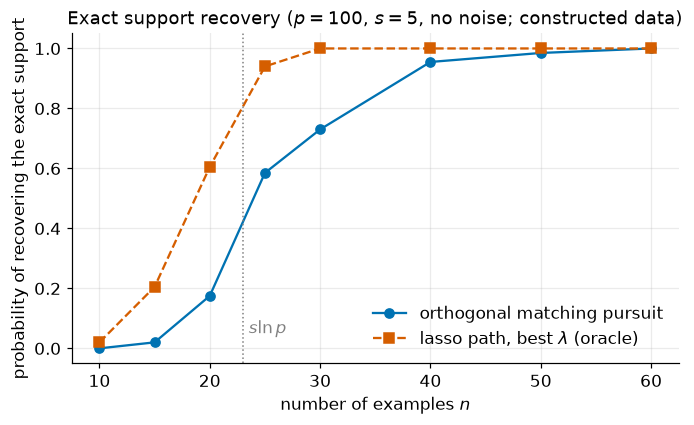

In [12]:
def figure_10_2():
    fig, ax = plt.subplots(figsize=(6.4, 4.0))
    ax.plot(ns_rec, rec["OMP"], "o-", color=BLUE, label="orthogonal matching pursuit")
    ax.plot(ns_rec, rec["lasso path (best lambda)"], "s--", color=VERMILION, label=r"lasso path, best $\lambda$ (oracle)")
    ax.axvline(5 * np.log(100), color="gray", ls=":", lw=1)
    ax.text(5 * np.log(100) + 0.5, 0.05, r"$s\ln p$", color="gray")
    ax.set(xlabel="number of examples $n$", ylabel="probability of recovering the exact support",
           title="Exact support recovery ($p=100$, $s=5$, no noise; constructed data)")
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()


figure_10_2()

Figure 10.2 shows a sharp transition from failure to success as $n$ grows, for both methods. OMP recovers the support in $58\%$ of the worlds at $n=25$ and in $96\%$ at $n=40$; the lasso path, with the oracle choice of $\lambda$, in $94\%$ at $n=25$ and in all the worlds from $n=30$. Both transitions happen at a small multiple of $s\ln p = 23$, not at $s^2\ln p\approx 115$ that the coherence condition of Corollary 10.5 would require: the corollary is a sufficient condition, and a conservative one. In this experiment the convex method needs fewer examples than the greedy one, but we gave it the oracle value of $\lambda$; choosing $\lambda$ from the data is a harder problem, which we take up in Section 10.7.

## 10.5 The lasso

### 10.5.1 From the count to the $\ell_1$ norm

Greedy methods are fast but have no certificate of optimality. A different route is to replace the non-convex count $\lVert\mathbf{w}\rVert_0$ by the closest convex function, the $\ell_1$ norm $\lVert\mathbf{w}\rVert_1 = \sum_j\lvert w_j\rvert$ (it is the convex envelope of $\lVert\cdot\rVert_0$ on the cube $[-1,1]^p$). The resulting estimator was introduced by Tibshirani (1996) with the name **lasso** (least absolute shrinkage and selection operator), and, in the signal-processing literature, as *basis pursuit denoising* (Chen, Donoho and Saunders, 1998).

:::{admonition} Definition 10.2 (the lasso)
:class: tip
For $\lambda\ge 0$ the lasso estimator is
$$
\hat{\mathbf{w}}_\lambda\in\arg\min_{\mathbf{w}\in\mathbb{R}^p}\ F_\lambda(\mathbf{w}),\qquad F_\lambda(\mathbf{w}) = \frac{1}{2n}\lVert\mathbf{y}-\mathbf{X}\mathbf{w}\rVert^2 + \lambda\lVert\mathbf{w}\rVert_1,
\tag{10.4}$$
for centered $\mathbf{y}$ and standardized columns of $\mathbf{X}$ (the intercept is the mean of $\mathbf{y}$ and is not penalized, as in Lemma 6.3). This is the parametrization of scikit-learn, where $\lambda$ is called `alpha`. The equivalent **constrained** form minimizes $\frac{1}{2n}\lVert\mathbf{y}-\mathbf{X}\mathbf{w}\rVert^2$ subject to $\lVert\mathbf{w}\rVert_1\le t$.
:::

The problem is convex (a convex quadratic plus a norm) but not differentiable at the points where a coordinate is zero, which is exactly where the interesting solutions live. The penalized and the constrained form are equivalent in the usual sense of Lagrangian duality: for each $\lambda$ there is a $t$ with the same solution (and conversely). The geometry explains why the solution has zeros. In the constrained form, the least-squares solution $\hat{\mathbf{w}}_{\mathrm{OLS}}$ is the center of elliptical contours of the training error, and the solution is the first point of the constraint set that the growing ellipses touch. The $\ell_2$ ball is round, and the contact point has, in general, all coordinates non-zero; the $\ell_1$ ball has *corners* on the coordinate axes, which stick out, and the ellipses are likely to touch it at a corner, where some coordinates are exactly zero. We draw it with two real features of the Diabetes data, the body mass index and the age (the contours are those of the actual training error; the size of the ball is $60\%$ of the $\ell_1$ or $\ell_2$ norm of the least-squares solution).

In [13]:
from scipy.optimize import brentq

pair = [feat.index("bmi"), feat.index("age")]
A2 = Zd[:, pair]
w_ols2 = np.linalg.lstsq(A2, yc, rcond=None)[0]


def lasso_at_fraction(fraction):
    """Lasso on the pair with ||w||_1 = fraction * ||w_ols||_1 (bisection on lambda)."""
    target = fraction * np.abs(w_ols2).sum()
    f = lambda lam: np.abs(Lasso(alpha=lam, fit_intercept=False, tol=1e-12, max_iter=100000).fit(A2, yc).coef_).sum() - target
    lam = brentq(f, 1e-6, 100.0)
    return Lasso(alpha=lam, fit_intercept=False, tol=1e-12, max_iter=100000).fit(A2, yc).coef_


def ridge_at_fraction(fraction):
    target = fraction * np.linalg.norm(w_ols2)
    f = lambda lam: np.linalg.norm(Ridge(alpha=lam, fit_intercept=False).fit(A2, yc).coef_) - target
    lam = brentq(f, 1e-8, 1e6)
    return Ridge(alpha=lam, fit_intercept=False).fit(A2, yc).coef_


w_las2, w_rid2 = lasso_at_fraction(0.6), ridge_at_fraction(0.6)
print("least squares (bmi, age):", np.round(w_ols2, 2))
print("lasso, 60% of the l1 norm:", np.round(w_las2, 2), "(age is exactly zero)" if w_las2[1] == 0 else "")
print("ridge, 60% of the l2 norm:", np.round(w_rid2, 2))

least squares (bmi, age): [44.65  7.32]
lasso, 60% of the l1 norm: [31.18  0.  ] (age is exactly zero)
ridge, 60% of the l2 norm: [26.42  6.26]


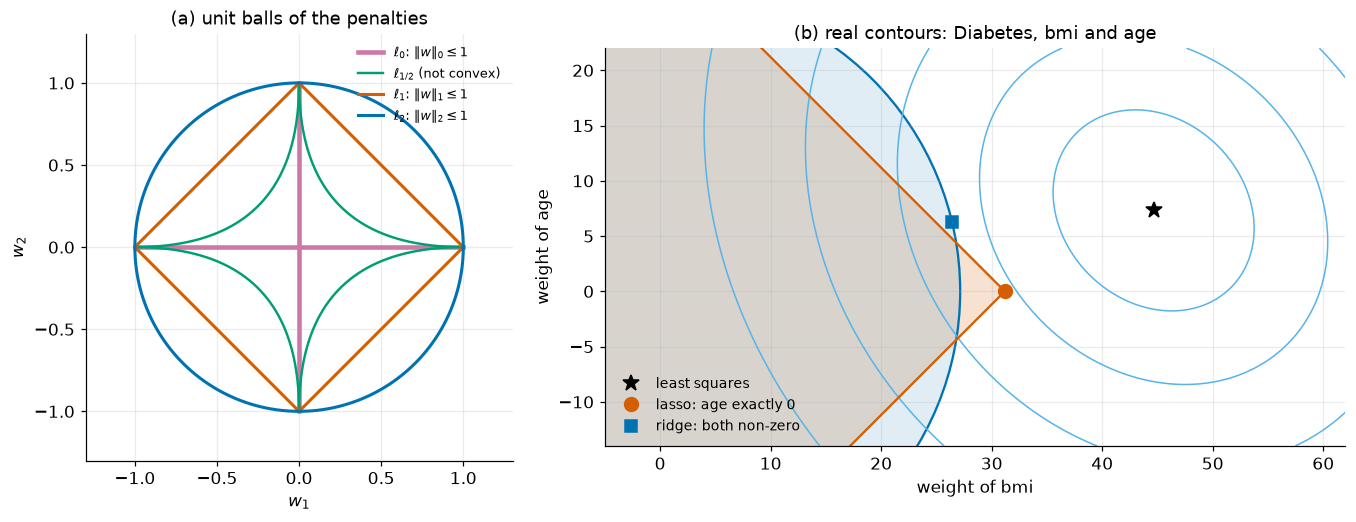

In [14]:
def figure_10_3():
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"width_ratios": [1, 1.7]})
    ax = axes[0]
    th = np.linspace(0, 2 * np.pi, 400)
    ax.plot([-1, 1], [0, 0], color=PURPLE, lw=3, label=r"$\ell_0$: $\|w\|_0\leq 1$")
    ax.plot([0, 0], [-1, 1], color=PURPLE, lw=3)
    q = 0.5
    t = np.linspace(-1, 1, 801)
    ax.plot(t, (1 - np.abs(t) ** q) ** (1 / q), color=GREEN, lw=1.6, label=r"$\ell_{1/2}$ (not convex)")
    ax.plot(t, -(1 - np.abs(t) ** q) ** (1 / q), color=GREEN, lw=1.6)
    ax.plot([1, 0, -1, 0, 1], [0, 1, 0, -1, 0], color=VERMILION, lw=2, label=r"$\ell_1$: $\|w\|_1\leq 1$")
    ax.plot(np.cos(th), np.sin(th), color=BLUE, lw=2, label=r"$\ell_2$: $\|w\|_2\leq 1$")
    ax.set(xlim=(-1.3, 1.3), ylim=(-1.3, 1.3), aspect="equal", xlabel=r"$w_1$", ylabel=r"$w_2$", title="(a) unit balls of the penalties")
    ax.legend(frameon=False, loc="upper right", fontsize=8.5)
    ax = axes[1]
    g1, g2 = np.meshgrid(np.linspace(-5, 62, 300), np.linspace(-14, 22, 300))
    W = np.stack([g1, g2], axis=-1)
    resid = yc[:, None, None] - np.tensordot(A2, W, axes=([1], [2]))
    loss = (resid ** 2).sum(axis=0) / (2 * n_d)
    ax.contour(g1, g2, loss, levels=np.sort(loss.min() + np.array([40, 120, 260, 480, 800])), colors=SKY, linewidths=1)
    r1 = 0.6 * np.abs(w_ols2).sum()
    ax.fill([r1, 0, -r1, 0], [0, r1, 0, -r1], color=VERMILION, alpha=0.18)
    ax.plot([r1, 0, -r1, 0, r1], [0, r1, 0, -r1, 0], color=VERMILION, lw=1.5)
    r2 = 0.6 * np.linalg.norm(w_ols2)
    ax.add_patch(plt.Circle((0, 0), r2, color=BLUE, alpha=0.12))
    ax.add_patch(plt.Circle((0, 0), r2, fill=False, color=BLUE, lw=1.5))
    ax.plot(*w_ols2, "k*", ms=11, label="least squares")
    ax.plot(*w_las2, "o", color=VERMILION, ms=9, label="lasso: age exactly 0")
    ax.plot(*w_rid2, "s", color=BLUE, ms=8, label="ridge: both non-zero")
    ax.set(xlim=(-5, 62), ylim=(-14, 22), aspect="equal", xlabel=r"weight of bmi", ylabel=r"weight of age", title="(b) real contours: Diabetes, bmi and age")
    ax.legend(frameon=False, loc="lower left", fontsize=9)
    fig.tight_layout()
    plt.show()


figure_10_3()

Panel (a) of Figure 10.3 shows the unit balls. The "$\ell_0$ ball" is the cross formed by the two axes; the $\ell_{1/2}$ ball is a non-convex star that hugs the cross; the $\ell_1$ ball is the diamond with corners on the axes, the smallest convex set that contains the cross; the $\ell_2$ ball is round. Panel (b) uses real contours. The least-squares solution (star) gives $44.7$ to the body mass index and $7.3$ to the age. With $60\%$ of the norm, the lasso solution is $(31.2, 0)$, exactly at the corner of the diamond on the axis of the body mass index: the age is eliminated. The ridge solution is $(26.4, 6.3)$, on the circle, with both weights non-zero. The corner is not a certainty (with a different orientation of the ellipses, or a larger budget, the contact would be on an edge, and both weights would be non-zero), but the geometry shows why zeros are *typical* for the $\ell_1$ ball and *impossible* in general for the $\ell_2$ ball; in $p$ dimensions the $\ell_1$ ball has $2p$ corners and many low-dimensional faces, so the ellipses meet it at a point with many zero coordinates with positive probability.

### 10.5.2 The orthonormal case: soft-thresholding

When the columns are orthonormal in the sense $\frac1n\mathbf{X}^\top\mathbf{X} = \mathbf{I}$, the lasso has a closed form, and it shows in one line the difference between the three ways of penalizing. With $\hat w^{\mathrm{OLS}}_j = \frac1n\mathbf{x}_j^\top\mathbf{y}$ the least-squares coefficients, the objective separates into $p$ one-dimensional problems, since $\frac1{2n}\lVert\mathbf{y}-\mathbf{X}\mathbf{w}\rVert^2 = \text{const} + \frac12\sum_j(w_j-\hat w_j^{\mathrm{OLS}})^2$.

**Proposition 10.6 (soft-thresholding).** For $\frac1n\mathbf{X}^\top\mathbf{X}=\mathbf{I}$ the lasso solution is $\hat w_j = S_\lambda(\hat w_j^{\mathrm{OLS}})$ with the **soft-thresholding** operator
$$
S_\lambda(z) = \operatorname{sign}(z)\,\max(\lvert z\rvert - \lambda, 0) = \begin{cases} z - \lambda & z>\lambda,\\ 0 & \lvert z\rvert\le\lambda,\\ z+\lambda & z<-\lambda.\end{cases}
$$
For comparison, ridge gives $\hat w_j^{\mathrm{OLS}}/(1+\lambda)$ (the same shrinkage factor for every coordinate), and best subset with $s$ non-zeros keeps the $s$ coordinates of largest $\lvert\hat w_j^{\mathrm{OLS}}\rvert$ unchanged and sets the others to zero (**hard thresholding**).

:::{admonition} Proof
:class: dropdown
We minimize $h(w) = \frac12(w-z)^2 + \lambda\lvert w\rvert$ over $w\in\mathbb{R}$, with $z = \hat w^{\mathrm{OLS}}_j$. The function is strictly convex, so it has a unique minimizer, characterized by $0\in\partial h(w)$, where $\partial\lvert w\rvert = \{\operatorname{sign}(w)\}$ if $w\ne0$ and $[-1,1]$ if $w=0$. If $w>0$ the condition is $w - z + \lambda = 0$, that is, $w = z-\lambda$, valid when $z>\lambda$. If $w<0$ it is $w = z+\lambda$, valid when $z<-\lambda$. If $w=0$ it requires $-z + \lambda g = 0$ for some $g\in[-1,1]$, that is, $\lvert z\rvert\le\lambda$. These three cases cover all $z$ and give $S_\lambda(z)$. The ridge case is $\min\frac12(w-z)^2+\frac\lambda2w^2$, with derivative $w-z+\lambda w=0$. For the best subset, the reduction of the residual sum of squares from including coordinate $j$ is $\frac n2(\hat w_j^{\mathrm{OLS}})^2$, so the best $s$ coordinates are the largest in absolute value. $\square$
:::

*Worked example 10.1 (by hand).* Let $\frac1n\mathbf{X}^\top\mathbf{X}=\mathbf{I}$ with $p=4$ and least-squares coefficients $\hat{\mathbf{w}}^{\mathrm{OLS}} = (3.0,\,-1.5,\,0.4,\,-0.2)$. With $\lambda = 0.5$, soft-thresholding gives $(2.5,\,-1.0,\,0,\,0)$: the two large coefficients are shrunk by $0.5$ and the two small ones are eliminated. Ridge with the same $\lambda$ gives $\hat{\mathbf{w}}^{\mathrm{OLS}}/1.5 = (2.0,\,-1.0,\,0.27,\,-0.13)$: all four remain, none exactly zero. Best subset with $s=2$ gives $(3.0,\,-1.5,\,0,\,0)$: the same support as the lasso, without the shrinkage. *Check with the code below.*

In [15]:
def soft(z, lam):
    return np.sign(z) * np.maximum(np.abs(z) - lam, 0.0)


z_ex = np.array([3.0, -1.5, 0.4, -0.2])
lam_ex = 0.5
hard_ex = np.where(np.argsort(np.argsort(-np.abs(z_ex))) < 2, z_ex, 0.0)
print("least squares :", z_ex)
print("lasso (soft)  :", soft(z_ex, lam_ex))
print("ridge         :", np.round(z_ex / (1 + lam_ex), 2))
print("best subset s=2 (hard):", hard_ex)

# The same formulas against scikit-learn on an exactly orthonormal design (QR of a random matrix; constructed).
rng = np.random.default_rng(SEED)
Q, _ = np.linalg.qr(rng.normal(size=(200, 6)))
Xo = Q * np.sqrt(200)                                     # X^T X / n = I
yo = Xo @ np.array([2.0, -1.0, 0.5, 0.0, 0.0, 0.0]) + rng.normal(size=200)
yo = yo - yo.mean()
w_ols_o = Xo.T @ yo / 200
for lam in [0.1, 0.4]:
    w_sk = Lasso(alpha=lam, fit_intercept=False, tol=1e-12).fit(Xo, yo).coef_
    print(f"lambda = {lam}: max |scikit-learn - soft-thresholding| = {np.abs(w_sk - soft(w_ols_o, lam)).max():.1e}")

least squares : [ 3.  -1.5  0.4 -0.2]
lasso (soft)  : [ 2.5 -1.   0.  -0. ]
ridge         : [ 2.   -1.    0.27 -0.13]
best subset s=2 (hard): [ 3.  -1.5  0.   0. ]
lambda = 0.1: max |scikit-learn - soft-thresholding| = 5.6e-16
lambda = 0.4: max |scikit-learn - soft-thresholding| = 4.4e-16


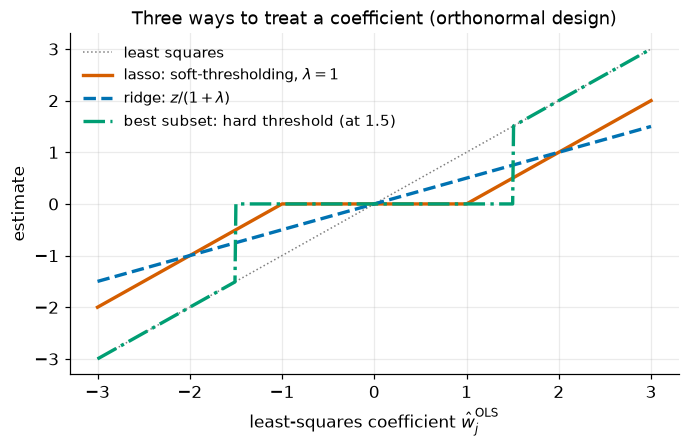

In [16]:
def figure_10_4():
    z = np.linspace(-3, 3, 601)
    lam = 1.0
    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    ax.plot(z, z, color="gray", lw=1, ls=":", label="least squares")
    ax.plot(z, soft(z, lam), color=VERMILION, lw=2.2, label=r"lasso: soft-thresholding, $\lambda=1$")
    ax.plot(z, z / (1 + lam), color=BLUE, lw=2.2, ls="--", label=r"ridge: $z/(1+\lambda)$")
    ax.plot(z, np.where(np.abs(z) > 1.5, z, 0.0), color=GREEN, lw=2.2, ls="-.", label="best subset: hard threshold (at 1.5)")
    ax.set(xlabel=r"least-squares coefficient $\hat w^{\rm OLS}_j$", ylabel="estimate", title="Three ways to treat a coefficient (orthonormal design)")
    ax.legend(frameon=False, fontsize=9.5)
    fig.tight_layout()
    plt.show()


figure_10_4()

Figure 10.4 contrasts the three treatments of a coefficient. The lasso is zero on $[-\lambda,\lambda]$ and shifted towards zero by $\lambda$ outside: it is *continuous* and sparse, and its bias for large coefficients is the constant $\lambda$. Ridge shrinks proportionally and never gives zero. The hard threshold of best-subset selection has no bias for the coefficients that it keeps, but it is *discontinuous*: a small change in the data can move a coefficient from $0$ to $1.5$, which makes the selected model unstable. The lasso is the only one of the three that is both sparse and continuous in the data, and it is the one that is a convex problem in the general case. The code checks that scikit-learn's solver agrees with soft-thresholding on an orthonormal design to machine precision ($5\times10^{-16}$).

### 10.5.3 Optimality conditions

For a general design there is no closed form, but the same subgradient argument gives a complete characterization of the solutions. Write $\mathbf{r} = \mathbf{y}-\mathbf{X}\mathbf{w}$ for the residual.

**Theorem 10.7 (optimality conditions of the lasso).** A vector $\mathbf{w}$ minimizes $F_\lambda$ if and only if, for every coordinate $j$,
$$
\frac1n\mathbf{x}_j^\top\mathbf{r} = \lambda\operatorname{sign}(w_j)\ \text{ if } w_j\neq 0,\qquad\Big\lvert\frac1n\mathbf{x}_j^\top\mathbf{r}\Big\rvert\le\lambda\ \text{ if } w_j = 0.
\tag{10.5}$$
In words: every feature that is *in* the model has the same absolute correlation $\lambda$ with the residual, and every feature that is *out* has a correlation at most $\lambda$. In particular $\hat{\mathbf{w}}_\lambda = \mathbf{0}$ if and only if $\lambda\ge\lambda_{\max} = \frac1n\lVert\mathbf{X}^\top\mathbf{y}\rVert_\infty$.

:::{admonition} Proof
:class: dropdown
The function $F_\lambda$ is convex, so $\mathbf{w}$ is a minimizer if and only if $\mathbf{0}\in\partial F_\lambda(\mathbf{w})$. The first term is differentiable with gradient $-\frac1n\mathbf{X}^\top\mathbf{r}$, and the subdifferential of a sum of a differentiable convex function and a convex function is the sum of the gradient and the subdifferential, so $\partial F_\lambda(\mathbf{w}) = -\frac1n\mathbf{X}^\top\mathbf{r} + \lambda\,\partial\lVert\mathbf{w}\rVert_1$. The subdifferential of the $\ell_1$ norm is the product of the sets $\{\operatorname{sign}(w_j)\}$ (if $w_j\ne0$) and $[-1,1]$ (if $w_j=0$); the condition $\mathbf{0}\in\partial F_\lambda(\mathbf{w})$ coordinate by coordinate is (10.5). For $\mathbf{w}=\mathbf{0}$ the residual is $\mathbf{y}$ and (10.5) reads $\lvert\frac1n\mathbf{x}_j^\top\mathbf{y}\rvert\le\lambda$ for all $j$. $\square$
:::

The value $\lambda_{\max}$ is the natural starting point of the regularization path: for larger values the model is empty, and as $\lambda$ decreases the feature that is the most correlated with $\mathbf{y}$ enters first (it is the first to reach the correlation $\lambda$). Two properties of the solution are worth knowing and are left to the exercises. The *fitted values* $\mathbf{X}\hat{\mathbf{w}}_\lambda$ are always unique (Exercise 10.5), even if the weights are not: with two identical columns, any split of the weight between them has the same fit and the same penalty (Exercise 10.3). The weights are unique when the columns are in "general position" (no $n+1$ columns on a common affine subspace, Tibshirani, 2013), which holds with probability one for continuous data, and then the solution has at most $\min(n,p)$ non-zero entries. We check (10.5) on the Diabetes data with the solution of scikit-learn.

In [17]:
lam_ex2 = 1.0
w_las = Lasso(alpha=lam_ex2, fit_intercept=False, tol=1e-14, max_iter=200000).fit(Zd, yc).coef_
corr_res = Zd.T @ (yc - Zd @ w_las) / n_d
lam_max_d = np.abs(Zd.T @ yc).max() / n_d
print(f"lambda_max = {lam_max_d:.3f} (first feature to enter: {feat[int(np.abs(Zd.T @ yc).argmax())]})")
print(pd.DataFrame({"feature": feat, "weight": w_las, "x_j' r / n": corr_res,
                    "|x_j' r / n| - lambda": np.abs(corr_res) - lam_ex2}).round(4).to_string(index=False))
inside = w_las != 0
print("max |x_j' r / n - lambda sign(w_j)| over the active features:", f"{np.abs(corr_res[inside] - lam_ex2 * np.sign(w_las[inside])).max():.1e}")
print("max |x_j' r / n| over the inactive features, against lambda:", f"{np.abs(corr_res[~inside]).max():.4f} <= {lam_ex2}")

lambda_max = 45.974 (first feature to enter: bmi)
feature   weight  x_j' r / n  |x_j' r / n| - lambda
    age   1.1998      1.0000                -0.0000
    sex  -9.3015     -1.0000                -0.0000
    bmi  25.6637      1.0000                 0.0000
     bp  17.0404      1.0000                 0.0000
     s1  -8.3665     -1.0000                 0.0000
     s2  -0.0000     -0.5318                -0.4682
     s3 -10.8160     -1.0000                -0.0000
     s4   3.3092      1.0000                -0.0000
     s5  21.1460      1.0000                 0.0000
     s6   1.0611      1.0000                -0.0000
max |x_j' r / n - lambda sign(w_j)| over the active features: 1.8e-13
max |x_j' r / n| over the inactive features, against lambda: 0.5318 <= 1.0


At $\lambda = 1$ the solution has nine non-zero weights ($\texttt{s2}$ is the only feature out of the model), and the conditions (10.5) hold to $2\times10^{-13}$: the nine active features have a correlation with the residual of exactly $\pm1.0000 = \lambda\operatorname{sign}(w_j)$, and the correlation of `s2` is $0.53<\lambda$. The value $\lambda_{\max}=45.97$ is the correlation of `bmi` with the response, the largest one, so `bmi` is the first feature to enter. The condition that all the active features have the same correlation with the residual is also the idea of the LARS algorithm ("least angle regression"): it moves the weights so as to keep the active features equally correlated with the residual.

### 10.5.4 The Bayesian reading: a Laplace prior

Section 6.3.5 gave three readings of ridge regression: a penalty, a constraint on the norm, and a Gaussian prior on the weights. The lasso has the same three, with the Laplace (double-exponential) distribution in place of the Gaussian. Suppose $\mathbf{y} = \mathbf{X}\mathbf{w}+\boldsymbol\varepsilon$ with $\varepsilon_i\sim\mathcal{N}(0,\sigma^2)$ and independent prior densities $p(w_j) = \frac{1}{2b}e^{-\lvert w_j\rvert/b}$. The negative log of the posterior density is, up to a constant, $\frac{1}{2\sigma^2}\lVert\mathbf{y}-\mathbf{X}\mathbf{w}\rVert^2 + \frac1b\lVert\mathbf{w}\rVert_1$; multiplying by $\sigma^2/n$ gives (10.4) with $\lambda = \sigma^2/(nb)$. The lasso is the **maximum a posteriori** estimate under the Laplace prior, just as ridge is the MAP estimate under the Gaussian one. The Laplace density has a sharp peak at zero and heavier tails than the Gaussian: it says that *most weights are very small and a few are large*, which is the prior belief of a sparse model. One caution: it is the MAP, the *mode* of the posterior, that is sparse; the posterior *mean* under the Laplace prior (the "Bayesian lasso" of Park and Casella, 2008) is not, since a mean of a continuous distribution is zero with probability zero. The zeros of the lasso come from the mode.

### 10.5.5 The regularization path

As $\lambda$ decreases from $\lambda_{\max}$ to $0$ the solution $\hat{\mathbf{w}}_\lambda$ moves from $\mathbf{0}$ to the least-squares solution. For the lasso this path is **piecewise linear** in $\lambda$ (Efron, Hastie, Johnstone and Tibshirani, 2004; Osborne, Presnell and Turlach, 2000): between two "knots", at which a feature enters or leaves the model, the active coefficients change linearly with $\lambda$. The reason is (10.5): on the active set $A$ the equation $\frac1n\mathbf{X}_A^\top(\mathbf{y}-\mathbf{X}_A\mathbf{w}_A) = \lambda\operatorname{sign}(\mathbf{w}_A)$ is linear in $(\mathbf{w}_A, \lambda)$, so $\mathbf{w}_A = (\mathbf{X}_A^\top\mathbf{X}_A)^{-1}(\mathbf{X}_A^\top\mathbf{y} - n\lambda\operatorname{sign}(\mathbf{w}_A))$ as long as the active set and the signs do not change. The LARS algorithm computes the knots exactly. We compare the lasso path with the ridge path on the Diabetes data; both are plotted against the fraction of the least-squares norm that they keep, so that the horizontal axes are comparable ($1$ is least squares, $0$ the empty model).

In [18]:
alphas_path, coefs_path, _ = lasso_path(Zd, yc, alphas=np.logspace(np.log10(lam_max_d), np.log10(lam_max_d * 1e-4), 300))
w_ols_d = np.linalg.lstsq(Zd, yc, rcond=None)[0]
frac_lasso = np.abs(coefs_path).sum(axis=0) / np.abs(w_ols_d).sum()
ridge_lams = np.logspace(-3, 5, 300)
coefs_ridge = np.array([Ridge(alpha=lam, fit_intercept=False).fit(Zd, yc).coef_ for lam in ridge_lams]).T
frac_ridge = np.linalg.norm(coefs_ridge, axis=0) / np.linalg.norm(w_ols_d)

# order of entry along the lasso path
entry = []
for k in range(coefs_path.shape[1]):
    for j in np.flatnonzero(coefs_path[:, k]):
        if feat[j] not in entry:
            entry.append(feat[j])
print("order of entry along the lasso path:", entry)
print("order of entry in OMP              :", [feat[j] for j in order_omp])
print("order of entry in forward selection:", [feat[j] for j in order_fwd])
print("correlation of each feature with the response:", ", ".join(f"{f} {np.corrcoef(Zd[:, j], yc)[0, 1]:+.2f}" for j, f in enumerate(feat)))

# Exact knots (LARS) and a check of piecewise linearity: the solution halfway between two knots is the average of the knots.
lars_alphas, lars_active, lars_coefs = lars_path(Zd, yc, method="lasso")
print(f"the exact path has {lars_coefs.shape[1]} knots; lambda at the knots: {np.round(lars_alphas[:6], 2)} ...")
k0 = 3
lam_mid = (lars_alphas[k0] + lars_alphas[k0 + 1]) / 2
w_mid_direct = Lasso(alpha=lam_mid, fit_intercept=False, tol=1e-14, max_iter=200000).fit(Zd, yc).coef_
w_mid_interp = (lars_coefs[:, k0] + lars_coefs[:, k0 + 1]) / 2
print(f"max |solution at the midpoint - average of the two knots| = {np.abs(w_mid_direct - w_mid_interp).max():.1e}")

# What happens at each knot: which feature enters (+) or leaves (-) the model as lambda falls below the knot.
# (The column k of lars_coefs is the solution AT lambda_k: an entering feature is still zero there.)
nonzero = np.abs(lars_coefs) > 1e-12
events = []
for k in range(lars_coefs.shape[1] - 1):
    enters = [f"+{feat[j]}" for j in range(p_d) if not nonzero[j, k] and nonzero[j, k + 1]]
    leaves = [f"-{feat[j]}" for j in range(p_d) if k > 0 and nonzero[j, k - 1] and not nonzero[j, k]]
    events.append({"knot": k, "lambda": lars_alphas[k], "enters (+) / leaves (-)": " ".join(enters + leaves),
                   "features in the model just below the knot": int((nonzero[:, k] | nonzero[:, k + 1]).sum())})
print(pd.DataFrame(events).round(2).to_string(index=False))

order of entry along the lasso path: ['bmi', 's5', 'bp', 's3', 'sex', 's2', 's1', 's6', 'age', 's4']
order of entry in OMP              : ['bmi', 's5', 'bp', 's3', 'sex', 's2', 'age', 's6', 's4', 's1']
order of entry in forward selection: ['bmi', 's5', 'bp', 's3', 'sex', 's1', 's4', 's2', 'age', 's6']
correlation of each feature with the response: age +0.20, sex +0.01, bmi +0.59, bp +0.44, s1 +0.18, s2 +0.15, s3 -0.40, s4 +0.42, s5 +0.53, s6 +0.37
the exact path has 15 knots; lambda at the knots: [45.97 37.91 24.43 18.28  6.56  4.12] ...
max |solution at the midpoint - average of the two knots| = 4.6e-14
 knot  lambda enters (+) / leaves (-)  features in the model just below the knot
    0   45.97                    +bmi                                          1
    1   37.91                     +s5                                          2
    2   24.43                     +bp                                          3
    3   18.28                     +s3                           

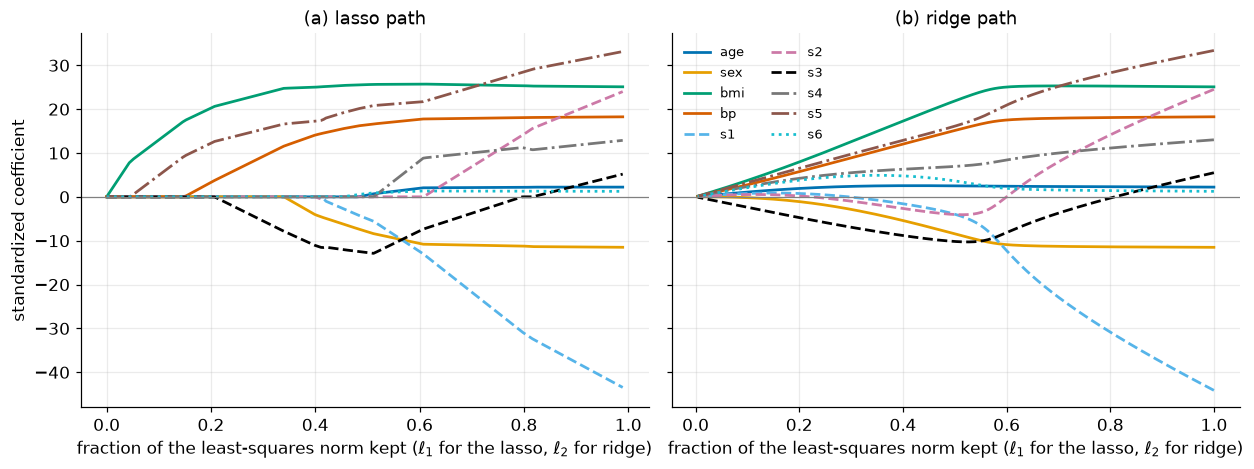

In [19]:
def figure_10_5():
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), sharey=True)
    cols = [BLUE, ORANGE, GREEN, VERMILION, SKY, PURPLE, "#000000", "#777777", "#8c564b", "#17becf"]
    styles = ["-", "-", "-", "-", "--", "--", "--", "-.", "-.", ":"]
    for ax, fr, cf, title in [(axes[0], frac_lasso, coefs_path, "(a) lasso path"), (axes[1], frac_ridge, coefs_ridge, "(b) ridge path")]:
        for j in range(p_d):
            ax.plot(fr, cf[j], color=cols[j], ls=styles[j], lw=1.8, label=feat[j])
        ax.axhline(0, color="gray", lw=0.8)
        ax.set(xlabel="fraction of the least-squares norm kept ($\\ell_1$ for the lasso, $\\ell_2$ for ridge)", title=title)
    axes[0].set_ylabel("standardized coefficient")
    axes[1].legend(frameon=False, fontsize=8.5, ncol=2, loc="upper left")
    fig.tight_layout()
    plt.show()


figure_10_5()

The exact path has 15 knots (the last one is least squares), and the table of events tells the story of the Diabetes features. `bmi` enters at $\lambda_{\max}=45.97$, then `s5`, `bp`, `s3` and `sex` one after the other, as in forward selection and OMP. The sixth entry is instructive: `s2` enters at $\lambda=4.12$, is joined by `s1` at $3.73$ and leaves at $3.64$: the two features have a correlation of $0.89$, so they are interchangeable for the fit, and the lasso hands the weight from one to the other. `s2` returns at $\lambda=0.31$, and `s3` leaves the model at $0.13$ to come back at $0.08$ with the opposite sign. So **the path is not monotone**: a feature can leave the model as $\lambda$ decreases, and the coefficient of `s3`, negative for most of the path ($-12$ at its lowest), is positive at the end (its least-squares weight is $+5.5$). Panel (b) of Figure 10.5 shows the contrast with ridge: all the coefficients are non-zero from the first value of $\lambda$ and move smoothly. Two features are noteworthy in both panels. `s1` has a *positive* correlation with the response ($+0.18$) and a *negative* least-squares weight ($-44.1$); the same collinearity of Section 6.2.4 acts here, and `s1` and `s2` are the features that take the extreme values at the end of both paths. And the check of piecewise linearity is exact: the lasso solution halfway between two knots is the average of the solutions at the knots, to $3\times10^{-14}$.

### 10.5.6 The price of shrinkage, and how to remove it

Soft-thresholding shrinks *every* surviving coefficient by $\lambda$, including the large ones, which are certainly in the model. The lasso estimates of the large coefficients are therefore biased towards zero by an amount that does not decrease as the coefficient grows (Proposition 10.6; compare the hard threshold, which leaves large coefficients intact). A simple remedy is **refitting**: use the lasso to *select* the support and then fit ordinary least squares on the selected features (a version of the "relaxed lasso" of Meinshausen, 2007). The coefficients lose their shrinkage, and gain variance; whether the exchange is favorable depends on the problem. Other remedies (the adaptive lasso, SCAD, MCP) are in the further reading. We compare the coefficients at the value of $\lambda$ chosen by cross-validation in Section 10.7.1; the code is there.

## 10.6 Algorithms for the lasso

The lasso objective (10.4) is a sum $F = g + h$ of a smooth convex function, $g(\mathbf{w}) = \frac1{2n}\lVert\mathbf{y}-\mathbf{X}\mathbf{w}\rVert^2$, whose gradient $\nabla g(\mathbf{w}) = -\frac1n\mathbf{X}^\top(\mathbf{y}-\mathbf{X}\mathbf{w})$ is $L$-Lipschitz with $L = \lambda_{\max}(\frac1n\mathbf{X}^\top\mathbf{X})$ (Section 7.2), and a convex function that is not differentiable, $h(\mathbf{w}) = \lambda\lVert\mathbf{w}\rVert_1$. The methods of Chapter 7 handle the first part and the non-smooth part needs something new. We look at three methods, in the order of how closely they use the structure of $h$.

### 10.6.1 The subgradient method does not give zeros

The simplest idea is to apply the subgradient method of Section 8.5.1: $\mathbf{w}_{k+1} = \mathbf{w}_k - \eta_k\big(\nabla g(\mathbf{w}_k) + \lambda\operatorname{sign}(\mathbf{w}_k)\big)$, with $\operatorname{sign}(0) = 0$ and a decreasing step $\eta_k\propto1/\sqrt{k}$. It converges, slowly (the guarantee for a general non-smooth convex function is $O(1/\sqrt{k})$ for the best iterate, and Theorem 8.6 gives $O(\ln k/k)$ in the strongly convex case with the right step), but its main defect is different. A coordinate that has to be exactly zero at the solution is, at each iteration, moved by the step $\eta_k\lambda$ away from zero and then back: the iterates oscillate around the kink and are almost never *exactly* zero. A method designed to find sparse solutions that returns dense iterates is not useful. We shall measure this below.

### 10.6.2 Coordinate descent

**Coordinate descent** minimizes $F$ over one coordinate at a time, keeping the others fixed. Let $c_j = \frac1n\lVert\mathbf{x}_j\rVert^2$ ($=1$ for standardized columns) and let $\mathbf{r}_{-j} = \mathbf{y}-\sum_{k\ne j}\mathbf{x}_kw_k$ be the **partial residual**, the residual that we would have without the contribution of feature $j$.

**Proposition 10.8 (coordinate update).** The minimizer of $F_\lambda$ over $w_j$, the other coordinates being fixed, is
$$
w_j\ \leftarrow\ \frac{S_\lambda(\rho_j)}{c_j},\qquad\rho_j = \frac1n\mathbf{x}_j^\top\mathbf{r}_{-j}.
$$

:::{admonition} Proof
:class: dropdown
As a function of $w_j$ alone, $F_\lambda = \frac{1}{2n}\lVert\mathbf{r}_{-j} - \mathbf{x}_jw_j\rVert^2 + \lambda\lvert w_j\rvert + \text{const} = \frac12c_jw_j^2 - \rho_jw_j + \lambda\lvert w_j\rvert + \text{const}' = \frac{c_j}2\big(w_j - \rho_j/c_j\big)^2 + \lambda\lvert w_j\rvert + \text{const}''$. This is the one-dimensional problem of Proposition 10.6 with $z = \rho_j/c_j$ and threshold $\lambda/c_j$, whose solution is $S_{\lambda/c_j}(\rho_j/c_j) = S_\lambda(\rho_j)/c_j$. $\square$
:::

An update costs $O(n)$ if the residual $\mathbf{r}$ is maintained: $\rho_j = \frac1n\mathbf{x}_j^\top\mathbf{r} + c_jw_j$ (add back the contribution of the feature) and, after the update, $\mathbf{r}\leftarrow\mathbf{r} - \mathbf{x}_j(w_j^{\mathrm{new}} - w_j^{\mathrm{old}})$. A **sweep** over all the coordinates costs $O(np)$, the cost of one gradient. A coordinate that is zero and stays zero costs only its inner product. Since the non-smooth part $h$ is a *sum of functions of single coordinates*, the algorithm converges to a minimizer (Tseng, 2001; for a non-separable non-smooth part, coordinate descent can get stuck). With a **warm start** (use the solution for $\lambda_k$ as the starting point for $\lambda_{k+1}<\lambda_k$) the whole path is computed in not much more time than a single fit; this is the algorithm of the `glmnet` package (Friedman, Hastie and Tibshirani, 2010), and the one behind scikit-learn's `Lasso` and `lasso_path`. It is the same idea as the dual coordinate descent of Section 8.5.2, applied to the primal problem.

### 10.6.3 Proximal gradient (ISTA, FISTA)

The second method uses $h$ through its **proximal operator**, $\operatorname{prox}_{\eta h}(\mathbf{v}) = \arg\min_{\mathbf{u}}\ \{\,h(\mathbf{u}) + \frac1{2\eta}\lVert\mathbf{u}-\mathbf{v}\rVert^2\,\}$.

**Proposition 10.9 (the proximal operator of the $\ell_1$ norm).** For $h = \lambda\lVert\cdot\rVert_1$, $\operatorname{prox}_{\eta h}(\mathbf{v}) = S_{\eta\lambda}(\mathbf{v})$, soft-thresholding applied to each coordinate with threshold $\eta\lambda$.

*Proof.* The objective $\lambda\lVert\mathbf{u}\rVert_1 + \frac1{2\eta}\lVert\mathbf{u}-\mathbf{v}\rVert^2$ is a sum over coordinates of $\lambda\lvert u_j\rvert + \frac1{2\eta}(u_j-v_j)^2$, and each term is $\frac1\eta$ times the problem of Proposition 10.6 with threshold $\eta\lambda$. $\square$

The **proximal gradient method** takes a gradient step on the smooth part and then applies the proximal operator of the non-smooth part:
$$
\mathbf{w}_{k+1} = S_{\eta\lambda}\big(\mathbf{w}_k - \eta\nabla g(\mathbf{w}_k)\big).
\tag{10.6}$$
With soft-thresholding this is called **ISTA** (iterative shrinkage-thresholding algorithm). Its meaning is the one of gradient descent in Section 7.3: by the descent lemma (Proposition 7.2), $g(\mathbf{u})\le g(\mathbf{w}_k) + \nabla g(\mathbf{w}_k)^\top(\mathbf{u}-\mathbf{w}_k) + \frac L2\lVert\mathbf{u}-\mathbf{w}_k\rVert^2$, and (10.6) with $\eta = 1/L$ minimizes this quadratic upper bound *plus the exact $h$*. The step is a gradient step with a soft-threshold, and so, unlike the subgradient method, it produces exact zeros.

**Theorem 10.10 (proximal gradient).** Let $g$ be convex and $L$-smooth, $h$ convex, and $0<\eta\le1/L$. Then the iterates of (10.6) satisfy $F(\mathbf{w}_{k+1})\le F(\mathbf{w}_k) - \frac1{2\eta}\lVert\mathbf{w}_{k+1}-\mathbf{w}_k\rVert^2$, and for every minimizer $\mathbf{w}^\ast$,
$$
F(\mathbf{w}_k) - F(\mathbf{w}^\ast)\le\frac{\lVert\mathbf{w}_0-\mathbf{w}^\ast\rVert^2}{2\eta k}.
$$

:::{admonition} Proof
:class: dropdown
Write $\mathbf{w}^+ = \mathbf{w}_{k+1}$, $\mathbf{w} = \mathbf{w}_k$. *Step 1: an upper bound for $g$.* By the descent lemma and $\eta\le1/L$, $g(\mathbf{w}^+)\le g(\mathbf{w}) + \nabla g(\mathbf{w})^\top(\mathbf{w}^+-\mathbf{w}) + \frac1{2\eta}\lVert\mathbf{w}^+-\mathbf{w}\rVert^2$. By convexity, $g(\mathbf{w})\le g(\mathbf{z}) + \nabla g(\mathbf{w})^\top(\mathbf{w}-\mathbf{z})$ for any $\mathbf{z}$. Adding the two, $g(\mathbf{w}^+)\le g(\mathbf{z}) + \nabla g(\mathbf{w})^\top(\mathbf{w}^+-\mathbf{z}) + \frac1{2\eta}\lVert\mathbf{w}^+-\mathbf{w}\rVert^2$. *Step 2: a lower bound for $h$.* The point $\mathbf{w}^+$ minimizes $h(\mathbf{u}) + \frac1{2\eta}\lVert\mathbf{u}-(\mathbf{w}-\eta\nabla g(\mathbf{w}))\rVert^2$, so $\frac1\eta(\mathbf{w}-\mathbf{w}^+) - \nabla g(\mathbf{w})\in\partial h(\mathbf{w}^+)$, and the subgradient inequality gives $h(\mathbf{z})\ge h(\mathbf{w}^+) + \big(\frac1\eta(\mathbf{w}-\mathbf{w}^+) - \nabla g(\mathbf{w})\big)^\top(\mathbf{z}-\mathbf{w}^+)$. *Step 3.* Adding the two inequalities, the terms in $\nabla g(\mathbf{w})$ cancel and
$$
F(\mathbf{w}^+)\le F(\mathbf{z}) + \frac1{2\eta}\Big(\lVert\mathbf{w}^+-\mathbf{w}\rVert^2 - 2(\mathbf{w}-\mathbf{w}^+)^\top(\mathbf{z}-\mathbf{w}^+)\Big) = F(\mathbf{z}) + \frac1{2\eta}\Big(\lVert\mathbf{w}-\mathbf{z}\rVert^2 - \lVert\mathbf{w}^+-\mathbf{z}\rVert^2\Big),
$$
where the last equality expands $\lVert\mathbf{w}-\mathbf{z}\rVert^2 = \lVert(\mathbf{w}-\mathbf{w}^+) + (\mathbf{w}^+-\mathbf{z})\rVert^2$. Taking $\mathbf{z} = \mathbf{w}$ gives the decrease of $F$; taking $\mathbf{z} = \mathbf{w}^\ast$ and summing over $k = 0,\dots,K-1$, the right-hand sides telescope: $\sum_{k<K}\big(F(\mathbf{w}_{k+1}) - F^\ast\big)\le\frac1{2\eta}\lVert\mathbf{w}_0-\mathbf{w}^\ast\rVert^2$. Since $F(\mathbf{w}_k)$ is non-increasing, $K\big(F(\mathbf{w}_K)-F^\ast\big)\le\sum_{k<K}\big(F(\mathbf{w}_{k+1})-F^\ast\big)$, which is the claim. $\square$
:::

The rate is that of gradient descent on a smooth convex function (Theorem 7.4): the non-smooth part costs nothing in the rate, provided its proximal operator is cheap. As in Chapter 7, momentum accelerates it: **FISTA** (Beck and Teboulle, 2009) applies (10.6) at the extrapolated point $\mathbf{v}_k = \mathbf{w}_k + \frac{t_{k-1}-1}{t_k}(\mathbf{w}_k-\mathbf{w}_{k-1})$ with $t_{k+1} = \big(1+\sqrt{1+4t_k^2}\big)/2$, and achieves $O(1/k^2)$, the rate of Nesterov's method (Theorem 7.9). When $g$ is strongly convex, as it is for the Diabetes data ($\mu = 0.0094$ for the standardized features, with $L = 3.92$, so $\kappa = 418$, the number of Section 7.2), both converge linearly, with the factor of Theorem 7.5 for ISTA.

### 10.6.4 A comparison on the Diabetes data

We solve the lasso with $\lambda = 5$ on the standardized Diabetes training set with the four methods: the subgradient method with step $c/\sqrt{k}$ for four values of $c$, ISTA and FISTA with $\eta = 1/L$, and coordinate descent. The reference solution $F^\ast$ comes from 2,000 sweeps of coordinate descent (checked below against scikit-learn). *One iteration of ISTA, FISTA or the subgradient method and one sweep of coordinate descent cost the same, $O(np)$*, so the comparison is per unit of work.

In [20]:
def lasso_obj(Z, y, w, lam):
    r = y - Z @ w
    return float(r @ r) / (2 * len(y)) + lam * np.abs(w).sum()


def lasso_cd(Z, y, lam, w0=None, n_sweeps=200):
    """Cyclic coordinate descent (Proposition 10.8). Returns w and, per sweep, the objective and the support."""
    n, p = Z.shape
    w = np.zeros(p) if w0 is None else w0.copy()
    r = y - Z @ w
    c = (Z ** 2).sum(axis=0) / n
    objs, supports = [], []
    for _ in range(n_sweeps):
        for j in range(p):
            rho = Z[:, j] @ r / n + c[j] * w[j]
            w_new = soft(rho, lam) / c[j]
            if w_new != w[j]:
                r += Z[:, j] * (w[j] - w_new)
                w[j] = w_new
        objs.append(lasso_obj(Z, y, w, lam))
        supports.append(w != 0)
    return w, np.array(objs), np.array(supports)


def lasso_prox_grad(Z, y, lam, eta, n_iter=2000, accelerated=False):
    """ISTA (10.6), or FISTA when accelerated=True."""
    n, p = Z.shape
    w = np.zeros(p)
    v, t = w.copy(), 1.0
    objs, supports = [], []
    for _ in range(n_iter):
        grad = -Z.T @ (y - Z @ v) / n
        w_new = soft(v - eta * grad, eta * lam)
        if accelerated:
            t_new = (1 + np.sqrt(1 + 4 * t * t)) / 2
            v = w_new + (t - 1) / t_new * (w_new - w)
            t = t_new
        else:
            v = w_new
        w = w_new
        objs.append(lasso_obj(Z, y, w, lam))
        supports.append(w != 0)
    return w, np.array(objs), np.array(supports)


def lasso_subgradient(Z, y, lam, c, n_iter=2000):
    n, p = Z.shape
    w = np.zeros(p)
    objs, supports = [], []
    for k in range(n_iter):
        g = -Z.T @ (y - Z @ w) / n + lam * np.sign(w)
        w = w - c / np.sqrt(k + 1) * g
        objs.append(lasso_obj(Z, y, w, lam))
        supports.append(w != 0)
    return w, np.array(objs), np.array(supports)


lam_s = 5.0
L_d = np.linalg.eigvalsh(Zd.T @ Zd / n_d).max()
mu_d = np.linalg.eigvalsh(Zd.T @ Zd / n_d).min()
w_star, objs_cd_long, _ = lasso_cd(Zd, yc, lam_s, n_sweeps=2000)
F_star = lasso_obj(Zd, yc, w_star, lam_s)
w_sk1 = Lasso(alpha=lam_s, fit_intercept=False, tol=1e-14, max_iter=200000).fit(Zd, yc).coef_
print(f"L = {L_d:.3f}, mu = {mu_d:.4f}, kappa = {L_d / mu_d:.0f}; F* = {F_star:.6f}; non-zeros at the solution: {int((w_star != 0).sum())}")
print(f"our coordinate descent vs scikit-learn: max |difference of the weights| = {np.abs(w_star - w_sk1).max():.1e}")
S_star = np.flatnonzero(w_star)
ev_S = np.linalg.eigvalsh(Zd[:, S_star].T @ Zd[:, S_star] / n_d)
print(f"support of the solution: {', '.join(feat[j] for j in S_star)}; restricted to it, L_S = {ev_S.max():.2f}, mu_S = {ev_S.min():.3f}, kappa_S = {ev_S.max() / ev_S.min():.1f}")

runs = {}
runs["coordinate descent"] = lasso_cd(Zd, yc, lam_s, n_sweeps=200)[1:]
runs["ISTA"] = lasso_prox_grad(Zd, yc, lam_s, 1 / L_d)[1:]
runs["FISTA"] = lasso_prox_grad(Zd, yc, lam_s, 1 / L_d, accelerated=True)[1:]
for c_ in [0.03, 0.1, 0.3, 1.0]:
    runs[f"subgradient, c={c_}"] = lasso_subgradient(Zd, yc, lam_s, c_)[1:]

supp_star = w_star != 0
rows = []
for name, (objs, supports) in runs.items():
    gap = objs - F_star
    row = {"method": name, "gap after 200 iterations": gap[199]}
    for tol in [1e-3, 1e-6, 1e-9]:
        hit = np.flatnonzero(gap <= tol)
        row[f"iterations to {tol:.0e}"] = int(hit[0]) + 1 if len(hit) else "not reached"
    mism = (supports != supp_star).any(axis=1)
    row["iteration after which the support is exact"] = "never" if mism[-1] else (int(np.flatnonzero(mism).max()) + 2 if mism.any() else 1)
    row["non-zeros at the end"] = int(supports[-1].sum())
    rows.append(row)
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.2e}"))

L = 3.919, mu = 0.0094, kappa = 418; F* = 1887.385869; non-zeros at the solution: 5
our coordinate descent vs scikit-learn: max |difference of the weights| = 1.1e-13
support of the solution: sex, bmi, bp, s3, s5; restricted to it, L_S = 2.13, mu_S = 0.420, kappa_S = 5.1
             method  gap after 200 iterations iterations to 1e-03 iterations to 1e-06 iterations to 1e-09 iteration after which the support is exact  non-zeros at the end
 coordinate descent                  0.00e+00                   8                  10                  15                                          2                     5
               ISTA                  0.00e+00                  31                  61                  92                                         15                     5
              FISTA                  4.55e-13                  22                  47                  93                                          8                     5
subgradient, c=0.03                  8.31e+01

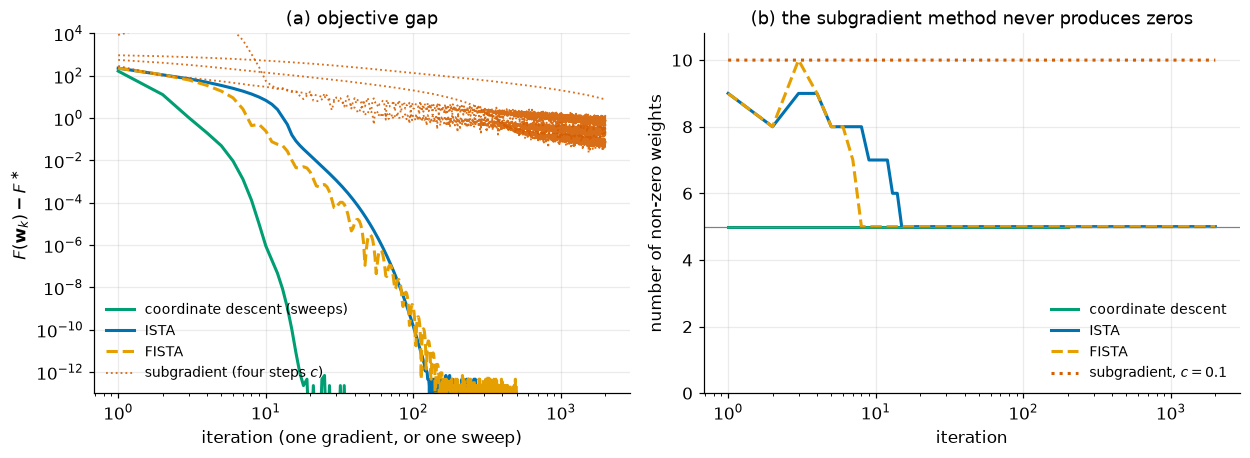

In [21]:
def figure_10_6():
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
    style = {"coordinate descent": (GREEN, "-"), "ISTA": (BLUE, "-"), "FISTA": (ORANGE, "--")}
    ax = axes[0]
    for name, (objs, supports) in runs.items():
        gap = np.maximum(objs - F_star, 1e-16)
        if name in style:
            ax.loglog(np.arange(1, len(gap) + 1), gap, color=style[name][0], ls=style[name][1], lw=2, label=name + (" (sweeps)" if name.startswith("coord") else ""))
        else:
            ax.loglog(np.arange(1, len(gap) + 1), gap, color=VERMILION, ls=":", lw=1.2, alpha=0.9, label="subgradient (four steps $c$)" if name.endswith("c=0.03") else None)
    ax.set(xlabel="iteration (one gradient, or one sweep)", ylabel=r"$F(\mathbf{w}_k)-F^\ast$", title="(a) objective gap", ylim=(1e-13, 1e4))
    ax.legend(frameon=False, fontsize=9, loc="lower left")
    ax = axes[1]
    for name, (objs, supports) in runs.items():
        nz = supports.sum(axis=1)
        if name in style:
            ax.semilogx(np.arange(1, len(nz) + 1), nz, color=style[name][0], ls=style[name][1], lw=2, label=name)
        elif name.endswith("c=0.1"):
            ax.semilogx(np.arange(1, len(nz) + 1), nz, color=VERMILION, ls=":", lw=2, label="subgradient, $c=0.1$")
    ax.axhline(supp_star.sum(), color="gray", lw=0.8)
    ax.set(xlabel="iteration", ylabel="number of non-zero weights", title="(b) the subgradient method never produces zeros", ylim=(0, 10.8))
    ax.legend(frameon=False, fontsize=9, loc="lower right")
    fig.tight_layout()
    plt.show()


figure_10_6()

Figure 10.6 and the table tell the same story. **Coordinate descent** is the fastest: after 8 sweeps the gap is below $10^{-3}$, after 10 below $10^{-6}$ and after 15 below $10^{-9}$, and the support is exact from the second sweep on, because a coordinate that the soft-threshold sets to zero stays at zero. **ISTA** needs 31, 61 and 92 iterations for the same three accuracies and identifies the support after 15; **FISTA** is faster at the beginning (22 iterations to $10^{-3}$, against 31) but its gap is not monotone (the ripples in panel (a) are the momentum, as in Section 7.5) and for high accuracy it is no better than ISTA (93 against 92 iterations to $10^{-9}$). The reason is visible in the printed conditioning: once the support is identified, both methods are minimizing a function of the five active coordinates only, whose condition number is $\kappa_S\approx 5$ and not the $\kappa = 418$ of the whole problem, so plain gradient steps already converge linearly and fast; the acceleration of Theorem 7.9 pays when the problem is badly conditioned, and here it is not. The **subgradient method** is in a different league: after 2,000 iterations none of the four step constants has reached a gap of $10^{-3}$ (after 200 iterations the best of them, $c=0.3$, is at $0.58$, and the largest step oscillates at a gap of order one), and, as panel (b) shows, **it never produces a zero**: it keeps all ten coordinates non-zero while the solution has five. For the lasso the correct choice is a method that uses the soft-threshold, which is what the proximal and coordinate methods do. (The 10 columns of Diabetes make every method fast; with $p$ in the thousands the cost per sweep, $O(np)$, and the identification of the active set are what matter, and coordinate descent with warm starts along the path is the standard solver.)

## 10.7 Choosing $\lambda$, and what sparsity buys

### 10.7.1 Cross-validation and the one-standard-error rule

The penalty $\lambda$ plays for the lasso the role of the size $k$ for subset selection: too large gives a model that is too small and biased, too small a model that overfits. We choose it as in Chapter 5, with 10-fold cross-validation, repeating the standardization in each fold (the lasso is also computed on the whole path in each fold, from the same grid of 60 values of $\lambda$, which makes the folds comparable). The one-standard-error rule of Section 5.4.1 chooses the *largest* $\lambda$ (the sparsest model) whose error is within one standard error of the minimum.

In [22]:
def cv_lasso_path(X, y, alphas, n_folds=10, seed=SEED):
    """10-fold CV error of the lasso along a grid of penalties; standardization repeated inside each fold."""
    kf = KFold(n_folds, shuffle=True, random_state=seed)
    errs = np.zeros((n_folds, len(alphas)))
    for f, (tr, va) in enumerate(kf.split(X)):
        sc = StandardScaler().fit(X[tr])
        A, B = sc.transform(X[tr]), sc.transform(X[va])
        ym = y[tr].mean()
        _, coefs, _ = lasso_path(A, y[tr] - ym, alphas=alphas, tol=1e-9, max_iter=20000)
        pred = B @ coefs + ym
        errs[f] = ((y[va][:, None] - pred) ** 2).mean(axis=0)
    return errs


grid = np.logspace(np.log10(lam_max_d), np.log10(lam_max_d * 1e-3), 60)
errs_l = cv_lasso_path(Xd_tr, yd_tr, grid)
cv_mean_l = errs_l.mean(axis=0)
cv_se_l = errs_l.std(axis=0, ddof=1) / np.sqrt(errs_l.shape[0])
i_min = int(np.argmin(cv_mean_l))
i_1se = int(np.where(cv_mean_l <= cv_mean_l[i_min] + cv_se_l[i_min])[0].min())
lam_min, lam_1se = grid[i_min], grid[i_1se]
w_min = Lasso(alpha=lam_min, fit_intercept=False, tol=1e-12, max_iter=200000).fit(Zd, yc).coef_
w_1se = Lasso(alpha=lam_1se, fit_intercept=False, tol=1e-12, max_iter=200000).fit(Zd, yc).coef_
S_min, S_1se = np.flatnonzero(w_min), np.flatnonzero(w_1se)
# refit: ordinary least squares on the support selected at lambda_1se (the "relaxed" or "refitted" lasso)
w_refit = np.zeros(p_d)
w_refit[S_1se] = np.linalg.lstsq(Zd[:, S_1se], yc, rcond=None)[0]
print(f"CV minimum : lambda = {lam_min:.2f}, CV RMSE = {np.sqrt(cv_mean_l[i_min]):.2f}, {len(S_min)} features: {', '.join(feat[j] for j in S_min)}")
print(f"one-SE rule: lambda = {lam_1se:.2f}, CV RMSE = {np.sqrt(cv_mean_l[i_1se]):.2f}, {len(S_1se)} features: {', '.join(feat[j] for j in S_1se)}")
print(f"(CV RMSE of the null model: {np.sqrt(cv_mean_l[0]):.2f}; SE of the CV MSE at the minimum: {cv_se_l[i_min]:.0f})")
flat = grid <= 1.0
print(f"over the {int(flat.sum())} grid values with lambda <= 1 the CV MSE is within {100 * (cv_mean_l[flat].max() / cv_mean_l[i_min] - 1):.1f}% of its minimum")
print(pd.DataFrame({"feature": feat, "least squares": w_ols_d, "lasso, lambda_min": w_min, "lasso, one-SE": w_1se,
                    "refit on one-SE support": w_refit}).round(1).to_string(index=False))

CV minimum : lambda = 0.54, CV RMSE = 55.92, 9 features: age, sex, bmi, bp, s1, s3, s4, s5, s6
one-SE rule: lambda = 6.28, CV RMSE = 57.57, 5 features: sex, bmi, bp, s3, s5
(CV RMSE of the null model: 77.96; SE of the CV MSE at the minimum: 195)
over the 27 grid values with lambda <= 1 the CV MSE is within 0.5% of its minimum
feature  least squares  lasso, lambda_min  lasso, one-SE  refit on one-SE support
    age            2.2                1.8            0.0                      0.0
    sex          -11.5              -10.3           -0.5                    -10.9
    bmi           25.1               25.7           24.8                     25.4
     bp           18.2               17.5           11.9                     18.3
     s1          -44.1              -11.5           -0.0                      0.0
     s2           24.5                0.0           -0.0                      0.0
     s3            5.5               -8.5           -8.2                    -16.5
     s4         

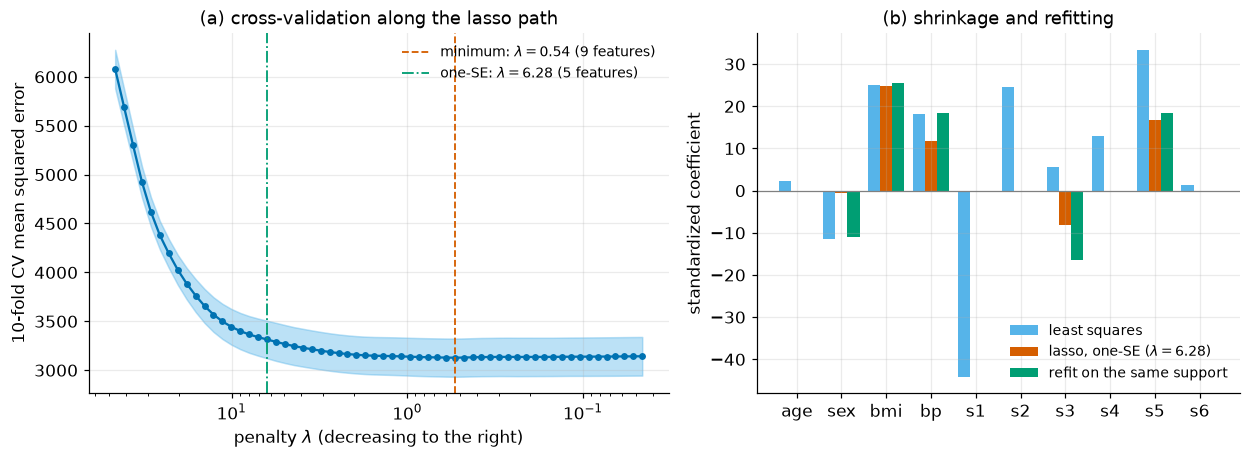

In [23]:
def figure_10_7():
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), gridspec_kw={"width_ratios": [1.2, 1]})
    ax = axes[0]
    ax.fill_between(grid, cv_mean_l - cv_se_l, cv_mean_l + cv_se_l, color=SKY, alpha=0.4)
    ax.plot(grid, cv_mean_l, "o-", color=BLUE, ms=3.5, lw=1.5)
    ax.axvline(lam_min, color=VERMILION, ls="--", lw=1.2, label=rf"minimum: $\lambda={lam_min:.2f}$ ({len(S_min)} features)")
    ax.axvline(lam_1se, color=GREEN, ls="-.", lw=1.2, label=rf"one-SE: $\lambda={lam_1se:.2f}$ ({len(S_1se)} features)")
    ax.set(xscale="log", xlabel=r"penalty $\lambda$ (decreasing to the right)", ylabel="10-fold CV mean squared error", title=r"(a) cross-validation along the lasso path")
    ax.invert_xaxis()
    ax.legend(frameon=False, fontsize=9)
    ax = axes[1]
    xs = np.arange(p_d)
    wd = 0.27
    ax.bar(xs - wd, w_ols_d, wd, color=SKY, label="least squares")
    ax.bar(xs, w_1se, wd, color=VERMILION, label=r"lasso, one-SE ($\lambda=%.2f$)" % lam_1se)
    ax.bar(xs + wd, w_refit, wd, color=GREEN, label="refit on the same support")
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_xticks(xs)
    ax.set_xticklabels(feat)
    ax.set(ylabel="standardized coefficient", title="(b) shrinkage and refitting")
    ax.legend(frameon=False, fontsize=9, loc="lower right")
    fig.tight_layout()
    plt.show()


figure_10_7()

The cross-validation curve of Figure 10.7(a) is flat for every $\lambda$ below about 1: from the minimum at $\lambda=0.54$ down to the smallest value of the grid the error changes by less than $1\%$, and the standard error at the minimum ($195$ in MSE, about $1.7$ points of RMSE) is larger than any of these differences. The minimum keeps nine features (all but `s2`; cross-validated RMSE $55.9$, against $78.0$ for the null model). The one-standard-error rule chooses $\lambda = 6.28$, which keeps five (`sex`, `bmi`, `bp`, `s3`, `s5`, *the same five as the one-SE choice for best-subset selection* in Section 10.3.2) at a cross-validated RMSE of $57.6$, $1.7$ points above the minimum, within one standard error by construction. The table and panel (b) show the effect of the penalty on the coefficients. Least squares gives `s1` the weight $-44.1$ and `s2` the weight $+24.5$, the unstable pair of Section 6.2.4; the lasso at the minimum drops `s2` and gives `s1` $-11.5$, and also reverses the sign of `s3` ($+5.5$ in least squares, $-8.5$ in the lasso), another feature whose least-squares weight was an artefact of the collinearity. At the one-SE value the lasso weights are below those of the *refit on the same support* by an amount that depends on the feature: $2\%$ for `bmi`, $9\%$ for `s5`, $35\%$ for `bp`, $50\%$ for `s3` (and $95\%$ for `sex`, which is in the model by a hair: $-0.5$ against $-10.9$). This is the shrinkage bias of Section 10.5.6; whether the refit predicts better is checked in Section 10.7.3.

### 10.7.2 Degrees of freedom of the lasso

How many degrees of freedom has a lasso fit? Subset selection of size $k$ has *more* than $k+1$ (Section 10.3.2); the lasso is a continuous shrinkage, so one may expect it to be different. In the orthonormal case the answer is exact, and simple.

**Proposition 10.11 (degrees of freedom in the orthonormal case).** Let $\frac1n\mathbf{X}^\top\mathbf{X}=\mathbf{I}$, $\mathbf{y} = \boldsymbol\mu+\boldsymbol\varepsilon$ with $\boldsymbol\varepsilon\sim\mathcal{N}(0,\sigma^2\mathbf{I})$. The fitted values of the lasso satisfy
$$
\mathrm{df}(\lambda) = \frac{1}{\sigma^2}\sum_{i=1}^n\operatorname{Cov}(\hat y_i, y_i) = \mathbb{E}\,\lVert\hat{\mathbf{w}}_\lambda\rVert_0,
$$
the expected number of non-zero coefficients (plus one for the intercept, if there is one).

:::{admonition} Proof
:class: dropdown
Since $\operatorname{Cov}(\hat y_i,y_i) = \mathbb{E}[(\hat y_i - \mathbb{E}\hat y_i)\varepsilon_i]$, and $\hat{\mathbf{y}} = \mathbf{X}\hat{\mathbf{w}}$, we have $\sum_i\operatorname{Cov}(\hat y_i,y_i) = \mathbb{E}[\boldsymbol\varepsilon^\top\mathbf{X}(\hat{\mathbf{w}}-\mathbb{E}\hat{\mathbf{w}})] = \sum_j\mathbb{E}[(\mathbf{x}_j^\top\boldsymbol\varepsilon)(\hat w_j-\mathbb{E}\hat w_j)]$. Let $Z_j = \hat w_j^{\mathrm{OLS}} = \frac1n\mathbf{x}_j^\top\mathbf{y}\sim\mathcal{N}(m_j,\sigma^2/n)$; then $\mathbf{x}_j^\top\boldsymbol\varepsilon = n(Z_j-m_j)$ and $\hat w_j = S_\lambda(Z_j)$, so the $j$-th term is $n\,\mathbb{E}[(Z_j-m_j)S_\lambda(Z_j)]$ (subtracting the constant $\mathbb{E}\hat w_j$ changes nothing, since $\mathbb{E}(Z_j-m_j)=0$). **Stein's lemma** states that for $Z\sim\mathcal{N}(m,\tau^2)$ and a weakly differentiable $f$, $\mathbb{E}[(Z-m)f(Z)] = \tau^2\mathbb{E}[f'(Z)]$. With $f = S_\lambda$, whose derivative is $\mathbb{1}\{\lvert z\rvert>\lambda\}$, and $\tau^2 = \sigma^2/n$, the $j$-th term is $n\cdot\frac{\sigma^2}{n}\,\mathbb{P}(\lvert Z_j\rvert>\lambda) = \sigma^2\,\mathbb{P}(\hat w_j\neq0)$. Summing over $j$ and dividing by $\sigma^2$ gives $\sum_j\mathbb{P}(\hat w_j\ne0) = \mathbb{E}\lVert\hat{\mathbf{w}}\rVert_0$. $\square$
:::

For general designs the same formula holds (Zou, Hastie and Tibshirani, 2007, along the LARS path; Tibshirani and Taylor, 2012, for a fixed $\lambda$, with the number of non-zeros replaced by the rank of the active columns, which is the same when the columns are in general position): **the number of non-zero coefficients is an unbiased estimate of the degrees of freedom of the lasso**. The contrast with Section 10.3.2 is the point. Best subset *selects with a hard threshold* and pays for the search with extra degrees of freedom; the lasso *shrinks*, and the shrinkage of each selected coefficient exactly compensates for the selection, so that the naive count is right. This is what lets $C_p$ and BIC be used with the lasso (the `LassoLarsIC` estimator of scikit-learn), without a cross-validation. We check it by Monte Carlo in a simulated world on the real design: the **truth is the least-squares fit** $\boldsymbol\mu = \mathbf{Z}\hat{\mathbf{w}}_{\mathrm{OLS}}$ of the Diabetes training set, and the noise is Gaussian with the estimated $\hat\sigma = 54.8$ (*constructed*, as in Section 6.3.3). In each of 3,000 replicates we fit the lasso, and estimate $\mathrm{df} = \sum_i\operatorname{Cov}(\hat y_i, y_i)/\sigma^2$ directly from the replicates.

In [24]:
def lasso_df_monte_carlo(lams, n_batches=3, per_batch=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    mu_true = Zd @ w_ols_d + yd_tr.mean()
    sigma = np.sqrt(sigma2_hat)
    out = {lam: {"df": [], "nz": []} for lam in lams}
    for _ in range(n_batches):
        E = rng.normal(scale=sigma, size=(per_batch, n_d))
        for lam in lams:
            Yh = np.empty((per_batch, n_d))
            nz = np.empty(per_batch)
            for b in range(per_batch):
                m = Lasso(alpha=lam, tol=1e-8).fit(Zd, mu_true + E[b])          # with an intercept
                Yh[b], nz[b] = m.predict(Zd), (m.coef_ != 0).sum()
            out[lam]["df"].append(np.sum((Yh - Yh.mean(axis=0)) * E) / per_batch / sigma ** 2)
            out[lam]["nz"].append(nz.mean() + 1)                                 # + 1 for the intercept
    return out


lams_mc = [0.1, 1.0, 3.0, 10.0, 20.0, 40.0]
t0 = time.time()
mc = lasso_df_monte_carlo(lams_mc)
print(pd.DataFrame({"lambda": lams_mc,
                    "df from the covariances": [np.mean(mc[l]["df"]) for l in lams_mc],
                    "SE (3 batches)": [np.std(mc[l]["df"], ddof=1) / np.sqrt(3) for l in lams_mc],
                    "E[number of non-zeros] + 1": [np.mean(mc[l]["nz"]) for l in lams_mc]}).round(2).to_string(index=False))
print(f"({time.time() - t0:.0f} s)")

 lambda  df from the covariances  SE (3 batches)  E[number of non-zeros] + 1
    0.1                    10.86            0.12                       10.71
    1.0                     9.29            0.12                        9.20
    3.0                     7.90            0.11                        7.81
   10.0                     5.28            0.09                        5.22
   20.0                     4.26            0.07                        4.22
   40.0                     2.35            0.05                        2.31
(8 s)


The two columns agree within $0.15$ for the six values of $\lambda$ (at most $1.3$ Monte Carlo standard errors), from $10.9$ degrees of freedom at $\lambda=0.1$ to $2.4$ at $\lambda=40$, although the design is far from orthonormal: the expected number of non-zero coefficients, plus one for the intercept, is the degrees of freedom of the lasso. Compare with Section 10.3.2, where the best single feature out of ten had $3.4$ degrees of freedom instead of one. The lasso with, on average, $1.3$ non-zero coefficients at $\lambda=40$ has $2.3$ degrees of freedom, intercept included; the shrinkage of the weights compensates for the choice of the features.

Information criteria therefore give a choice of $\lambda$ without refitting. With `LassoLarsIC` (the criteria use the number of non-zero coefficients as degrees of freedom and the noise variance estimated from the full least-squares fit):

In [25]:
ic_fits = {crit: LassoLarsIC(criterion=crit).fit(Zd, yd_tr) for crit in ["aic", "bic"]}
for crit, m in ic_fits.items():
    print(f"{crit.upper()}: lambda = {m.alpha_:.2f}, {int((m.coef_ != 0).sum())} features: {', '.join(feat[j] for j in np.flatnonzero(m.coef_))}")

AIC: lambda = 0.08, 9 features: age, sex, bmi, bp, s1, s2, s4, s5, s6
BIC: lambda = 2.75, 6 features: sex, bmi, bp, s1, s3, s5


The AIC chooses $\lambda=0.08$ and nine features (all but `s3`), the BIC chooses $\lambda=2.75$ and six (`sex`, `bmi`, `bp`, `s1`, `s3`, `s5`): as for best subsets, the BIC gives the smaller model. The six features of the BIC lasso differ from the six of the BIC best subset (Section 10.3.1) by one, `s3` in place of `s2`, another instance of the interchangeable correlated features.

### 10.7.3 What does sparsity buy on the Diabetes data?

We now compare, on the 111 test patients, the methods of this chapter with least squares and ridge regression, all fitted on the 331 training patients with their tuning done *only* on the training set. This is the single use of the test set in this chapter. The intervals are bootstrap intervals over the test patients (the predictions are fixed and the patients are resampled; Chapter 6 used the same device).

In [26]:
from sklearn.model_selection import GridSearchCV

kf10 = KFold(10, shuffle=True, random_state=SEED)
preds, nfeat = {}, {}


def add(name, pred, k):
    preds[name], nfeat[name] = pred, k


ybar = yd_tr.mean()
add("mean of the training targets", np.full(len(yd_te), ybar), 0)
add("least squares", Zd_te @ w_ols_d + ybar, p_d)
ridge_cv = GridSearchCV(make_pipeline(StandardScaler(), Ridge()), {"ridge__alpha": np.logspace(-1, 4, 40)}, cv=kf10,
                        scoring="neg_mean_squared_error").fit(Xd_tr, yd_tr)
add("ridge (CV)", ridge_cv.predict(Xd_te), p_d)
add("lasso, CV minimum", Zd_te @ w_min + ybar, len(S_min))
add("lasso, one-SE rule", Zd_te @ w_1se + ybar, len(S_1se))
add("lasso one-SE support, refit by least squares", Zd_te @ w_refit + ybar, len(S_1se))
add("lasso, BIC", ic_fits["bic"].predict(Zd_te), int((ic_fits["bic"].coef_ != 0).sum()))
en_cv = GridSearchCV(make_pipeline(StandardScaler(), ElasticNet(max_iter=50000)),
                     {"elasticnet__alpha": np.logspace(-2, 1.5, 36), "elasticnet__l1_ratio": [0.1, 0.5, 0.9, 1.0]},
                     cv=kf10, scoring="neg_mean_squared_error").fit(Xd_tr, yd_tr)
en_best = en_cv.best_estimator_.named_steps["elasticnet"]
add("elastic net (CV)", en_cv.predict(Xd_te), int((en_best.coef_ != 0).sum()))


def subset_pred(k):
    S = list(best_S[k])
    b = np.linalg.lstsq(Zd[:, S], yc, rcond=None)[0]
    return Zd_te[:, S] @ b + ybar


add(f"best subset, BIC (k = {chosen_sizes['BIC']})", subset_pred(chosen_sizes["BIC"]), chosen_sizes["BIC"])
add(f"best subset, CV one-SE (k = {chosen_sizes['CV one-SE']})", subset_pred(chosen_sizes["CV one-SE"]), chosen_sizes["CV one-SE"])

rng = np.random.default_rng(SEED)
boot_idx = rng.integers(0, len(yd_te), size=(2000, len(yd_te)))
rows = []
for name, pr in preds.items():
    se2 = (yd_te - pr) ** 2
    boots = np.sqrt(se2[boot_idx].mean(axis=1))
    rows.append({"method": name, "features": nfeat[name], "test RMSE": np.sqrt(se2.mean()),
                 "95% bootstrap interval": f"[{np.percentile(boots, 2.5):.1f}, {np.percentile(boots, 97.5):.1f}]"})
print(f"ridge: alpha = {ridge_cv.best_params_['ridge__alpha']:.1f}; elastic net: alpha = {en_cv.best_params_['elasticnet__alpha']:.3f}, l1_ratio = {en_cv.best_params_['elasticnet__l1_ratio']}")
print(pd.DataFrame(rows).round(2).to_string(index=False))

ridge: alpha = 20.3; elastic net: alpha = 0.079, l1_ratio = 0.1
                                      method  features  test RMSE 95% bootstrap interval
                mean of the training targets         0      74.88           [68.3, 81.5]
                               least squares        10      53.37           [46.2, 60.9]
                                  ridge (CV)        10      53.12           [46.1, 60.3]
                           lasso, CV minimum         9      53.02           [46.0, 60.3]
                          lasso, one-SE rule         5      53.10           [46.8, 59.7]
lasso one-SE support, refit by least squares         5      52.62           [46.0, 59.8]
                                  lasso, BIC         6      52.51           [46.0, 59.5]
                            elastic net (CV)        10      53.10           [46.1, 60.2]
                    best subset, BIC (k = 6)         6      52.85           [45.9, 60.2]
              best subset, CV one-SE (k = 5)  

On the 111 test patients all the methods that use the features, from least squares ($53.37$) to the lasso with the BIC ($52.51$), lie within $0.9$ points of each other, and their bootstrap intervals, 13 to 15 points wide, overlap almost completely: the test set cannot rank them. What it does show is that **sparsity costs nothing on these data**: five features (the lasso with the one-SE rule, with or without the refit, and the best subset chosen by cross-validation) predict as well as ten ($53.1$, $52.6$ and $52.6$ against $53.4$ for least squares), and every one of them is far better than the baseline ($74.9$). The refit of the one-SE support ($52.6$) is $0.5$ points better than the shrunken lasso on the same support ($53.1$): the shrinkage bias is real, but small compared with the noise of the estimate. The elastic net chose $\ell_1$ ratio $0.1$, which is almost ridge and keeps all ten features: we come back to it in the next section. A comparison on one split of 111 patients is a weak instrument, as Chapter 5 insisted.

A single split of 111 patients cannot rank methods that differ by less than a point, so we repeat the comparison on 30 random splits of the 442 patients (331 for training, 111 for testing), with the tuning inside each training set (5-fold cross-validation for the lasso, the leave-one-out shortcut for ridge), and compare the lasso with ridge with the **corrected resampled $t$-test** of Section 5.5.2 (and Exercise 6.6). Each split is analyzed with the linear features and, for Section 10.7.5, with all the quadratic features.

In [27]:
def corrected_ttest(a, b, n_train, n_test):
    """Nadeau-Bengio corrected resampled t-test (Section 5.5.2) for paired losses a and b over J splits."""
    d = np.asarray(a) - np.asarray(b)
    J = len(d)
    t = d.mean() / np.sqrt((1 / J + n_test / n_train) * d.var(ddof=1))
    return d.mean(), t, 2 * stats.t.sf(abs(t), J - 1)


def lasso_1se_alpha(m):
    mse = m.mse_path_.mean(axis=1)
    se = m.mse_path_.std(axis=1, ddof=1) / np.sqrt(m.mse_path_.shape[1])
    i = mse.argmin()
    return m.alphas_[np.where(mse <= mse[i] + se[i])[0].min()]       # alphas_ is decreasing


def repeated_splits(degree, J=30):
    res = {k: [] for k in ["least squares", "ridge", "lasso CV min", "lasso one-SE", "nz min", "nz 1se"]}
    X_all, y_all = diab.data, diab.target
    for r in range(J):
        Xa, Xb, ya, yb = train_test_split(X_all, y_all, test_size=111, random_state=r)
        if degree > 1:
            pf = PolynomialFeatures(degree, include_bias=False)
            Xa, Xb = pf.fit_transform(Xa), pf.transform(Xb)
        sc = StandardScaler().fit(Xa)
        A, B = sc.transform(Xa), sc.transform(Xb)
        res["least squares"].append(np.mean((LinearRegression().fit(A, ya).predict(B) - yb) ** 2))
        res["ridge"].append(np.mean((RidgeCV(alphas=np.logspace(-1, 5, 40)).fit(A, ya).predict(B) - yb) ** 2))
        lc = LassoCV(cv=5, random_state=r).fit(A, ya)
        res["lasso CV min"].append(np.mean((lc.predict(B) - yb) ** 2))
        l1 = Lasso(alpha=lasso_1se_alpha(lc)).fit(A, ya)
        res["lasso one-SE"].append(np.mean((l1.predict(B) - yb) ** 2))
        res["nz min"].append((lc.coef_ != 0).sum())
        res["nz 1se"].append((l1.coef_ != 0).sum())
    return res


t0 = time.time()
rs_lin, rs_quad = repeated_splits(1), repeated_splits(2)
print(f"({time.time() - t0:.0f} s)")
rows = []
for name in ["least squares", "ridge", "lasso CV min", "lasso one-SE"]:
    d, t, pv = corrected_ttest(rs_lin[name], rs_lin["ridge"], 331, 111) if name != "ridge" else (np.nan, np.nan, np.nan)
    rows.append({"method (linear features)": name, "test RMSE (mean of 30 splits)": np.sqrt(np.mean(rs_lin[name])),
                 "difference of MSE vs ridge": d, "corrected t": t, "p-value": pv})
print(pd.DataFrame(rows).round(3).to_string(index=False))
print(f"features selected on average: CV minimum {np.mean(rs_lin['nz min']):.1f}, one-SE {np.mean(rs_lin['nz 1se']):.1f} (of 10)")

(4 s)
method (linear features)  test RMSE (mean of 30 splits)  difference of MSE vs ridge  corrected t  p-value
           least squares                         54.931                     -12.415       -0.618    0.541
                   ridge                         55.044                         NaN          NaN      NaN
            lasso CV min                         54.942                     -11.164       -0.425    0.674
            lasso one-SE                         56.251                     134.374        1.386    0.176
features selected on average: CV minimum 8.2, one-SE 4.6 (of 10)


Over 30 splits the mean test RMSE is $54.9$ for least squares, $55.0$ for ridge and $54.9$ for the lasso at its cross-validation minimum, which keeps $8.2$ of the ten features on average; none of the differences from ridge is significant (corrected $p=0.54$ and $0.67$). The one-standard-error rule keeps only $4.6$ features on average and costs about $1.3$ points of RMSE ($56.3$; the difference in MSE with ridge is $134$, corrected $p = 0.18$): a more parsimonious model at a price that the data do not resolve. The reason that nothing is gained is in Theorem 6.1: with $n=331$ and $p=10$ the excess error of least squares is $\sigma^2p/n\approx 91$, about $3\%$ of the mean squared error ($\approx3{,}000$), and there is little variance to remove by shrinking or selecting. The benefit of sparsity appears when $p$ is large compared with $n$.

### 10.7.4 Many irrelevant features: the logarithm of $p$

The strongest argument for the lasso is not the Diabetes data, which have ten features, but the situation of Section 4.7.2: many features, most of them useless. We repeat that experiment for linear models. The data are the **Diabetes patients with $m$ columns of independent Gaussian noise appended** (the same device as in Section 4.7.2: the 10 real features are untouched and the noise is, by construction, irrelevant). For each $m$ we draw 20 random training sets of $n = 100$ patients, test on the other 342, and compare the baseline (mean of the training targets), least squares (when $p<n$), ridge regression (leave-one-out choice of $\lambda$) and the lasso (5-fold cross-validation), with the features standardized on each training set.

In [28]:
def noise_columns_experiment(ms, n_train=100, reps=20):
    X_all, y_all = diab.data, diab.target
    rows = []
    for m_noise in ms:
        acc = {"baseline": [], "least squares": [], "ridge": [], "lasso": [], "noise features selected": [], "features selected": []}
        for r in range(reps):
            rng = np.random.default_rng(1000 + r)
            Z_all = np.hstack([X_all, rng.normal(size=(len(X_all), m_noise))]) if m_noise else X_all
            Za, Zb, ya, yb = train_test_split(Z_all, y_all, train_size=n_train, random_state=r)
            sc = StandardScaler().fit(Za)
            A, B = sc.transform(Za), sc.transform(Zb)
            rmse = lambda pred: np.sqrt(np.mean((pred - yb) ** 2))
            acc["baseline"].append(rmse(ya.mean()))
            if Z_all.shape[1] < n_train - 5:
                acc["least squares"].append(rmse(LinearRegression().fit(A, ya).predict(B)))
            acc["ridge"].append(rmse(RidgeCV(alphas=np.logspace(-2, 4, 40)).fit(A, ya).predict(B)))
            lc = LassoCV(cv=5, random_state=r).fit(A, ya)
            acc["lasso"].append(rmse(lc.predict(B)))
            acc["features selected"].append((lc.coef_ != 0).sum())
            acc["noise features selected"].append((lc.coef_[10:] != 0).sum())
        rows.append({"noise columns m": m_noise, "p": 10 + m_noise, **{k: (np.mean(v) if v else np.nan) for k, v in acc.items()}})
    return pd.DataFrame(rows)


t0 = time.time()
noise_table2 = noise_columns_experiment([0, 10, 30, 100, 300, 1000])
print(noise_table2.round(1).to_string(index=False))
print(f"({time.time() - t0:.0f} s)")

 noise columns m    p  baseline  least squares  ridge  lasso  noise features selected  features selected
               0   10      76.8           57.4   56.4   56.9                      0.0                7.0
              10   20      76.8           60.8   58.0   57.6                      3.0                8.4
              30   40      76.8           70.3   60.8   58.3                      5.0                9.6
             100  110      76.8            NaN   65.7   59.4                      9.8               14.0
             300  310      76.8            NaN   69.6   59.9                     10.4               14.1
            1000 1010      76.8            NaN   72.8   60.6                     11.0               14.4
(9 s)


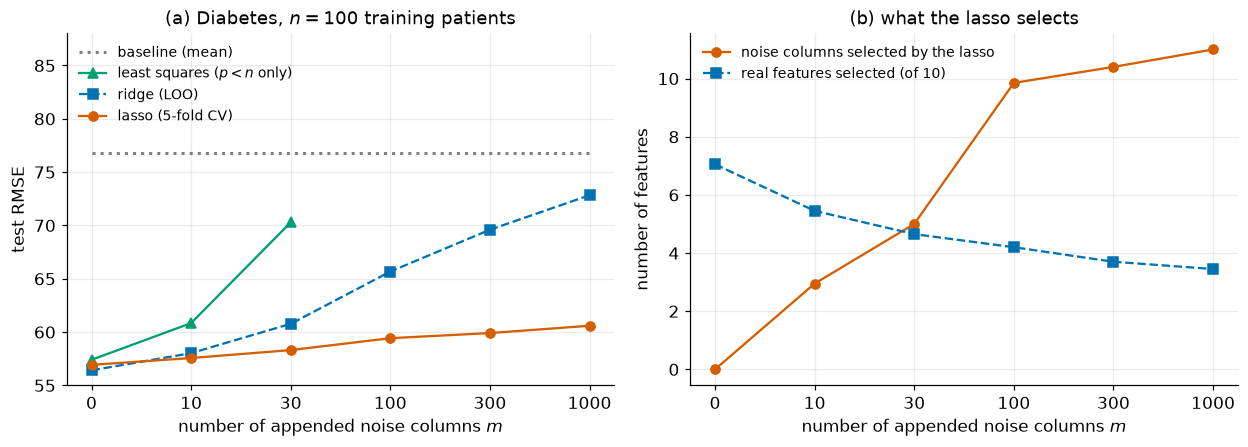

In [29]:
def figure_10_8():
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
    xs = np.arange(len(noise_table2))
    labels = [str(m) for m in noise_table2["noise columns m"]]
    ax = axes[0]
    ax.plot(xs, noise_table2["baseline"], ":", color="gray", lw=2, label="baseline (mean)")
    ax.plot(xs, noise_table2["least squares"], "^-", color=GREEN, label="least squares ($p<n$ only)")
    ax.plot(xs, noise_table2["ridge"], "s--", color=BLUE, label="ridge (LOO)")
    ax.plot(xs, noise_table2["lasso"], "o-", color=VERMILION, label="lasso (5-fold CV)")
    ax.set_xticks(xs)
    ax.set_xticklabels(labels)
    ax.set(xlabel="number of appended noise columns $m$", ylabel="test RMSE", title="(a) Diabetes, $n=100$ training patients", ylim=(55, 88))
    ax.legend(frameon=False, fontsize=9, loc="upper left")
    ax = axes[1]
    ax.plot(xs, noise_table2["noise features selected"], "o-", color=VERMILION, label="noise columns selected by the lasso")
    ax.plot(xs, noise_table2["features selected"] - noise_table2["noise features selected"], "s--", color=BLUE, label="real features selected (of 10)")
    ax.set_xticks(xs)
    ax.set_xticklabels(labels)
    ax.set(xlabel="number of appended noise columns $m$", ylabel="number of features", title="(b) what the lasso selects")
    ax.legend(frameon=False, fontsize=9)
    fig.tight_layout()
    plt.show()


figure_10_8()

Figure 10.8(a) gives the picture that the theory of the next paragraphs explains. Least squares fails first: with 30 noise columns ($p=40$ for $n=100$) its RMSE is $70.3$, and it cannot be computed beyond $p\approx n$. Ridge degrades steadily with the number of useless columns, from $56.4$ to $72.8$ at $m=1000$, which is $80\%$ of the way to the baseline of $76.8$: ridge spreads the weight over every feature and pays $\sigma^2/n$ for each. The lasso goes from $56.9$ to $60.6$, $19\%$ of the way: its error grows very slowly with $m$ (the two curves cross between $m=0$ and $m=10$). Panel (b) shows how: out of 1,000 noise columns the lasso keeps, on average, 11 ($1.1\%$), while the number of *real* features that it keeps falls from $7.0$ to $3.4$, because with 100 patients the weak real features can no longer be told from the noise. The lasso pays for its ignorance of the support by losing the weakest real features, not by fitting the noise.

The behavior of the lasso is explained by a bound in which the number of features appears only through its logarithm. We assume that the columns are normalized, $\lVert\mathbf{x}_j\rVert^2 = n$, and that $\mathbf{y} = \mathbf{X}\mathbf{w}^\ast + \boldsymbol\varepsilon$ with $\boldsymbol\varepsilon\sim\mathcal{N}(0,\sigma^2\mathbf{I})$. Nothing is assumed about the sparsity of $\mathbf{w}^\ast$ or the correlation of the features: the bound involves only $\lVert\mathbf{w}^\ast\rVert_1$.

:::{admonition} Theorem 10.12 (slow-rate bound for the lasso)
:class: tip
If $\lambda\ge\frac2n\lVert\mathbf{X}^\top\boldsymbol\varepsilon\rVert_\infty$, then $\ \frac1n\lVert\mathbf{X}(\hat{\mathbf{w}}_\lambda - \mathbf{w}^\ast)\rVert^2\le3\lambda\lVert\mathbf{w}^\ast\rVert_1$. For every $\delta\in(0,1)$ the choice $\lambda = 2\sigma\sqrt{2\ln(2p/\delta)/n}$ satisfies the condition with probability at least $1-\delta$, so that with that probability
$$
\frac1n\lVert\mathbf{X}(\hat{\mathbf{w}}_\lambda - \mathbf{w}^\ast)\rVert^2\ \le\ 6\sigma\,\lVert\mathbf{w}^\ast\rVert_1\sqrt{\frac{2\ln(2p/\delta)}{n}}.
\tag{10.7}$$
:::

:::{admonition} Proof
:class: dropdown
Write $\boldsymbol\Delta = \hat{\mathbf{w}}-\mathbf{w}^\ast$. *Basic inequality.* Since $\hat{\mathbf{w}}$ minimizes $F_\lambda$, $F_\lambda(\hat{\mathbf{w}})\le F_\lambda(\mathbf{w}^\ast)$. Substituting $\mathbf{y} = \mathbf{X}\mathbf{w}^\ast+\boldsymbol\varepsilon$, we have $\frac1{2n}\lVert\mathbf{y}-\mathbf{X}\hat{\mathbf{w}}\rVert^2 = \frac1{2n}\lVert\boldsymbol\varepsilon\rVert^2 - \frac1n\boldsymbol\varepsilon^\top\mathbf{X}\boldsymbol\Delta + \frac1{2n}\lVert\mathbf{X}\boldsymbol\Delta\rVert^2$, and $\frac1{2n}\lVert\mathbf{y}-\mathbf{X}\mathbf{w}^\ast\rVert^2 = \frac1{2n}\lVert\boldsymbol\varepsilon\rVert^2$. Cancelling the common term,
$$
\frac1{2n}\lVert\mathbf{X}\boldsymbol\Delta\rVert^2\le\frac1n\boldsymbol\varepsilon^\top\mathbf{X}\boldsymbol\Delta + \lambda\big(\lVert\mathbf{w}^\ast\rVert_1 - \lVert\hat{\mathbf{w}}\rVert_1\big).
$$
*The noise term.* By Hölder's inequality and the assumption on $\lambda$, $\frac1n\boldsymbol\varepsilon^\top\mathbf{X}\boldsymbol\Delta\le\frac1n\lVert\mathbf{X}^\top\boldsymbol\varepsilon\rVert_\infty\lVert\boldsymbol\Delta\rVert_1\le\frac\lambda2\big(\lVert\hat{\mathbf{w}}\rVert_1+\lVert\mathbf{w}^\ast\rVert_1\big)$. Hence $\frac1{2n}\lVert\mathbf{X}\boldsymbol\Delta\rVert^2\le\frac{3\lambda}2\lVert\mathbf{w}^\ast\rVert_1 - \frac\lambda2\lVert\hat{\mathbf{w}}\rVert_1\le\frac{3\lambda}{2}\lVert\mathbf{w}^\ast\rVert_1$, which is the first claim. *The probability.* Each $\frac1n\mathbf{x}_j^\top\boldsymbol\varepsilon$ is $\mathcal{N}(0,\sigma^2/n)$, so $\mathbb{P}(\lvert\frac1n\mathbf{x}_j^\top\boldsymbol\varepsilon\rvert>t)\le2e^{-nt^2/(2\sigma^2)}$ (the Chernoff bound of Section 3.5.2), and by the union bound $\mathbb{P}(\frac1n\lVert\mathbf{X}^\top\boldsymbol\varepsilon\rVert_\infty>t)\le2pe^{-nt^2/(2\sigma^2)}$. This equals $\delta$ for $t = \sigma\sqrt{2\ln(2p/\delta)/n}$, and $\lambda = 2t$. $\square$
:::

Read (10.7) as a statement about the price of features: the dimension enters through $\sqrt{\ln p}$, so *multiplying the number of useless features by 10 adds a constant to the bound*. Compare the $\ell_1$-ball Rademacher complexity of Exercise 3.9, which has the same $\sqrt{2\ln 2p}$ factor, while the $\ell_2$ complexity and the error of ridge or least squares grow with the dimension itself. The bound is "slow" because it decreases as $1/\sqrt{n}$ instead of $s\ln p/n$; the fast rate needs conditions on the correlation of the features (the restricted eigenvalue condition of Bickel, Ritov and Tsybakov, 2009, in the further reading), which the bound above does not need.

### 10.7.5 Sparse nonlinear features

Section 6.7 found that adding all the quadratic features to ridge regression on Diabetes did not help. A sparse model can pick the few interactions that matter out of the $65 = 10 + 10\cdot11/2$ features of degree at most two, so the lasso is the natural way to try the idea again. We use the 30 splits of the previous experiment, with the quadratic features computed on each training set.

In [30]:
rows = []
for name in ["least squares", "ridge", "lasso CV min", "lasso one-SE"]:
    d, t, pv = corrected_ttest(rs_quad[name], rs_lin["ridge"], 331, 111)
    rows.append({"method (65 quadratic features)": name, "test RMSE (mean of 30 splits)": np.sqrt(np.mean(rs_quad[name])),
                 "difference of MSE vs linear ridge": d, "corrected t": t, "p-value": pv})
print(pd.DataFrame(rows).round(3).to_string(index=False))
d, t, pv = corrected_ttest(rs_quad["lasso CV min"], rs_quad["ridge"], 331, 111)
print(f"quadratic lasso (CV min) vs quadratic ridge: difference of MSE {d:.1f}, corrected t = {t:.2f}, p = {pv:.3f}")
print(f"features selected on average among the 65: CV minimum {np.mean(rs_quad['nz min']):.1f}, one-SE {np.mean(rs_quad['nz 1se']):.1f}")

# On the 331/111 split: the same model once, and the largest coefficients.
pf2 = PolynomialFeatures(2, include_bias=False).fit(Xd_tr)
names2 = pf2.get_feature_names_out(feat)
sc2 = StandardScaler().fit(pf2.transform(Xd_tr))
P_tr, P_te = sc2.transform(pf2.transform(Xd_tr)), sc2.transform(pf2.transform(Xd_te))
lc2 = LassoCV(cv=kf10).fit(P_tr, yd_tr)
rmse_q = np.sqrt(np.mean((lc2.predict(P_te) - yd_te) ** 2))
top = np.argsort(-np.abs(lc2.coef_))[:8]
print(f"single 331/111 split: quadratic lasso test RMSE {rmse_q:.2f} with {int((lc2.coef_ != 0).sum())} features (linear lasso: {np.sqrt(np.mean((preds['lasso, CV minimum'] - yd_te) ** 2)):.2f})")
print("largest coefficients:", ", ".join(f"{names2[j]} ({lc2.coef_[j]:+.1f})" for j in top))

method (65 quadratic features)  test RMSE (mean of 30 splits)  difference of MSE vs linear ridge  corrected t  p-value
                 least squares                         62.605                            889.614        2.129    0.042
                         ridge                         56.506                            163.132        1.263    0.217
                  lasso CV min                         54.920                            -13.563       -0.174    0.863
                  lasso one-SE                         56.186                            127.077        1.334    0.193
quadratic lasso (CV min) vs quadratic ridge: difference of MSE -176.7, corrected t = -1.93, p = 0.063
features selected on average among the 65: CV minimum 17.3, one-SE 8.1


single 331/111 split: quadratic lasso test RMSE 50.81 with 20 features (linear lasso: 53.02)
largest coefficients: bmi (+23.0), s5 (+18.0), bp (+15.3), s3 (-12.2), sex^2 (-6.2), age sex (+4.9), bmi^2 (+3.9), s6^2 (+2.9)


Least squares on the 65 quadratic features is clearly worse than linear ridge ($62.6$ against $55.0$, corrected $p = 0.04$), ridge on the quadratic features loses a little ($56.5$, $p=0.22$), and the lasso at its minimum recovers the linear performance exactly ($54.9$, with $17.3$ of the 65 features selected on average): it beats the quadratic ridge by $177$ in MSE (corrected $p=0.063$, suggestive but not significant). So the sparse quadratic model removes the damage of the extra features, but **it does not improve on the linear model**, which is the conclusion of Section 6.7. The single $331/111$ split would have told another story: the quadratic lasso reached a test RMSE of $50.8$ against $53.0$ for the linear lasso on the same patients, a gain of $2.2$ points that disappears across 30 splits ($54.92$ against $54.94$): that split was lucky, the lesson of Chapter 5 again. The largest coefficients are those of the linear model (`bmi`, `s5`, `bp`, `s3`) followed by `sex^2`, `age sex`, `bmi^2` and `s6^2`. One detail is a small lesson of its own: `sex` takes only two values in this data set, so `sex^2` is an affine function of `sex` and the two columns are perfectly correlated; the lasso kept `sex^2` and not `sex`, an arbitrary choice among identical columns, which is the subject of Exercise 10.3 and of the next section.

## 10.8 Correlated features and the elastic net

The lasso has a weakness that the previous sections have already shown twice. On the Diabetes path (Figure 10.5) the correlated features `s1`, `s2` and `s3` leave and re-enter the model, and in the quadratic experiment the lasso kept `sex^2` and dropped `sex`, although the two columns are identical. When several features carry the same information the lasso keeps one of them, and *which one* depends on small perturbations of the data: it is a coin toss. If the features are only *similar*, as the three serum measurements are, the toss can change from one sample to the next, and the list of selected features is not reproducible. A remedy that keeps the sparsity and removes the toss was proposed by Zou and Hastie (2005): add a ridge penalty.

:::{admonition} Definition 10.3 (elastic net)
:class: tip
For $\lambda_1>0$ and $\lambda_2\ge0$, the **elastic net** estimator minimizes
$$
F_{\lambda_1,\lambda_2}(\mathbf{w}) = \frac1{2n}\lVert\mathbf{y}-\mathbf{Z}\mathbf{w}\rVert^2 + \lambda_1\lVert\mathbf{w}\rVert_1 + \frac{\lambda_2}{2}\lVert\mathbf{w}\rVert_2^2.
\tag{10.8}$$
In scikit-learn, `ElasticNet(alpha, l1_ratio)` has $\lambda_1 = \text{alpha}\cdot\text{l1\_ratio}$ and $\lambda_2 = \text{alpha}\,(1-\text{l1\_ratio})$.
:::

The objective is *strictly* convex for $\lambda_2>0$, so the solution is unique even when $p>n$ or when columns are repeated, and it keeps the zeros of the lasso, because the penalty is still non-differentiable at $w_j=0$. Everything we learned about the lasso carries over, thanks to a trick.

:::{admonition} Proposition 10.13 (the elastic net is a lasso on augmented data)
:class: tip
Let $\tilde{\mathbf{Z}} = \begin{bmatrix}\mathbf{Z}\\ \sqrt{n\lambda_2}\,\mathbf{I}_p\end{bmatrix}\in\mathbb{R}^{(n+p)\times p}$ and $\tilde{\mathbf{y}} = \begin{bmatrix}\mathbf{y}\\ \mathbf{0}\end{bmatrix}$. Then $F_{\lambda_1,\lambda_2}(\mathbf{w}) = \frac1{2n}\lVert\tilde{\mathbf{y}}-\tilde{\mathbf{Z}}\mathbf{w}\rVert^2+\lambda_1\lVert\mathbf{w}\rVert_1$ for every $\mathbf{w}$: the elastic net on $(\mathbf{Z},\mathbf{y})$ is a lasso problem on $(n+p)$ examples, whose design has rank $p$ whatever $\mathbf{Z}$ is.
:::

*Proof.* $\lVert\tilde{\mathbf{y}}-\tilde{\mathbf{Z}}\mathbf{w}\rVert^2 = \lVert\mathbf{y}-\mathbf{Z}\mathbf{w}\rVert^2 + n\lambda_2\lVert\mathbf{w}\rVert^2$; divide by $2n$. $\square$

The proposition says that every solver of Section 10.6 solves the elastic net, that the coordinate update is $w_j\leftarrow S_{\lambda_1}(\cdot)/(1+\lambda_2)$ (the extra term adds $\lambda_2$ to the curvature $\frac1n\lVert\mathbf{z}_j\rVert^2=1$), and, by the rank statement, that the solution is unique. The next cell checks the identity on the Diabetes training set and then repeats the column of `bmi`.

In [31]:
lam1, lam2 = 2.0, 1.0
en_fit = ElasticNet(alpha=lam1 + lam2, l1_ratio=lam1 / (lam1 + lam2), fit_intercept=False, tol=1e-12, max_iter=200000).fit(Zd, yc)
Z_aug = np.vstack([Zd, np.sqrt(n_d * lam2) * np.eye(p_d)])
y_aug = np.r_[yc, np.zeros(p_d)]
# scikit-learn divides the squared error by 2 * (number of rows): n + p here, not n
las_aug = Lasso(alpha=lam1 * n_d / (n_d + p_d), fit_intercept=False, tol=1e-12, max_iter=200000).fit(Z_aug, y_aug)
print(f"elastic net on (Z, y) vs lasso on the augmented data: max |difference of the weights| = {np.abs(en_fit.coef_ - las_aug.coef_).max():.1e}")
print(f"non-zero weights of the elastic net (lambda1={lam1}, lambda2={lam2}): {int((en_fit.coef_ != 0).sum())} of {p_d}")

# Repeated column: the data term depends only on the sum of the two weights.
Z_dup = np.column_stack([Zd, Zd[:, 2]])          # the last column is a copy of bmi (column 2)
rows = []
for name, l1, l2 in [("lasso", 6.0, 0.0), ("elastic net", 6.0, 6.0)]:
    m = ElasticNet(alpha=l1 + l2, l1_ratio=l1 / (l1 + l2), fit_intercept=False, tol=1e-12, max_iter=200000).fit(Z_dup, yc)
    rows.append({"method": name, "weight of bmi": m.coef_[2], "weight of its copy": m.coef_[10], "sum": m.coef_[2] + m.coef_[10]})
print(pd.DataFrame(rows).round(3).to_string(index=False))

elastic net on (Z, y) vs lasso on the augmented data: max |difference of the weights| = 2.2e-15
non-zero weights of the elastic net (lambda1=2.0, lambda2=1.0): 9 of 10
     method  weight of bmi  weight of its copy    sum
      lasso         24.390               0.417 24.807
elastic net          4.266               4.266  8.531


The identity holds to $2\cdot10^{-15}$: the elastic net on $(\mathbf{Z},\mathbf{y})$ and the lasso on the augmented data return the same vector (nine of the ten features are kept for $\lambda_1=2$, $\lambda_2=1$). With the copy of `bmi` appended, the data term depends only on the *sum* of the two weights, so the lasso is indifferent to how the sum is split between the two columns: any split with the same sign has the same objective, and the solver returns one of them, $24.4$ and $0.4$ (another algorithm, or the columns in another order, would return another). The elastic net returns the equal split, $4.27$ and $4.27$, which by strict convexity is the unique minimizer. The sum is smaller than that of the lasso ($8.5$ against $24.8$) because the second penalty, with $\lambda_2=6$ large compared with the curvature $1$ of the data term, also shrinks.

### 10.8.1 The grouping effect

The repeated column is the extreme case. The theorem says that the equal split is not an accident of exact copies: it degrades gracefully with the correlation.

:::{admonition} Theorem 10.14 (grouping effect; Zou and Hastie, 2005)
:class: tip
Let the columns of $\mathbf{Z}$ be standardized, $\frac1n\lVert\mathbf{z}_j\rVert^2=1$, the response centered, $\lambda_2>0$, and let $\hat{\mathbf{w}}$ minimize (10.8). Write $\rho_{ij} = \frac1n\mathbf{z}_i^\top\mathbf{z}_j$. If $\hat w_i\hat w_j>0$ (both weights non-zero, with the same sign), then
$$
\lvert\hat w_i-\hat w_j\rvert\ \le\ \frac{\lVert\mathbf{y}\rVert}{\sqrt{n}\,\lambda_2}\sqrt{2(1-\rho_{ij})}.
\tag{10.9}$$
In particular two identical columns ($\rho_{ij}=1$) that are both selected receive the same weight.
:::

:::{admonition} Proof
:class: dropdown
Let $\mathbf{r}=\mathbf{y}-\mathbf{Z}\hat{\mathbf{w}}$. The optimality condition of Theorem 10.7 with the extra term $\lambda_2 w_j$ says that, for a coordinate with $\hat w_j\ne0$, $-\frac1n\mathbf{z}_j^\top\mathbf{r}+\lambda_1\operatorname{sign}(\hat w_j)+\lambda_2\hat w_j=0$. Write it for $i$ and $j$ and subtract: since the signs are equal, the terms in $\lambda_1$ cancel and $\lambda_2(\hat w_i-\hat w_j)=\frac1n(\mathbf{z}_i-\mathbf{z}_j)^\top\mathbf{r}$. By the Cauchy–Schwarz inequality, $\lvert\hat w_i-\hat w_j\rvert\le\frac1{n\lambda_2}\lVert\mathbf{z}_i-\mathbf{z}_j\rVert\lVert\mathbf{r}\rVert$, and $\lVert\mathbf{z}_i-\mathbf{z}_j\rVert^2 = 2n(1-\rho_{ij})$. Finally $F(\hat{\mathbf{w}})\le F(\mathbf{0})$ gives $\frac1{2n}\lVert\mathbf{r}\rVert^2\le\frac1{2n}\lVert\mathbf{y}\rVert^2$, so $\lVert\mathbf{r}\rVert\le\lVert\mathbf{y}\rVert$. Combining the three facts gives (10.9). $\square$
:::

The bound is proportional to $1/\lambda_2$ (no ridge, no grouping: the lasso is the case $\lambda_2=0$, where the bound is vacuous) and to $\sqrt{1-\rho_{ij}}$. It is not tight, as the experiment will show, but it is a guarantee that holds for every sample. The experiment below is a **constructed example**, flagged as such: we add to the Diabetes training features a *twin* of `bmi`, equal to `bmi` plus Gaussian noise with a standard deviation of a tenth of that of `bmi` (correlation $0.996$), and ask whether the methods split the weight of `bmi` consistently between the two when the training set is resampled. We draw 200 bootstrap samples of the 331 training patients, and on each we standardize, fit the lasso ($\lambda_1=1$) and the elastic net ($\lambda_1=1$, $\lambda_2=1$) and record the weights of the two columns.

In [32]:
tw_rng = np.random.default_rng(SEED)
twin = Xd_tr[:, 2] + 0.1 * Xd_tr[:, 2].std() * tw_rng.normal(size=n_d)
XT = np.column_stack([Xd_tr, twin])                    # 11 columns: the ten features and the twin of bmi
print(f"correlation between bmi and its twin: {np.corrcoef(XT[:, 2], XT[:, 10])[0, 1]:.4f}")


def fit_en(X, y, l1, l2):
    """Standardize, center y, fit the elastic net (l2 = 0 is the lasso); return weights and the quantities of Theorem 10.14."""
    Zs = StandardScaler().fit_transform(X)
    yy = y - y.mean()
    m = ElasticNet(alpha=l1 + l2, l1_ratio=l1 / (l1 + l2), fit_intercept=False, tol=1e-10, max_iter=100000).fit(Zs, yy)
    rho = Zs[:, 2] @ Zs[:, 10] / len(yy)
    return m.coef_, rho, np.linalg.norm(yy) / np.sqrt(len(yy))


tw_B = 200
tw_idx = np.random.default_rng(SEED + 1).integers(0, n_d, size=(tw_B, n_d))
tw = {}
for name, l1, l2 in [("lasso", 1.0, 0.0), ("elastic net", 1.0, 1.0)]:
    out = [fit_en(XT[ix], yd_tr[ix], l1, l2) for ix in tw_idx]
    W = np.array([o[0] for o in out])
    bound = np.array([o[2] * np.sqrt(2 * (1 - o[1])) / l2 if l2 > 0 else np.inf for o in out])
    tw[name] = {"W": W, "bound": bound, "l2": l2}

rows = []
for name, d in tw.items():
    W = d["W"]
    both = (W[:, 2] * W[:, 10] > 0)
    gap = np.abs(W[:, 2] - W[:, 10])
    rows.append({"method": name,
                 "mean w(bmi)": W[:, 2].mean(), "mean w(twin)": W[:, 10].mean(),
                 "sd w(bmi)": W[:, 2].std(), "sd of the sum": (W[:, 2] + W[:, 10]).std(),
                 "only one of the two non-zero": np.mean((W[:, [2, 10]] != 0).sum(axis=1) == 1),
                 "max gap |w(bmi) - w(twin)|": gap.max(),
                 "replicates with both non-zero, same sign": int(both.sum()),
                 "bound (10.9) holds in all of them": bool(np.all(gap[both] <= d["bound"][both] + 1e-9)) if d["l2"] > 0 else "no bound"})
print(pd.DataFrame(rows).round(3).T.to_string(header=False))
print(f"median value of the bound (10.9) for the elastic net: {np.median(tw['elastic net']['bound']):.2f}")

correlation between bmi and its twin: 0.9957


method                                       lasso  elastic net
mean w(bmi)                                 12.659       10.392
mean w(twin)                                13.406       10.386
sd w(bmi)                                   11.627        1.151
sd of the sum                                4.093          2.3
only one of the two non-zero                  0.67          0.0
max gap |w(bmi) - w(twin)|                  37.784        0.814
replicates with both non-zero, same sign        66          200
bound (10.9) holds in all of them         no bound         True
median value of the bound (10.9) for the elastic net: 7.20


The lasso knows the *total* weight but not how to divide it. The mean weights of the two columns are similar ($12.7$ and $13.4$) but each of them has a standard deviation of about $12$, the standard deviation of their sum is only $4.1$, and in $67\%$ of the samples exactly one of the two columns is non-zero (both were non-zero, with the same sign, in only 66 of the 200 samples); the scatter plot of Figure 10.9(a) shows the lasso's samples lying on the two axes, with gaps as large as $38$. The elastic net gives both columns a non-zero weight in all 200 samples, the two weights are almost equal (the largest gap is $0.8$) and each has a standard deviation of $1.2$. The bound (10.9) holds in all 200 samples, with a median value of $7.2$, nine times the largest gap observed: it is a guarantee, not a prediction of the size of the effect.

### 10.8.2 Stability of the selected set

Does the elastic net also select a more reproducible *set*? We measure it on the ten real Diabetes features, without the twin. For each of 100 bootstrap samples we fit the model, record the selected set, and measure the agreement of two sets $A$ and $B$ by the Jaccard index $\lvert A\cap B\rvert/\lvert A\cup B\rvert$, averaged over 2,000 random pairs of bootstrap samples. A larger model is trivially more stable (the full set of ten features always agrees with itself), so the comparison is meaningful only at equal model size: we trace the mean Jaccard index against the *mean number of selected features* as the penalty varies, for the lasso and for the elastic net with $\lambda_1=\lambda_2$ (`l1_ratio=0.5`).

In [33]:
def stability_curve(alphas, l1_ratio, B=100):
    """Mean model size and mean pairwise Jaccard index of the selected sets over B bootstrap samples, for each alpha."""
    idx_b = np.random.default_rng(SEED + 2).integers(0, n_d, size=(B, n_d))
    pairs = np.random.default_rng(SEED + 3).integers(0, B, size=(2000, 2))
    pairs = pairs[pairs[:, 0] != pairs[:, 1]]
    out = []
    for a in alphas:
        sel = np.zeros((B, p_d), bool)
        for b, ix in enumerate(idx_b):
            Zs = StandardScaler().fit_transform(Xd_tr[ix])
            sel[b] = ElasticNet(alpha=a, l1_ratio=l1_ratio, fit_intercept=False, tol=1e-8, max_iter=50000).fit(Zs, yd_tr[ix] - yd_tr[ix].mean()).coef_ != 0
        inter = (sel[pairs[:, 0]] & sel[pairs[:, 1]]).sum(axis=1)
        union = (sel[pairs[:, 0]] | sel[pairs[:, 1]]).sum(axis=1)
        out.append((sel.sum(axis=1).mean(), np.mean(np.where(union > 0, inter / np.maximum(union, 1), 1.0)), sel.mean(axis=0)))
    return out


stab_lasso = stability_curve(np.logspace(-0.5, 1.7, 12), 1.0)
stab_en = stability_curve(np.logspace(0.0, 1.9, 12), 0.5)
rows = []
for name, st in [("lasso", stab_lasso), ("elastic net, l1_ratio 0.5", stab_en)]:
    for size, jac, freq in st[::2]:
        rows.append({"method": name, "mean model size": size, "mean Jaccard index": jac})
print(pd.DataFrame(rows).round(3).to_string(index=False))
for name, st in [("lasso", stab_lasso), ("elastic net", stab_en)]:
    k = int(np.argmin([abs(s[0] - 7.0) for s in st]))
    print(f"{name}, the setting with mean size nearest to 7 ({st[k][0]:.2f}): selection frequency of " + ", ".join(f"{f}: {q:.2f}" for f, q in zip(feat, st[k][2])))

                   method  mean model size  mean Jaccard index
                    lasso             9.05               0.869
                    lasso             8.35               0.817
                    lasso             7.51               0.733
                    lasso             5.80               0.735
                    lasso             4.18               0.833
                    lasso             2.08               0.907
elastic net, l1_ratio 0.5             9.87               0.975
elastic net, l1_ratio 0.5             9.25               0.896
elastic net, l1_ratio 0.5             8.72               0.858
elastic net, l1_ratio 0.5             8.40               0.871
elastic net, l1_ratio 0.5             7.31               0.850
elastic net, l1_ratio 0.5             5.45               0.854
lasso, the setting with mean size nearest to 7 (6.70): selection frequency of age: 0.34, sex: 0.93, bmi: 1.00, bp: 1.00, s1: 0.40, s2: 0.41, s3: 1.00, s4: 0.16, s5: 1.00, s6: 0.46
e

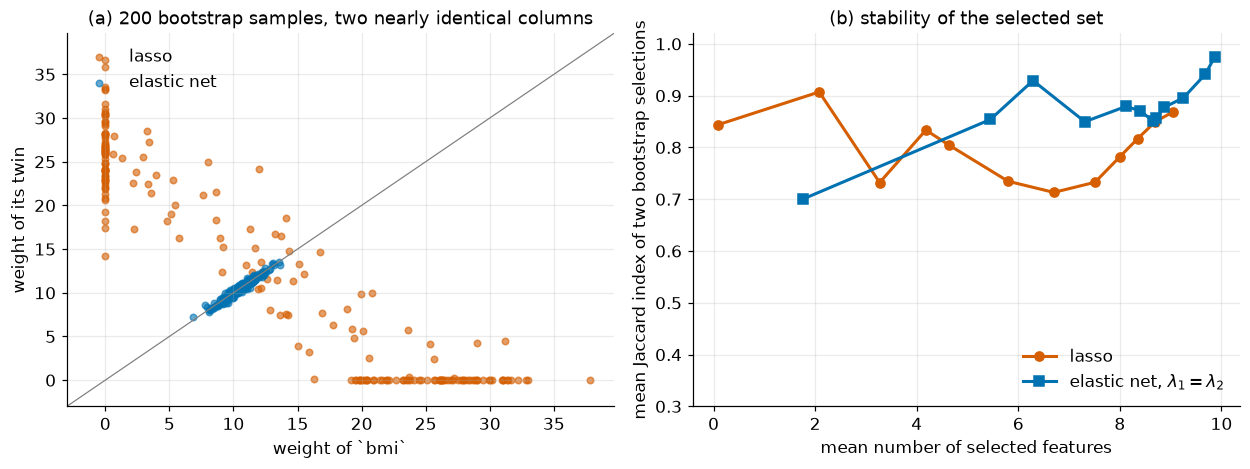

In [34]:
def figure_10_9():
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
    ax = axes[0]
    ax.scatter(tw["lasso"]["W"][:, 2], tw["lasso"]["W"][:, 10], s=18, color=VERMILION, alpha=0.6, label="lasso")
    ax.scatter(tw["elastic net"]["W"][:, 2], tw["elastic net"]["W"][:, 10], s=18, color=BLUE, alpha=0.6, label="elastic net")
    lim = [-3, max(tw["lasso"]["W"][:, [2, 10]].max(), 20) * 1.05]
    ax.plot(lim, lim, color="gray", lw=0.8)
    ax.set(xlabel="weight of `bmi`", ylabel="weight of its twin", title="(a) 200 bootstrap samples, two nearly identical columns", xlim=lim, ylim=lim)
    ax.legend(frameon=False, loc="upper left")
    ax = axes[1]
    ax.plot([s[0] for s in stab_lasso], [s[1] for s in stab_lasso], "o-", color=VERMILION, lw=2, label="lasso")
    ax.plot([s[0] for s in stab_en], [s[1] for s in stab_en], "s-", color=BLUE, lw=2, label=r"elastic net, $\lambda_1=\lambda_2$")
    ax.set(xlabel="mean number of selected features", ylabel="mean Jaccard index of two bootstrap selections", title="(b) stability of the selected set", ylim=(0.3, 1.02))
    ax.legend(frameon=False, loc="lower right")
    fig.tight_layout()
    plt.show()


figure_10_9()

Figure 10.9(b) shows that at the same model size the elastic net is more reproducible than the lasso, but not uniformly and not by much. For models of between five and eight features on average, the mean Jaccard index of the lasso falls to $0.71$ to $0.74$ and that of the elastic net stays between $0.85$ and $0.87$; at the two ends (nearly the full model, or two or three features) the curves are close. The frequencies at the setting with seven features say what the difference is. The lasso always keeps `bmi`, `bp`, `s3` and `s5` and nearly always `sex` ($0.93$), and tosses a coin among `age`, `s1`, `s2`, `s4` and `s6` (frequencies $0.16$ to $0.46$). The elastic net keeps `bmi`, `bp`, `s3`, `s4`, `s5` and `s6` in every sample, `age` in $69\%$ and never `sex`: a reproducible set, but a *different* one from the lasso's. Stability measures how well the procedure agrees with itself on resampled data, not whether the selected set is the true one. The figure is one data set and 100 resamples, and the wiggles of the curves show its noise: we take from it the direction of the effect, not its size. On Diabetes the cross-validated elastic net of Section 10.7.3 chose an $\ell_1$ ratio of $0.1$, nearly ridge, and kept all ten features: the prediction does not need the selection.

## 10.9 Sparse classification

Everything in this chapter carries over to classification by changing the loss. The **$\ell_1$-penalized logistic regression** minimizes the average logistic loss plus the $\ell_1$ norm of the weights, with the intercept left free:
$$
\min_{b,\mathbf{w}}\ \ \frac1n\sum_{i=1}^n\Big[\ln\!\big(1+e^{b+\mathbf{z}_i^\top\mathbf{w}}\big)-y_i\,(b+\mathbf{z}_i^\top\mathbf{w})\Big]+\lambda\lVert\mathbf{w}\rVert_1,\qquad y_i\in\{0,1\}.
\tag{10.10}$$
The objective is convex but not quadratic, so the soft-threshold of Proposition 10.6 is not exact, but proximal gradient works unchanged (the gradient of the loss is Lipschitz, Section 6.5) and so does coordinate descent with a quadratic approximation of the loss at each step. In scikit-learn the problem is `LogisticRegression(l1_ratio=1, solver="saga", C=C)` with $\lambda = 1/(nC)$ (the `liblinear` solver would also penalize the intercept, and we avoid it). The optimality condition at $\mathbf{w}=\mathbf{0}$ gives the analogue of Theorem 10.7.

:::{admonition} Proposition 10.15 (the smallest penalty that gives the zero model)
:class: tip
Let the columns of $\mathbf{Z}$ be standardized. The minimizer of (10.10) has $\hat{\mathbf{w}}=\mathbf{0}$ if and only if $\lambda\ge\lambda_{\max} = \frac1n\lVert\mathbf{Z}^\top(\mathbf{y}-\bar y\mathbf{1})\rVert_\infty$, and then $\hat b=\ln\frac{\bar y}{1-\bar y}$.
:::

*Proof.* The derivative of the loss with respect to $b$ is $\frac1n\sum_i(\sigma(b+\mathbf{z}_i^\top\mathbf{w})-y_i)$; at $\mathbf{w}=\mathbf{0}$ it vanishes if and only if $\sigma(b)=\bar y$, which gives $\hat b$. The derivative with respect to $w_j$ at that point is $\frac1n\sum_i(\bar y-y_i)z_{ij} = -\frac1n\mathbf{z}_j^\top(\mathbf{y}-\bar y\mathbf{1})$, and by the optimality condition for a convex function plus $\lambda\lVert\cdot\rVert_1$ (the argument of Theorem 10.7), $\mathbf{w}=\mathbf{0}$ is optimal if and only if $\lvert\frac1n\mathbf{z}_j^\top(\mathbf{y}-\bar y\mathbf{1})\rvert\le\lambda$ for all $j$. $\square$

We use the **Breast Cancer** data with the stratified $426/143$ split of Chapters 6, 8 and 9, malignant $=1$, standardized with the training statistics.

In [35]:
bc = load_breast_cancer()
bc_y_all = 1 - bc.target                                        # malignant = 1, as in Chapter 6
bc_Xtr, bc_Xte, bc_ytr, bc_yte = train_test_split(bc.data, bc_y_all, test_size=0.25, random_state=SEED, stratify=bc_y_all)
bc_sc = StandardScaler().fit(bc_Xtr)
bc_Ztr, bc_Zte = bc_sc.transform(bc_Xtr), bc_sc.transform(bc_Xte)
bc_n, bc_p = bc_Ztr.shape
print(f"{bc_n} training and {len(bc_yte)} test examples, {bc_p} features, {bc_ytr.sum()} malignant in the training set")


def make_logit(C, l1_ratio, tol, warm=False):
    """l1 penalty (l1_ratio = 1): saga; l2 penalty (l1_ratio = 0): the default lbfgs solver, much faster for this penalty."""
    if l1_ratio == 0:
        return LogisticRegression(C=C, tol=tol, max_iter=100000, warm_start=warm)
    return LogisticRegression(l1_ratio=l1_ratio, C=C, solver="saga", max_iter=100000, tol=tol, warm_start=warm)


def logit(Z, y, C, l1_ratio, tol=1e-8):
    return make_logit(C, l1_ratio, tol).fit(Z, y)


def logit_path(Z, y, Cs, l1_ratio, tol=1e-6, max_iter=3000):
    """Solutions along an increasing grid of C, each warm-started from the previous one. The cap on the iterations of saga only matters for
    the weakest penalties (near-separable data), far to the right of the cross-validation minimum."""
    m = make_logit(Cs[0], l1_ratio, tol, warm=True).set_params(max_iter=max_iter)
    W, b = [], []
    for C in Cs:
        m.set_params(C=C).fit(Z, y)
        W.append(m.coef_[0].copy()); b.append(m.intercept_[0])
    return np.array(W), np.array(b)


def path_log_loss(Z, y, W, b):
    """Log loss of every solution of a path on (Z, y): returns one value per row of W."""
    z = Z @ W.T + b
    return np.mean(np.logaddexp(0, z) - y[:, None] * z, axis=0)


lam_max_lg = np.max(np.abs(bc_Ztr.T @ (bc_ytr - bc_ytr.mean()))) / bc_n
C_max = 1 / (bc_n * lam_max_lg)
grad0 = np.abs(bc_Ztr.T @ (bc_ytr - bc_ytr.mean())) / bc_n          # |gradient of the loss at w = 0|, one value per feature
top2 = np.argsort(-grad0)[:2]
first = ", ".join(f"{bc.feature_names[j]} ({grad0[j]:.4f})" for j in top2)
for f in [0.98, 1.0005]:
    m = logit(bc_Ztr, bc_ytr, f * C_max, 1.0, tol=1e-12)
    print(f"C = {f:.2f} * C_max ({f * C_max:.4f}): {int((m.coef_ != 0).sum())} non-zero weight(s)" + (f" ({bc.feature_names[np.flatnonzero(m.coef_[0])[0]]})" if (m.coef_ != 0).any() else ""))
print(f"lambda_max = {lam_max_lg:.4f}, C_max = 1/(n lambda_max) = {C_max:.4f}; logit of the malignant fraction: {np.log(bc_ytr.mean() / (1 - bc_ytr.mean())):+.3f}; the two largest values of |gradient| (the first features to enter): {first}")

426 training and 143 test examples, 30 features, 159 malignant in the training set
C = 0.98 * C_max (0.0061): 0 non-zero weight(s)


C = 1.00 * C_max (0.0062): 1 non-zero weight(s) (worst concave points)
lambda_max = 0.3774, C_max = 1/(n lambda_max) = 0.0062; logit of the malignant fraction: -0.518; the two largest values of |gradient| (the first features to enter): worst concave points (0.3774), worst perimeter (0.3769)


At $0.98\,C_{\max}$ the solver returns the zero vector, and at $1.0005\,C_{\max}$ a single non-zero weight, that of `worst concave points`, the feature with the largest absolute gradient ($0.3774$), as the proposition says. The runner-up, `worst perimeter`, is only $0.1\%$ behind ($0.3769$), so a factor of $1.02$ would already have admitted it: the first feature to enter is decided by a hair when features are this correlated. (We do not print the intercept of the solver for the zero model: `saga` stops as soon as the weights stop changing, so its intercept is only accurate to about $0.01$, whereas the proposition gives it exactly, $-0.518$.)

We now choose $C$ by 10-fold cross-validated log loss on the training set, for the $\ell_1$ and the $\ell_2$ penalty, with the one-standard-error rule for the $\ell_1$ model, and evaluate each choice once on the 143 test patients.

In [36]:
bc_grid = np.logspace(-2.2, 0.4, 14)
bc_skf = StratifiedKFold(10, shuffle=True, random_state=SEED)
bc_cv = {}
t0 = time.time()
for pen, l1r in [("l1", 1.0), ("l2", 0.0)]:
    L = np.zeros((len(bc_grid), 10))
    for f, (tr, va) in enumerate(bc_skf.split(bc_Ztr, bc_ytr)):
        W_, b_ = logit_path(bc_Ztr[tr], bc_ytr[tr], bc_grid, l1r)
        L[:, f] = path_log_loss(bc_Ztr[va], bc_ytr[va], W_, b_)
    bc_cv[pen] = (L.mean(axis=1), L.std(axis=1, ddof=1) / np.sqrt(10))
print(f"[cross-validation: {time.time() - t0:.0f} s]")

bc_choice = {}
k_min = int(np.argmin(bc_cv["l1"][0]))
thr = bc_cv["l1"][0][k_min] + bc_cv["l1"][1][k_min]
bc_choice["l1, CV minimum"] = ("l1", 1.0, bc_grid[k_min])
bc_choice["l1, one-SE"] = ("l1", 1.0, bc_grid[np.flatnonzero(bc_cv["l1"][0] <= thr)[0]])
bc_choice["l2, CV minimum"] = ("l2", 0.0, bc_grid[int(np.argmin(bc_cv["l2"][0]))])
rows, bc_models = [], {}
for name, (pen, l1r, C) in bc_choice.items():
    m = logit(bc_Ztr, bc_ytr, C, l1r, tol=1e-10)
    bc_models[name] = m
    pr = m.predict_proba(bc_Zte)[:, 1]
    rows.append({"model": name, "C": C, "non-zero weights": int((m.coef_ != 0).sum()), "CV log loss": bc_cv[pen][0][list(bc_grid).index(C)],
                 "test log loss": log_loss(bc_yte, pr), "test errors (of 143)": int((m.predict(bc_Zte) != bc_yte).sum())})
print(pd.DataFrame(rows).round(4).to_string(index=False))
m1 = bc_models["l1, one-SE"]
print("one-SE model:", ", ".join(f"{bc.feature_names[j]} ({m1.coef_[0, j]:+.2f})" for j in np.argsort(-np.abs(m1.coef_[0]))[: int((m1.coef_ != 0).sum())]))

[cross-validation: 13 s]


         model     C  non-zero weights  CV log loss  test log loss  test errors (of 143)
l1, CV minimum 1.000                14       0.0828         0.0728                     4
    l1, one-SE 0.631                12       0.0912         0.0718                     3
l2, CV minimum 1.000                30       0.0824         0.0776                     5
one-SE model: worst radius (+3.03), radius error (+2.20), worst texture (+1.70), mean concave points (+1.55), worst concavity (+0.74), compactness error (-0.51), worst symmetry (+0.49), worst concave points (+0.44), texture error (-0.39), fractal dimension error (-0.28), worst smoothness (+0.26), smoothness error (+0.23)


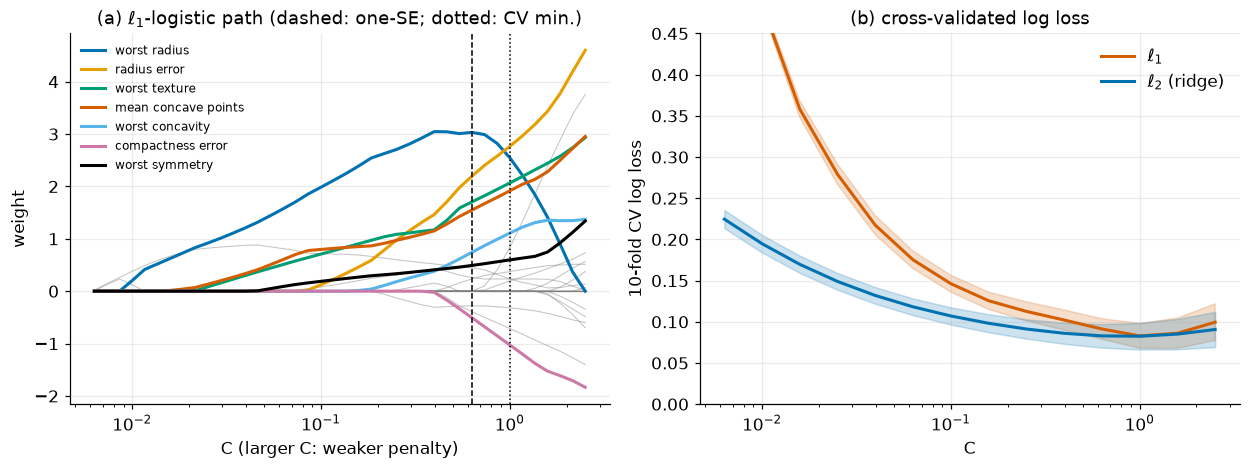

In [37]:
def figure_10_10():
    path_C = np.logspace(-2.2, 0.4, 40)
    W, _ = logit_path(bc_Ztr, bc_ytr, path_C, 1.0)
    w1 = bc_models["l1, one-SE"].coef_[0]
    sel = np.argsort(-np.abs(w1))[:7]                              # the seven largest weights of the one-SE model are drawn in color
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
    ax = axes[0]
    for j in range(bc_p):
        if j not in sel:
            ax.semilogx(path_C, W[:, j], color="gray", lw=0.7, alpha=0.45)
    colors = [BLUE, ORANGE, GREEN, VERMILION, SKY, PURPLE, "black"]
    for c, j in zip(colors, sel):
        ax.semilogx(path_C, W[:, j], color=c, lw=2, label=bc.feature_names[j])
    ax.axvline(bc_choice["l1, one-SE"][2], color="black", ls="--", lw=1)
    ax.axvline(bc_choice["l1, CV minimum"][2], color="black", ls=":", lw=1)
    ax.set(xlabel="C (larger C: weaker penalty)", ylabel="weight", title=r"(a) $\ell_1$-logistic path (dashed: one-SE; dotted: CV min.)")
    ax.legend(frameon=False, fontsize=8, loc="upper left", ncol=1)
    ax = axes[1]
    for pen, c, lab in [("l1", VERMILION, r"$\ell_1$"), ("l2", BLUE, r"$\ell_2$ (ridge)")]:
        mu, se = bc_cv[pen]
        ax.semilogx(bc_grid, mu, color=c, lw=2, label=lab)
        ax.fill_between(bc_grid, mu - se, mu + se, color=c, alpha=0.2)
    ax.set(xlabel="C", ylabel="10-fold CV log loss", title="(b) cross-validated log loss", ylim=(0, 0.45))
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()


figure_10_10()

Panel (b) of Figure 10.10 shows that the two penalties are not competitors on prediction: with a strong penalty the $\ell_1$ model is worse (it has few features and shrinks the rest to zero: at the left end of the grid the model is empty), and from $C\approx 0.6$ on the two curves coincide, with minima of $0.0828$ ($\ell_1$) and $0.0824$ ($\ell_2$), both at $C=1$. On the 143 test patients the three models make $4$, $3$ and $5$ errors (log loss $0.073$, $0.072$ and $0.078$), and the difference between $3$ and $5$ errors is within the noise (the standard error of an accuracy near $97\%$ on 143 patients is $1.4$ points, about two patients, Section 5.2.2). What sparsity bought here is modest in size: the one-SE model keeps $12$ of the $30$ features, not the five that one might hope for, because the 30 features are three versions (mean, standard error, worst value) of the same 10 measurements, and several of them are nearly collinear; the largest weights are those of `worst radius`, `radius error`, `worst texture` and `mean concave points`. Panel (a) shows once more the non-monotone path of the lasso: the weight of `worst radius`, the largest at the one-SE value ($+3.03$), rises, then falls to zero at the right end of the grid, while other features take over.

### 10.9.1 When $p>n$: the weights leave the row space

Chapter 9 proved that for the $\ell_2$ penalty the solution is a combination of the training examples (Theorem 9.4): $\hat{\mathbf{w}}=\sum_i\alpha_i\mathbf{z}_i$ lies in the row space of $\mathbf{Z}$, a subspace of dimension at most $n$, so that when $p>n$ the weights along the directions orthogonal to every training example are exactly zero. The $\ell_1$ penalty is *not* a function of the length of $\mathbf{w}$, but of its coordinates, and the theorem does not apply: the sparse solution has its zeros along the coordinate axes, and these do not respect the row space. We verify it on a real problem of the right shape, the **Digits** data restricted to the digits 3 and 8 (images of $8\times8$ pixels, so $p=64$), with a random subset of $n=40$ training images, and then look at the weights on a larger training set.

In [38]:
dg = load_digits()
dg_mask = (dg.target == 3) | (dg.target == 8)
dg_X, dg_y = dg.data[dg_mask], (dg.target[dg_mask] == 8).astype(int)
dg_Xtr, dg_Xte, dg_ytr, dg_yte = train_test_split(dg_X, dg_y, test_size=0.25, random_state=SEED, stratify=dg_y)
dg_sc = StandardScaler().fit(dg_Xtr)
live = dg_Xtr.std(axis=0) > 0                                        # a few border pixels are constant (always zero)
dg_Ztr, dg_Zte = dg_sc.transform(dg_Xtr), dg_sc.transform(dg_Xte)
dg_Ztr[:, ~live], dg_Zte[:, ~live] = 0, 0
print(f"{len(dg_ytr)} training and {len(dg_yte)} test images of the digits 3 and 8; {int(live.sum())} of the 64 pixels are not constant")

sub = np.random.default_rng(SEED).choice(len(dg_ytr), 40, replace=False)
Zs, ys = dg_Ztr[sub], dg_ytr[sub]
Q, _ = np.linalg.qr(Zs.T)                                     # orthonormal basis of the row space of Zs (rank <= 40)
print(f"n = 40, rank of the data matrix = {np.linalg.matrix_rank(Zs)}, p = 64")
rows = []
for name, l1r, C in [("l2", 0.0, 0.1), ("l1", 1.0, 0.1), ("l1", 1.0, 0.3)]:
    m = logit(Zs, ys, C, l1r, tol=1e-12)
    w = m.coef_[0]
    rows.append({"penalty": name, "C": C, "non-zero weights": int((w != 0).sum()),
                 "relative distance of w to the row space": np.linalg.norm(w - Q @ (Q.T @ w)) / np.linalg.norm(w)})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.2e}" if isinstance(v, float) and v < 1e-2 else f"{v:.3f}"))

267 training and 90 test images of the digits 3 and 8; 54 of the 64 pixels are not constant
n = 40, rank of the data matrix = 40, p = 64
penalty     C  non-zero weights  relative distance of w to the row space
     l2 0.100                54                                 5.13e-16
     l1 0.100                 3                                    0.434
     l1 0.300                 7                                    0.427


For the $\ell_2$ penalty the weights are in the row space to machine precision (relative distance $4\cdot10^{-16}$), as Theorem 9.4 says; they use all the 54 pixels that are not constant in this data set (the other ten are zero for every training image). The $\ell_1$ solutions are sparse (3 and 7 pixels out of 64), and about $43\%$ of their length lies *outside* the row space: they are not combinations of the 40 images, and no dual problem in 40 variables describes them. This is not a defect of the penalty: it is what lets it choose coordinates. It means that **the kernel trick does not apply to an $\ell_1$-penalized model**, which has to be solved in the $p$ weights, and that its cost grows with $p$ and not with $n$.

On the full training set of $267$ images, chosen by cross-validation, the two penalties give the weight maps of Figure 10.11.

      C  l1 CV log loss  l2 CV log loss
 0.0032          0.6932          0.3465
 0.0100          0.6929          0.2222
 0.0316          0.3221          0.1378
 0.1000          0.1485          0.0850
 0.3162          0.0768          0.0536
 1.0000          0.0438          0.0359
 3.1623          0.0310          0.0261
10.0000          0.0272          0.0205
31.6228          0.0253          0.0172


penalty  C chosen by CV  pixels with non-zero weight  test log loss test errors
     l2         31.6228                           54         0.0137     0 of 90
     l1         31.6228                           21         0.0393     2 of 90


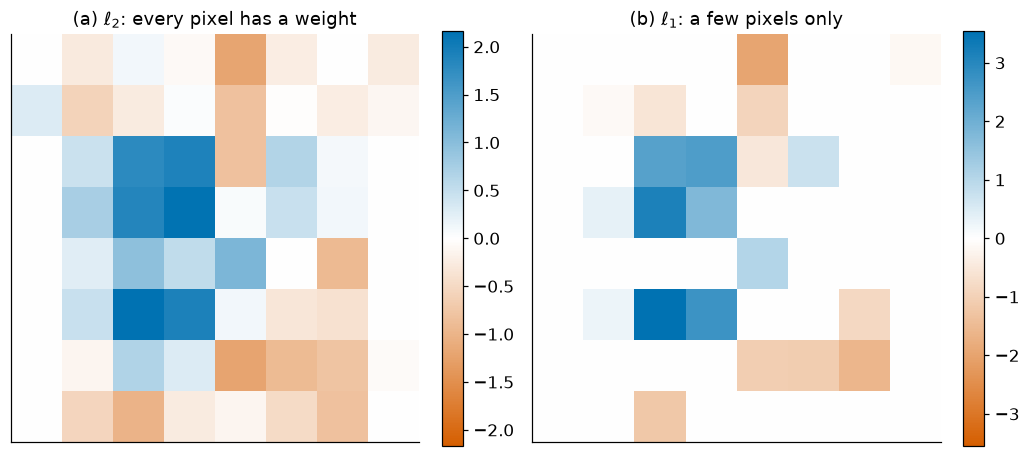

In [39]:
dg_skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
dg_grid = np.logspace(-2.5, 1.5, 17)
dg_cv = {}
for pen, l1r in [("l1", 1.0), ("l2", 0.0)]:
    L = np.zeros((len(dg_grid), 5))
    for f, (tr, va) in enumerate(dg_skf.split(dg_Ztr, dg_ytr)):
        W_, b_ = logit_path(dg_Ztr[tr], dg_ytr[tr], dg_grid, l1r)
        L[:, f] = path_log_loss(dg_Ztr[va], dg_ytr[va], W_, b_)
    dg_cv[pen] = L.mean(axis=1)
print(pd.DataFrame({"C": dg_grid, "l1 CV log loss": dg_cv["l1"], "l2 CV log loss": dg_cv["l2"]}).iloc[::2].round(4).to_string(index=False))
dg_models, rows = {}, []
for pen, l1r in [("l2", 0.0), ("l1", 1.0)]:
    C = dg_grid[int(np.argmin(dg_cv[pen]))]
    m = logit(dg_Ztr, dg_ytr, C, l1r, tol=1e-10)
    dg_models[pen] = m
    rows.append({"penalty": pen, "C chosen by CV": C, "pixels with non-zero weight": int((m.coef_ != 0).sum()),
                 "test log loss": log_loss(dg_yte, m.predict_proba(dg_Zte)[:, 1]), "test errors": f"{int((m.predict(dg_Zte) != dg_yte).sum())} of {len(dg_yte)}"})
print(pd.DataFrame(rows).round(4).to_string(index=False))


def figure_10_11():
    from matplotlib.colors import LinearSegmentedColormap
    cmap = LinearSegmentedColormap.from_list("ov", [VERMILION, "white", BLUE])
    fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.3))
    for ax, pen, title in [(axes[0], "l2", r"(a) $\ell_2$: every pixel has a weight"), (axes[1], "l1", r"(b) $\ell_1$: a few pixels only")]:
        w = dg_models[pen].coef_[0].reshape(8, 8)
        v = np.abs(w).max()
        im = ax.imshow(w, cmap=cmap, vmin=-v, vmax=v)
        ax.set(title=title, xticks=[], yticks=[])
        ax.grid(False)
        fig.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout()
    plt.show()


figure_10_11()

On these data the cross-validated log loss falls with $C$ up to the end of the grid for both penalties ($0.0253$ for $\ell_1$ and $0.0172$ for $\ell_2$ at $C=31.6$): the digits 3 and 8 are almost linearly separable in their 54 informative pixels, so the best penalty is the weakest one that we tried (we stop there: beyond it the curves are nearly flat and `saga` becomes very slow), and the $\ell_2$ curve is below the $\ell_1$ curve at every $C$. The $\ell_2$ model uses all 54 pixels and makes no error on the 90 test images (log loss $0.014$); the $\ell_1$ model uses 21 of them, makes 2 errors (log loss $0.039$), and its weight map in Figure 10.11(b) is a thinned-out version of the $\ell_2$ map, with nonzero weights in the same central region where the $\ell_2$ weights are largest. Two errors against none, on 90 images, is not a difference that the data can confirm; what is clear is that the sparse model costs something in log loss here, while giving a map of 21 pixels that a person can inspect.

## 10.10 Filters, wrappers and embedded methods

The methods of this chapter are *embedded*: the selection happens while the model is fitted, as a by-product of the penalty. Two other families are in common use, and they are worth placing next to it.

| family | how it selects | examples | cost | sees interactions? |
|---|---|---|---|---|
| **filter** | scores each feature on its own, by a statistic computed once, and keeps the best $k$ | correlation, ANOVA $F$-statistic, mutual information | one pass over the features | no: each feature is judged alone |
| **wrapper** | searches over subsets, fitting a model to evaluate each | forward and backward selection, recursive feature elimination (RFE) | many fits of the model | yes, through the model |
| **embedded** | the fit of the model itself sets some weights to zero | lasso, elastic net, $\ell_1$ logistic regression, trees | one path of fits | yes, through the model |

The weakness of a filter on correlated features is easy to predict: if three features measure nearly the same thing and each of them is correlated with the response, the filter keeps all three and wastes the budget of $k$ features. The Breast Cancer data have exactly this structure (radius, perimeter and area of a nucleus are different transformations of its size, measured as a mean, as a standard error and as the worst value in the image). We compare the three families on the 426 training patients with 10-fold cross-validation, with the selection *inside* every fold (the topic of the next section): an $F$-statistic filter, RFE with an $\ell_2$ logistic model (a wrapper), and the $\ell_1$-penalized logistic regression, whose number of features is varied through $C$.

In [40]:
bc_names = bc.feature_names
corr_tr = np.corrcoef(bc_Ztr.T)


def redundancy(S):
    """Largest absolute correlation between two selected features."""
    S = list(S)
    return max(abs(corr_tr[i, j]) for i, j in itertools.combinations(S, 2)) if len(S) > 1 else 0.0


k_sel = 5
filt = SelectKBest(f_classif, k=k_sel).fit(bc_Ztr, bc_ytr)
wrap = RFE(LogisticRegression(max_iter=5000), n_features_to_select=k_sel, step=1).fit(bc_Ztr, bc_ytr)
emb_C = next(C for C in np.logspace(-2.2, -0.3, 200) if (logit(bc_Ztr, bc_ytr, C, 1.0, tol=1e-6).coef_ != 0).sum() >= k_sel)
emb = logit(bc_Ztr, bc_ytr, emb_C, 1.0, tol=1e-10)
chosen = {"filter (F-statistic)": np.flatnonzero(filt.get_support()), "wrapper (RFE)": np.flatnonzero(wrap.get_support()),
          "embedded (l1 logistic)": np.argsort(-np.abs(emb.coef_[0]))[:k_sel]}
for name, S in chosen.items():
    print(f"{name:<24} {', '.join(bc_names[j] for j in S)}")
    print(f"{'':<24} largest correlation between two of the five: {redundancy(S):.3f}")

filter (F-statistic)     mean perimeter, mean concave points, worst radius, worst perimeter, worst concave points
                         largest correlation between two of the five: 0.994
wrapper (RFE)            radius error, worst radius, worst texture, worst area, worst concave points
                         largest correlation between two of the five: 0.983
embedded (l1 logistic)   worst radius, worst concave points, mean concave points, worst texture, worst symmetry
                         largest correlation between two of the five: 0.908


[31 s]
cross-validated log loss of the filter and of RFE, by number of features:
method    filter  wrapper (RFE)
features                       
1.0        0.248          0.217
2.0        0.180          0.150
3.0        0.152          0.153
4.0        0.146          0.153
5.0        0.145          0.109
6.0        0.143          0.109
8.0        0.141          0.104
10.0       0.141          0.096
15.0       0.132          0.095
20.0       0.081          0.083
30.0       0.084          0.084
embedded: mean number of non-zero weights over the folds, and CV log loss
 features  CV log loss  CV accuracy
      2.8        0.151        0.944
      2.7        0.150        0.941
      4.0        0.107        0.962
      4.2        0.110        0.965
      5.1        0.110        0.969
      6.6        0.105        0.962
      7.5        0.101        0.962
      9.0        0.103        0.967
      9.6        0.093        0.967
     12.0        0.090        0.965


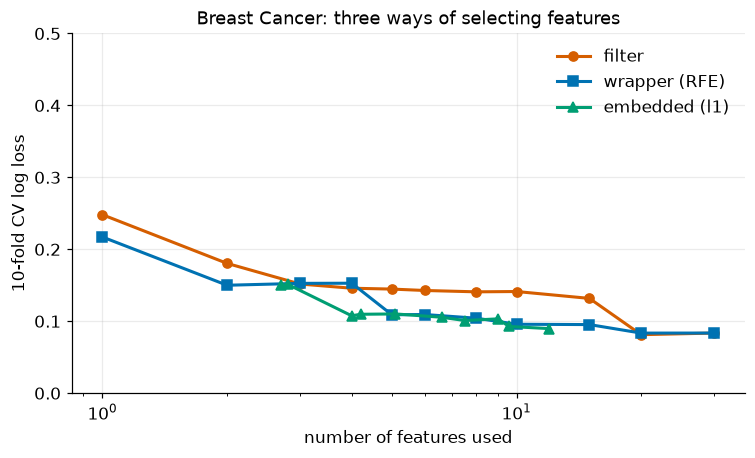

In [41]:
cv10 = StratifiedKFold(10, shuffle=True, random_state=SEED)
ks = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, 30]
rows = []
t0 = time.time()
for k in ks:
    for name, sel in [("filter", SelectKBest(f_classif, k=k)), ("wrapper (RFE)", RFE(LogisticRegression(max_iter=5000), n_features_to_select=k, step=1))]:
        pipe = make_pipeline(StandardScaler(), sel, LogisticRegression(max_iter=5000))
        rows.append({"method": name, "features": k, "CV log loss": -cross_val_score(pipe, bc_Xtr, bc_ytr, cv=cv10, scoring="neg_log_loss").mean(),
                     "CV accuracy": cross_val_score(pipe, bc_Xtr, bc_ytr, cv=cv10, scoring="accuracy").mean()})
for C in np.logspace(-1.9, -0.3, 10):          # embedded: the l1 model selects, an l2 model is fitted on what it selects
    sel_l1 = SelectFromModel(LogisticRegression(l1_ratio=1, C=C, solver="saga", max_iter=20000, tol=1e-6))
    pipe = make_pipeline(StandardScaler(), sel_l1, LogisticRegression(max_iter=5000))
    ll, ac, nz = [], [], []
    for tr, va in cv10.split(bc_Xtr, bc_ytr):
        pipe.fit(bc_Xtr[tr], bc_ytr[tr])
        ll.append(log_loss(bc_ytr[va], pipe.predict_proba(bc_Xtr[va])[:, 1])); ac.append(pipe.score(bc_Xtr[va], bc_ytr[va])); nz.append(int(pipe[1].get_support().sum()))
    rows.append({"method": "embedded (l1)", "features": float(np.mean(nz)), "CV log loss": np.mean(ll), "CV accuracy": np.mean(ac)})
sel_cmp = pd.DataFrame(rows)
print(f"[{time.time() - t0:.0f} s]")
show = sel_cmp[sel_cmp["method"] != "embedded (l1)"].pivot(index="features", columns="method", values="CV log loss")
print("cross-validated log loss of the filter and of RFE, by number of features:")
print(show.round(3).to_string())
print("embedded: mean number of non-zero weights over the folds, and CV log loss")
print(sel_cmp[sel_cmp["method"] == "embedded (l1)"][["features", "CV log loss", "CV accuracy"]].round(3).to_string(index=False))


def figure_10_12():
    fig, ax = plt.subplots(figsize=(7.0, 4.3))
    for name, c, mk in [("filter", VERMILION, "o"), ("wrapper (RFE)", BLUE, "s"), ("embedded (l1)", GREEN, "^")]:
        d = sel_cmp[sel_cmp["method"] == name].sort_values("features")
        ax.plot(d["features"], d["CV log loss"], marker=mk, color=c, lw=2, label=name)
    ax.set(xscale="log", xlabel="number of features used", ylabel="10-fold CV log loss", ylim=(0, 0.5), title="Breast Cancer: three ways of selecting features")
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()


figure_10_12()

The five features chosen by the filter include three that measure the size of the nucleus (`mean perimeter`, `worst radius`, `worst perimeter`), with a correlation of $0.994$ between two of them: the filter scores each feature alone, and all the size features score high. RFE and the $\ell_1$ model pick more varied sets (the largest correlation inside the five is $0.983$ and $0.908$): the elimination and the penalty both look at a feature *given the others*. The cross-validated log loss of Figure 10.12, with the selection inside each fold, shows the cost. With five features the filter has $0.145$ and RFE $0.109$; the $\ell_1$ selection followed by an $\ell_2$ fit has $0.110$ with $5.1$ features on average. The filter stays near $0.14$ from five to ten features, improves slightly at fifteen ($0.132$) and reaches the level of the others only at twenty ($0.081$), when the less redundant features have finally entered. The gap of about $0.035$ is about three standard errors of the cross-validation estimate ($\approx0.01$, Figure 10.10(b)). The difference between RFE and the $\ell_1$ selection is within the noise, and the three families agree when the budget is large: the cost of a filter is paid when features are few and redundant. These are one data set and one 10-fold split, and the cost of RFE (here 30 refits per fold at most) is the reason that it is not used when $p$ is in the thousands, while a single $\ell_1$ path is.

## 10.11 Selection belongs inside the loop

Chapter 2 showed that preprocessing fitted on all the data leaks information from the validation fold, and Section 4.7.2 that `SelectKBest` must be a step of the pipeline. Feature selection is the strongest case of this rule, because it uses the labels. A selector that has seen the label of an example has been *fitted* with it, and any estimate of the error of the final model on that example is optimistic. The experiment below makes the effect as large as possible, in a world in which the right answer is known: real features, **shuffled labels** (flagged in the data note of Section 10.1), so that by construction no feature carries information about the label and every honest method must have an expected accuracy of $50\%$. We take 40 images of the digits 3 and 8 and append 500 columns of Gaussian noise to their 64 pixels, shuffle the labels, keep the 5 features with the largest $F$-statistic, and estimate the accuracy of a logistic regression on them by 5-fold cross-validation, in two ways: selecting the five features *once on all 40 examples* (the leak), or *inside each training fold* (the pipeline). The experiment is repeated 200 times with different images, noise and shuffles.

In [42]:
def leak_experiment(reps=200, n=40, k=5, extra=500):
    leaky, honest = [], []
    warnings.filterwarnings("ignore", message="Features .* are constant")       # some border pixels are constant in a sample of 40 images
    warnings.filterwarnings("ignore", message="invalid value encountered in divide")
    for r in range(reps):
        rg = np.random.default_rng(1000 + r)
        ix = rg.choice(len(dg_X), n, replace=False)
        Xl = np.column_stack([dg_X[ix], rg.normal(size=(n, extra))])
        yl = rg.permutation(np.r_[np.zeros(n // 2, int), np.ones(n // 2, int)])            # independent of the features
        cvl = StratifiedKFold(5, shuffle=True, random_state=r)
        Xsel = StandardScaler().fit_transform(SelectKBest(f_classif, k=k).fit(Xl, yl).transform(Xl))   # selection sees every label
        leaky.append(cross_val_score(LogisticRegression(max_iter=1000), Xsel, yl, cv=cvl).mean())
        pipe = make_pipeline(StandardScaler(), SelectKBest(f_classif, k=k), LogisticRegression(max_iter=1000))
        honest.append(cross_val_score(pipe, Xl, yl, cv=cvl).mean())
    return np.array(leaky), np.array(honest)


t0 = time.time()
leaky, honest = leak_experiment()
print(f"[{time.time() - t0:.0f} s]")
print(pd.DataFrame({"selection": ["on all the data (leak)", "inside each fold (pipeline)"],
                    "mean CV accuracy": [leaky.mean(), honest.mean()], "sd": [leaky.std(), honest.std()],
                    "5th to 95th percentile": [f"{np.percentile(leaky, 5):.2f} to {np.percentile(leaky, 95):.2f}", f"{np.percentile(honest, 5):.2f} to {np.percentile(honest, 95):.2f}"]}).round(3).to_string(index=False))
print(f"repetitions in which the leaky estimate is above 0.70: {np.mean(leaky > 0.70):.0%}; of the honest estimate: {np.mean(honest > 0.70):.0%}")

[6 s]
                  selection  mean CV accuracy    sd 5th to 95th percentile
     on all the data (leak)             0.814 0.055           0.72 to 0.90
inside each fold (pipeline)             0.497 0.103           0.35 to 0.68
repetitions in which the leaky estimate is above 0.70: 97%; of the honest estimate: 4%


The result is as large as the theory allows. Selecting the features on all the data first makes a classifier with *no information whatsoever* about the label look like one that is right four times in five: the mean cross-validated accuracy is $0.81$ (the 5th to 95th percentiles are $0.72$ and $0.90$), and in $97\%$ of the repetitions it exceeds $0.70$. Selecting inside the folds gives $0.497$, the right answer, with a wide spread ($0.35$ to $0.68$: 40 examples do not allow a precise estimate) in which only $4\%$ of the repetitions exceed $0.70$. The mechanism is the one of Section 2.7: the five features that the selector kept are those that, by chance, separate the 40 labels best, and they separate them in the validation folds too because the validation labels took part in the choice. With 564 candidate features and 40 examples there are always five that look informative.

The same mistake has a second form, which concerns **statistical tests** and not predictions. After the data have chosen the feature that looks best, the usual $p$-value of that feature is not a $p$-value any more: it is the smallest of several, and it is small more often than $5\%$ of the time even when nothing is there. We measure it on the ten real Diabetes features with *shuffled responses*, so that the null hypothesis holds for every feature. In each of 5,000 shuffles we pick the feature with the largest $\lvert t\rvert$ and report its ordinary $p$-value, computed (i) on the same data (the naive procedure), or (ii) on a *disjoint half* of the patients that did not take part in the choice (**data splitting**).

                          p-value of the selected feature  fraction of shuffles with p < 0.05  mean p-value
                                        naive (same data)                               0.324         0.121
data splitting (selection on one half, test on the other)                               0.058         0.491


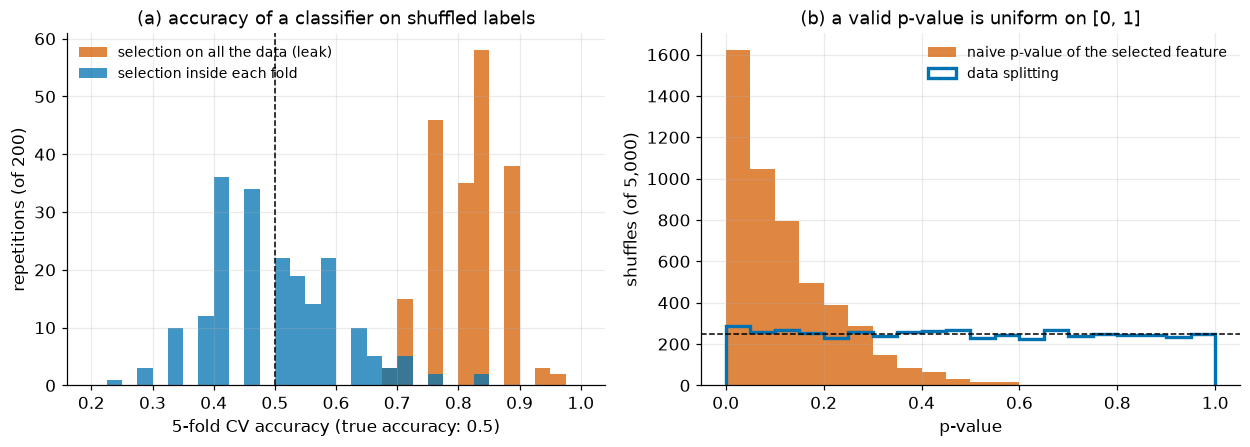

In [43]:
ps_rng = np.random.default_rng(SEED + 5)
Xall = StandardScaler().fit_transform(diab.data)
n_all = len(Xall)


def best_feature_p(X, y):
    r = (X - X.mean(0)).T @ (y - y.mean()) / (len(y) * X.std(0) * y.std())
    t = r * np.sqrt((len(y) - 2) / (1 - r ** 2))
    j = int(np.argmax(np.abs(t)))
    return j, 2 * stats.t.sf(abs(t[j]), len(y) - 2)


naive, split = [], []
for _ in range(5000):
    yp = ps_rng.permutation(diab.target)
    naive.append(best_feature_p(Xall, yp)[1])
    h = ps_rng.permutation(n_all)
    j, _ = best_feature_p(Xall[h[:n_all // 2]], yp[h[:n_all // 2]])
    xj = Xall[h[n_all // 2:], j]; yj = yp[h[n_all // 2:]]
    r = np.corrcoef(xj, yj)[0, 1]
    split.append(2 * stats.t.sf(abs(r * np.sqrt((len(yj) - 2) / (1 - r ** 2))), len(yj) - 2))
naive, split = np.array(naive), np.array(split)
print(pd.DataFrame({"p-value of the selected feature": ["naive (same data)", "data splitting (selection on one half, test on the other)"],
                    "fraction of shuffles with p < 0.05": [np.mean(naive < 0.05), np.mean(split < 0.05)],
                    "mean p-value": [naive.mean(), split.mean()]}).round(3).to_string(index=False))


def figure_10_13():
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
    ax = axes[0]
    bins = np.linspace(0.2, 1.0, 33)
    ax.hist(leaky, bins=bins, color=VERMILION, alpha=0.75, label="selection on all the data (leak)")
    ax.hist(honest, bins=bins, color=BLUE, alpha=0.75, label="selection inside each fold")
    ax.axvline(0.5, color="black", lw=1, ls="--")
    ax.set(xlabel="5-fold CV accuracy (true accuracy: 0.5)", ylabel="repetitions (of 200)", title="(a) accuracy of a classifier on shuffled labels")
    ax.legend(frameon=False, fontsize=9, loc="upper left")
    ax = axes[1]
    b = np.linspace(0, 1, 21)
    ax.hist(naive, bins=b, color=VERMILION, alpha=0.75, label="naive p-value of the selected feature")
    ax.hist(split, bins=b, histtype="step", color=BLUE, lw=2.2, label="data splitting")
    ax.axhline(5000 / 20, color="black", lw=1, ls="--")
    ax.set(xlabel="p-value", ylabel="shuffles (of 5,000)", title="(b) a valid p-value is uniform on [0, 1]")
    ax.legend(frameon=False, fontsize=9, loc="upper right")
    fig.tight_layout()
    plt.show()


figure_10_13()

Panel (b) of Figure 10.13 is the answer. The naive $p$-value of the best of ten features is below $0.05$ in $32\%$ of the shuffles (for ten *independent* features it would be $1-0.95^{10}=40\%$; the features are correlated, which lowers the rate) and its mean is $0.12$ instead of $0.5$: the distribution piles up at zero. With data splitting the rate is $5.8\%$, close to the nominal $5\%$ (the Monte Carlo error is $0.3$ points, and the $t$ distribution is only approximately valid for the skewed response of Diabetes), and the $p$-values are uniform, with mean $0.49$. The price of data splitting is half of the data for each step; the point is that selection and testing must not use the same data.

The rule that follows is the one of Section 2.7 with a higher price. **Everything that looks at the labels belongs inside the loop**: the choice of $\lambda$ (and $\alpha$) by cross-validation, the selector of a filter, the elimination steps of RFE, the refit on the selected support. If the final model is also to be *evaluated*, the loop must be nested (Section 5.4.3): an inner cross-validation chooses $\lambda$ on the training part of each outer fold, and the outer fold, never seen by the inner one, estimates the error. In code,

```python
pipe = make_pipeline(StandardScaler(), SelectFromModel(LassoCV(cv=5)), Ridge(alpha=1.0))
score = cross_val_score(pipe, X, y, cv=KFold(5, shuffle=True, random_state=0))
```

estimates the error of the whole *procedure* "choose $\lambda$ by cross-validation, keep the features with non-zero weights, fit a ridge on them", every step of which sees only the training part of each fold. What the pipeline does not give is a valid confidence statement about the *selected* coefficients (their standard errors and $p$-values), which needs methods designed for it: data splitting as above, or the post-selection inference of Lee, Sun, Sun and Taylor (2016) in the further reading.

## 10.12 Summary

- **Sparse models (Section 10.2).** A sparse model uses few of the $p$ features ($\lVert\mathbf{w}\rVert_0=s$ non-zero weights). The reasons are interpretation, cost and, when $p$ is large compared with $n$, estimation error: least squares pays $\sigma^2p/n$ (Theorem 6.1) and a model that knows the support pays $\sigma^2 s/n$. The number of supports is $\binom ps$: $1.7\times10^{13}$ for $p=100$, $s=10$.
- **Best subset (Section 10.3).** On the ten Diabetes features the exhaustive search takes a fraction of a second. The training error falls with the size ($\mathrm{RSS}$ is nested, Proposition 10.1) and cannot choose it; $C_p$, the BIC and cross-validation choose $7$, $6$ and $7$ features, and the one-standard-error rule $5$ (`sex`, `bmi`, `bp`, `s3`, `s5`). The effective degrees of freedom of a *searched* subset exceed its size (Proposition 10.2): the best single feature out of ten has $3.4$, not $1$. Forward selection finds the best subset for sizes 1 to 5 and 9 and 10 and misses it for 6 to 8.
- **Greedy pursuit (Section 10.4).** OMP recovers the true support if the exact recovery condition holds (Theorem 10.4), and in particular if the coherence satisfies $\mu(2s-1)<1$ (Corollary 10.5). On the real, correlated Diabetes features the coherence is $0.893$ and the conditions are vacuous; on a Gaussian design OMP needs more examples than the oracle lasso path to recover the support ($n=30$: $0.73$ against $1.00$).
- **The lasso (Section 10.5).** The $\ell_1$ penalty is the convex relaxation of $\lVert\mathbf{w}\rVert_0$, and its ball has corners on the axes, where the solutions are. For an orthonormal design the solution is soft-thresholding (Proposition 10.6); in general it is characterized by $\frac1n\mathbf{x}_j^\top\mathbf{r}=\lambda\operatorname{sign}(w_j)$ on the active set and $\lvert\frac1n\mathbf{x}_j^\top\mathbf{r}\rvert\le\lambda$ off it (Theorem 10.7), which gives $\lambda_{\max}=\frac1n\lVert\mathbf{X}^\top\mathbf{y}\rVert_\infty$ ($45.97$ on Diabetes). The path is piecewise linear with $15$ knots for $10$ features and is *not monotone*: `s2` and `s3` leave the model and re-enter. The penalty is a Laplace prior, and it biases the non-zero weights toward zero (Section 10.5.6).
- **Algorithms (Section 10.6).** Coordinate descent (Proposition 10.8) is exact in each step and reaches $10^{-9}$ in $15$ sweeps; proximal gradient (ISTA, Proposition 10.9, Theorem 10.10, rate $O(1/k)$) needs $92$ iterations and FISTA gains only at low accuracy, because the problem restricted to the active set is well conditioned ($\kappa_S\approx5$ against $\kappa=418$). The subgradient method never reaches $10^{-3}$ after 2,000 iterations and never produces a zero. The path with warm starts is the standard way to compute the lasso.
- **Choosing $\lambda$ and what it buys (Section 10.7).** Cross-validation gives nine features at the minimum and five at the one-SE value, the same five as best subset. The degrees of freedom of the lasso equal the expected number of non-zero weights (Proposition 10.11 in the orthonormal case, checked by Monte Carlo on the real design). On the test patients all methods are within $0.9$ RMSE points and, over 30 splits, least squares, ridge and the lasso are indistinguishable ($54.9$, $55.0$, $54.9$): **sparsity costs nothing in prediction and gains nothing when $p=10$ and $n=331$**; the one-SE rule costs about $1.3$ points for $4.6$ features instead of $8.2$, a difference the data do not resolve. The quadratic features do not help either (the single-split gain of $2.2$ points vanishes over 30 splits). The benefit of $\ell_1$ appears when most features are useless: with 1,000 noise columns ridge goes from $56.4$ to $72.8$ and the lasso from $56.9$ to $60.6$, in agreement with the slow-rate bound (Theorem 10.12), in which the number of features enters only through $\ln p$.
- **Elastic net (Section 10.8).** Adding a ridge penalty gives a strictly convex problem, solved by any lasso solver on augmented data (Proposition 10.13), and the grouping effect (Theorem 10.14): two selected features with correlation $\rho$ differ by at most $\frac{\lVert\mathbf{y}\rVert}{\sqrt n\lambda_2}\sqrt{2(1-\rho)}$. Where the lasso, on a feature and its noisy twin, keeps only one of the two in $67\%$ of the bootstrap samples, the elastic net keeps both in all of them and with almost equal weights. The selected sets of the elastic net are more reproducible between five and eight features, though not uniformly, and reproducible is not the same as true.
- **Sparse classification (Section 10.9).** The $\ell_1$-penalized logistic regression has its own $\lambda_{\max}$ (Proposition 10.15). On Breast Cancer it matches ridge on prediction (3 to 5 errors in 143, indistinguishable) and keeps $12$ of the $30$ features, which are correlated versions of $10$ measurements. For the $\ell_2$ penalty the weights lie in the row space of the data (Theorem 9.4); for $\ell_1$ they do not ($43\%$ of the length of the weights lies outside it on $n=40$ images of Digits): the kernel trick does not apply.
- **Filters, wrappers, embedded (Section 10.10).** A filter judges each feature alone and keeps redundant ones (three of its five Breast Cancer features measure the size of the nucleus); with the selection inside the folds, at five features its cross-validated log loss is $0.145$ against $0.109$ for RFE and $0.110$ for the $\ell_1$ selection, and the three families agree again from twenty features on.
- **Selection inside the loop (Section 10.11).** On shuffled labels, selecting five features out of 564 on all the data and then cross-validating gives an accuracy of $0.81$ for a classifier with no information, against $0.497$ with the selection inside each fold; the naive $p$-value of the best of ten features is below $0.05$ in $32\%$ of the shuffles, and $5.8\%$ with data splitting. Everything that looks at the labels belongs inside the loop (choice of $\lambda$, selector, refit); evaluating the whole procedure needs a nested loop.
- **Where this leaves gradient methods (Section 7.7.2).** Early stopping of gradient descent acts like an $\ell_2$ penalty; the analogue for $\ell_1$ is stagewise forward selection with tiny steps, whose path approximates the lasso path (Efron *et al.*, 2004, in the further reading). Plain gradient descent on the lasso objective is not an option because of the kink at zero: the proximal and coordinate methods exist for that reason.

:::{admonition} Which tool for which situation
:class: tip
| situation | start with | reason |
|---|---|---|
| $p$ small compared with $n$, prediction is the goal | ridge or least squares | nothing to gain from sparsity (Section 10.7.4) |
| many features, most of them probably useless | lasso, $\lambda$ by cross-validation | error grows with $\ln p$, not $p$ (Theorem 10.12) |
| correlated groups of features, and the *set* matters | elastic net ($\ell_1$ ratio by cross-validation) | grouping effect, unique solution (Theorem 10.14) |
| a short, interpretable model is required | lasso with the one-SE rule, then refit on the support | smaller model for a cost the data do not resolve; the refit removes the shrinkage bias |
| $p\ge n$ and exact support recovery matters | stability selection (Exercise 10.9), not a single lasso fit | the selected set of a single fit is a coin toss among correlated features |
| $\ell_1$ classification | `LogisticRegression(l1_ratio=1, solver="saga")` on standardized features | the same ideas with the log loss |
| any selection step | inside the pipeline and the folds | the labels leak otherwise (Section 10.11) |
:::

### Data sources

- *Diabetes*: B. Efron, T. Hastie, I. Johnstone and R. Tibshirani, "Least Angle Regression", *Annals of Statistics* 32(2), 407–499 (2004). Bundled with scikit-learn. The 331/111 split of Chapters 6, 7 and 9.
- *Breast Cancer Wisconsin (Diagnostic)*: W. N. Street, W. H. Wolberg and O. L. Mangasarian, "Nuclear feature extraction for breast tumor diagnosis", *IS&T/SPIE 1993 International Symposium on Electronic Imaging: Science and Technology*, volume 1905, 861–870 (1993). Bundled with scikit-learn. Malignant $=1$; the stratified 426/143 split of Chapters 6 to 9.
- *Digits*: E. Alpaydin and C. Kaynak, "Optical Recognition of Handwritten Digits", UCI Machine Learning Repository (1998). Bundled with scikit-learn; only the digits 3 and 8 are used.
- *Wine*: M. Forina *et al.*, "PARVUS: An Extendible Package for Data Exploration, Classification and Correlation", Institute of Pharmaceutical and Food Analysis and Technologies, Genoa (1991), UCI Machine Learning Repository. Bundled with scikit-learn (Exercises 10.6 to 10.8).
- *Constructed and simulated data* (flagged in the text): the Gaussian design of the support-recovery experiment (Section 10.4); the simulated world on the real Diabetes design used to check the degrees of freedom (Section 10.7.2); the noise columns appended to real features (Sections 10.7.4 and Exercises 10.8 to 10.10); the noisy twin of `bmi` (Section 10.8); the shuffled labels of Section 10.11; and the small numerical examples of the manual exercises. Every other experiment uses the real data sets above.

### Further reading

- R. Tibshirani, "Regression shrinkage and selection via the lasso", *Journal of the Royal Statistical Society B* 58(1), 267–288 (1996). The paper that introduced the lasso.
- T. Hastie, R. Tibshirani and M. Wainwright, *Statistical Learning with Sparsity: The Lasso and Generalizations*, CRC Press, 2015 (free online). The reference for the whole chapter: algorithms, the elastic net, generalizations and theory.
- B. Efron, T. Hastie, I. Johnstone and R. Tibshirani, "Least angle regression", *Annals of Statistics* 32(2), 407–499 (2004), and M. R. Osborne, B. Presnell and B. A. Turlach, "A new approach to variable selection in least squares problems", *IMA Journal of Numerical Analysis* 20(3), 389–403 (2000). The piecewise-linear path and the algorithm that computes it; LARS also makes the link to stagewise regression.
- J. Friedman, T. Hastie and R. Tibshirani, "Regularization paths for generalized linear models via coordinate descent", *Journal of Statistical Software* 33(1), 1–22 (2010). The coordinate descent with warm starts of Section 10.6, for the lasso, the elastic net and $\ell_1$ logistic regression.
- A. Beck and M. Teboulle, "A fast iterative shrinkage-thresholding algorithm for linear inverse problems", *SIAM Journal on Imaging Sciences* 2(1), 183–202 (2009). FISTA (Section 10.6).
- H. Zou and T. Hastie, "Regularization and variable selection via the elastic net", *Journal of the Royal Statistical Society B* 67(2), 301–320 (2005). The elastic net and the grouping effect (Theorem 10.14).
- B. K. Natarajan, "Sparse approximate solutions to linear systems", *SIAM Journal on Computing* 24(2), 227–234 (1995). NP-hardness of best subset selection. Y. C. Pati, R. Rezaiifar and P. S. Krishnaprasad, "Orthogonal matching pursuit", *Asilomar Conference on Signals, Systems and Computers*, 1993, and J. A. Tropp, "Greed is good: algorithmic results for sparse approximation", *IEEE Transactions on Information Theory* 50(10), 2231–2242 (2004). OMP and the exact recovery condition (Theorem 10.4).
- P. J. Bickel, Y. Ritov and A. B. Tsybakov, "Simultaneous analysis of Lasso and Dantzig selector", *Annals of Statistics* 37(4), 1705–1732 (2009), and M. J. Wainwright, *High-Dimensional Statistics: A Non-Asymptotic Viewpoint*, Cambridge University Press, 2019. The fast rate $s\ln p/n$ under the restricted eigenvalue condition, which Theorem 10.12 does not need.
- H. Zou, T. Hastie and R. Tibshirani, "On the degrees of freedom of the lasso", *Annals of Statistics* 35(5), 2173–2192 (2007), and R. J. Tibshirani and J. Taylor, "Degrees of freedom in lasso problems", *Annals of Statistics* 40(2), 1198–1232 (2012). Proposition 10.11 for general designs. C. M. Stein, "Estimation of the mean of a multivariate normal distribution", *Annals of Statistics* 9(6), 1135–1151 (1981): the lemma used in its proof.
- N. Meinshausen and P. Bühlmann, "Stability selection", *Journal of the Royal Statistical Society B* 72(4), 417–473 (2010) (Exercise 10.9), and J. D. Lee, D. L. Sun, Y. Sun and J. E. Taylor, "Exact post-selection inference, with application to the lasso", *Annals of Statistics* 44(3), 907–927 (2016) (the invalid $p$-values of Section 10.11).
- I. Guyon and A. Elisseeff, "An introduction to variable and feature selection", *Journal of Machine Learning Research* 3, 1157–1182 (2003). Filters, wrappers and embedded methods (Section 10.10). C. Ambroise and G. J. McLachlan, "Selection bias in gene extraction on the basis of microarray gene-expression data", *Proceedings of the National Academy of Sciences* 99(10), 6562–6566 (2002), and T. Hastie, R. Tibshirani and J. Friedman, *The Elements of Statistical Learning*, 2nd ed., Springer, 2009, Sections 3.3 to 3.4 and 7.10.2: the leak of selecting outside the loop.

## 10.13 Exercises

Difficulty: ★ warm-up, ★★ core, ★★★ challenge. Try each exercise before reading the hint; solutions and detailed outlines are in [Appendix C](../appendices/appendix_c_solutions.ipynb).

### Manual (analytical) exercises

**Exercise 10.1 ★ — Four estimators by hand.** (Constructed numbers.) For an orthonormal design, $\frac1n\mathbf{Z}^\top\mathbf{Z}=\mathbf{I}$, the least-squares weights are $\hat{\mathbf{w}}^{\rm ols}=(4, -2.5, 1.2, -0.6, 0.2)$. Write the weights of (a) the lasso with $\lambda=1$, (b) ridge regression with $\lambda_2=1$, (c) best subset of size 2, (d) the elastic net with $\lambda_1=\lambda_2=1$. (e) For which values of $\lambda$ does the lasso keep exactly two weights, and by how much are they biased with respect to those of (c)?

*Hint.* The lasso is $S_\lambda(\hat w^{\rm ols}_j)$ (Proposition 10.6), ridge is $\hat w^{\rm ols}_j/(1+\lambda_2)$, best subset keeps the two largest in absolute value; for (d) use Exercise 10.4.

**Exercise 10.2 ★★ — A two-feature lasso path.** (Constructed numbers.) Standardized features with $\frac1n\mathbf{z}_1^\top\mathbf{z}_2=\rho=0.5$ and $\frac1n\mathbf{Z}^\top\mathbf{y}=(c_1,c_2)=(0.8,0.6)$. (a) Find $\lambda_{\max}$ and the first feature to enter. (b) Find the value of $\lambda$ at which the second feature enters, and the weights for every $\lambda$ from $\lambda_{\max}$ down to $0$; check that they reach the least-squares solution. (c) Repeat (b) with $c_2=0.3$: when does the second feature enter, with which sign, and how does this compare with the sign changes of `s3` along the path of Figure 10.5?

*Hint.* With only feature 1 active, $\hat w_1=c_1-\lambda$. Feature 2 enters when $\lvert c_2-\rho\hat w_1\rvert=\lambda$ (Theorem 10.7). With both active solve $\begin{pmatrix}1&\rho\\\rho&1\end{pmatrix}\mathbf{w}=\mathbf{c}-\lambda\,\mathbf{s}$ with the signs $\mathbf{s}$.

**Exercise 10.3 ★★ — Repeated columns.** Let two columns of $\mathbf{Z}$ be identical, $\mathbf{z}_j=\mathbf{z}_k$. (a) Show that the data term of the objective depends on $w_j$ and $w_k$ only through $w_j+w_k$. (b) Show that if $\hat{\mathbf{w}}$ is a lasso solution with $\hat w_j\hat w_k\ge0$, then moving weight between the two coordinates, keeping their sum and their sign, gives other solutions: the set of lasso solutions contains a segment. (c) Show that the elastic net with $\lambda_2>0$ has the unique solution $\hat w_j=\hat w_k$, and say how this agrees with Theorem 10.14.

*Hint.* (b) $\lvert w_j\rvert+\lvert w_k\rvert=\lvert w_j+w_k\rvert$ when the two have the same sign. (c) For a fixed sum $s=w_j+w_k$, $w_j^2+w_k^2\ge s^2/2$ with equality only at $w_j=w_k$.

**Exercise 10.4 ★★ — The elastic net for an orthonormal design.** With $\frac1n\mathbf{Z}^\top\mathbf{Z}=\mathbf{I}$, (a) show that the elastic net solution is $\hat w_j = S_{\lambda_1}(\hat w_j^{\rm ols})/(1+\lambda_2)$. (b) Show that the factor $1+\lambda_2$ is a second shrinkage on top of that of the lasso, and that in this case the elastic net rescaled by $1+\lambda_2$ is the lasso with the same $\lambda_1$. (c) Explain why this does not contradict Theorem 10.14: what does the grouping effect need that an orthonormal design does not have?

*Hint.* The objective separates by coordinates: minimize $\frac12(w-a)^2+\lambda_1\lvert w\rvert+\frac{\lambda_2}2w^2$, i.e. $\frac{1+\lambda_2}{2}\big(w-\frac a{1+\lambda_2}\big)^2+\lambda_1\lvert w\rvert+{\rm const}$.

**Exercise 10.5 ★★★ — The lasso path is piecewise linear.** Let $A$ be the active set and $\mathbf{s}_A$ the signs on an interval of $\lambda$ over which neither changes. (a) Show that on the interval $\hat{\mathbf{w}}_A(\lambda)=\boldsymbol\theta-\lambda\mathbf{u}$ with $\boldsymbol\theta=(\frac1n\mathbf{Z}_A^\top\mathbf{Z}_A)^{-1}\frac1n\mathbf{Z}_A^\top\mathbf{y}$ and $\mathbf{u}=(\frac1n\mathbf{Z}_A^\top\mathbf{Z}_A)^{-1}\mathbf{s}_A$. (b) Give the value of $\lambda$ at which an inactive feature $j$ enters, and the value at which an active feature $k$ leaves. (c) Apply the formulas to Exercise 10.2 and recover the knots. (d) Explain why the number of knots can exceed $p$ (the Diabetes path had 15 knots for 10 features).

*Hint.* (a) is (10.5) on the active set. (b) For $j\notin A$ the correlation with the residual is $c_j(\lambda)=a_j+\lambda b_j$, affine in $\lambda$, with $a_j=\frac1n\mathbf{z}_j^\top(\mathbf{y}-\mathbf{Z}_A\boldsymbol\theta)$ and $b_j=\frac1n\mathbf{z}_j^\top\mathbf{Z}_A\mathbf{u}$; it enters when $c_j=\pm\lambda$. An active coordinate leaves when $\theta_k-\lambda u_k=0$. (d) Features may leave and re-enter.

### Python (computational) exercises

**Exercise 10.6 ★ — The lasso on Wine.** Use the Wine data (`load_wine`) as a regression problem: predict `alcohol` from the other 12 features, with a $75\%/25\%$ split (`random_state=SEED`) and the features standardized with the training statistics. (a) Compute the lasso path with `lasso_path` and plot it. (b) Choose $\lambda$ by 10-fold cross-validation (minimum and one-SE rule) and by the AIC and the BIC (`LassoLarsIC`); list the selected features for each. (c) Compare the test RMSE of least squares, ridge (`RidgeCV`) and the two lasso models, and verify the optimality conditions of Theorem 10.7 for the lasso at the CV minimum.

*Hint.* `LassoCV(alphas=100)` gives the grid and `mse_path_`; the one-SE rule needs the mean and standard error across folds; the KKT check is $\frac1n\mathbf{Z}^\top\mathbf{r}=\lambda\operatorname{sign}(\hat{\mathbf{w}})$ on the active set and $\lvert\frac1n\mathbf{Z}^\top\mathbf{r}\rvert\le\lambda$ elsewhere.

**Exercise 10.7 ★★ — Elastic net by coordinate descent.** Implement cyclic coordinate descent for the elastic net, with the update $w_j\leftarrow S_{\lambda_1}(\rho_j)/(1+\lambda_2)$ ($\rho_j$ the partial-residual correlation, Proposition 10.8 and Exercise 10.4), and the objective gap as the stopping rule. (a) Check it against `ElasticNet` on the Wine problem of Exercise 10.6. (b) On the 65 quadratic features of Diabetes (standardized, the 331 training patients), count the sweeps needed to bring the gap below $10^{-10}$ for $\lambda_2\in\{0, 0.1, 1\}$ with $\lambda_1=1$. Why does the number decrease with $\lambda_2$?

*Hint.* Keep the residual up to date: after changing $w_j$ by $\delta$, subtract $\delta\,\mathbf{z}_j$ from it. The extra term adds $\lambda_2$ to the smallest eigenvalue of the Hessian, which makes the problem strongly convex (Theorem 7.5).

**Exercise 10.8 ★★ — Noise columns on Wine.** On the Wine regression of Exercise 10.6, append $m\in\{0, 10, 100, 1000\}$ columns of Gaussian noise (a constructed addition, as in Section 4.7.2) and compare, over 20 random splits, least squares (when $p<n_{\rm train}$), ridge, the lasso at its CV minimum and the elastic net with $\ell_1$ ratio $0.5$, all with $\lambda$ chosen by 5-fold cross-validation: test RMSE, and the number of noise columns selected. Does the error of the lasso grow with $\ln p$ rather than with $p$, as Theorem 10.12 suggests?

*Hint.* `ElasticNetCV(l1_ratio=0.5, cv=5)`; plot the RMSE against $\ln(12+m)$ and against $12+m$; the noise is generated once per split and the columns are standardized with the training statistics.

**Exercise 10.9 ★★★ — Stability selection.** On the 331 Diabetes training patients with 20 appended noise columns (constructed), (a) fit the lasso at the one-SE value of $\lambda$ of the full training set on 100 random half-samples (drawn without replacement) and record the selection frequency of each of the 30 columns; (b) keep the columns with frequency at least $0.7$ and count the real features and the noise columns selected, and compare with the lasso at the one-SE value fitted once on the full training set; (c) repeat with the elastic net with $\ell_1$ ratio $0.5$, whose penalty is chosen by the one-SE rule on the full training set too. Which noise columns does each method select, and how often?

*Hint.* Meinshausen and Bühlmann (2010) show that the expected number of false selections is bounded when the frequency threshold and the number of selections per half-sample are controlled; here we only measure it. Use `rng.choice(n, n // 2, replace=False)`.

**Exercise 10.10 ★★★ — The winner's curse of $\lambda$.** Take 60 random patients of Diabetes, append 200 noise columns (constructed) and **shuffle the response**, so that no feature carries information. (a) For 30 repetitions compute the minimum of the cross-validated error of `LassoCV` over the grid of $\lambda$ (the number that people usually report) and compare it with the error of the null model, the variance of the response. (b) Estimate the error of the *whole procedure* "choose $\lambda$ by 5-fold cross-validation, fit the lasso" by an outer 5-fold cross-validation with `LassoCV` inside it (nested), and compare. Which of the two is honest, and what does the other one say about the winner's curse of Section 5.4.3?

*Hint.* With no signal the best achievable mean squared error is the variance of the response; any estimate below it is optimistic. In the nested loop `LassoCV` is fitted only on the training part of each outer fold.

## What comes next

We have now seen two ways to control a linear model with many features: shrinking all the weights (ridge) and setting most of them to zero (the $\ell_1$ penalty and the selection methods built on it). Both keep the model *linear in the features*, and both make the same assumption, that the effect of a feature is the same everywhere in the data. **Chapter 11** abandons it. A decision tree splits the feature space into boxes by a sequence of thresholds on single features, and in doing so selects features adaptively, region by region, ignores irrelevant ones without a penalty (the observation of Section 4.7.2 turned into a method), and needs no scaling (the lesson of Section 9.6.4 and Exercise 9.8). Single trees have high variance, and the remedy is the subject of the second half of the chapter: bagging, random forests and boosting, the last being gradient descent in a space of functions (the loop of Chapter 7, with trees as the steps). Their probabilities are typically badly calibrated, which is the situation of Sections 5.6.4 and 8.7.3, and the feature importances that forests report face the problem of this chapter again: correlated features share the credit, and selecting on the importance outside the loop leaks the labels.